# BCSE331P – Exploratory Data Analysis | Lab Assessments 1 – 9

| | |
|---|---|
| **Name** | Sai Siddhanth |
| **Registration Number** | 23BDS0173 |
| **Course** | BCSE331P – Exploratory Data Analysis (Lab) |
| **Language / Environment** | Python 3 on Google Colab |
| **Dataset** | Mroz (1987) – `https://raw.githubusercontent.com/salemprakash/EDA/main/Data/mroz.csv` |

This single notebook answers all nine lab assessments. The question papers were written for R; every task is implemented here with its closest Python equivalent, and wherever a question uses a built-in R dataset (for example `AirPassengers` in Assessment 6), the same workflow is applied to the Mroz dataset as instructed.

### Contents
1. Assessment 1 – Merging and Data Transformation
2. Assessment 2 – Data Import, Transform and Basic Statistical Analysis
3. Assessment 3 – Data Cleaning and Univariate Analysis
4. Assessment 4 – Bivariate Analysis
5. Assessment 5 – Multivariate Analysis
6. Assessment 6 – Time Series Analysis
7. Assessment 7 – 1-D, 2-D and N-D Analysis
8. Assessment 8 – K-Means and Hierarchical Clustering
9. Assessment 9 – Principal Component Analysis

## About the dataset

The **Mroz dataset** (T. A. Mroz, *Econometrica*, 1987) comes from the 1975 wave of the Panel Study of Income Dynamics (PSID). It describes **753 married white women aged 30–60** and is the classic dataset for studying women's labour-force participation and wages. It has 23 columns; `rownames` is only the row identifier carried over from R.

| Variable | Meaning | Variable | Meaning |
|---|---|---|---|
| `inlf` | 1 if the woman was in the labour force in 1975 | `huseduc` | Husband's years of schooling |
| `hours` | Hours worked by the wife in 1975 | `huswage` | Husband's hourly wage (\$) |
| `kidslt6` | Number of children younger than 6 | `faminc` | Family income in 1975 (\$) |
| `kidsge6` | Number of children aged 6–18 | `mtr` | Federal marginal tax rate variable (behaves as 1 − rate; see Assessment 7) |
| `age` | Wife's age in years | `motheduc` | Mother's years of schooling |
| `educ` | Wife's years of schooling | `fatheduc` | Father's years of schooling |
| `wage` | Wife's average hourly wage (\$), only for workers | `unem` | Unemployment rate in county of residence (%) |
| `repwage` | Reported wage at the 1976 interview | `city` | 1 if the family lives in an SMSA (urban area) |
| `hushrs` | Hours worked by the husband in 1975 | `exper` | Wife's years of labour-market experience |
| `husage` | Husband's age | `nwifeinc` | Non-wife family income, (faminc − wage·hours)/1000 |
| `lwage` | log(`wage`), only for workers | `expersq` | `exper` squared |

**Important property:** `wage` and `lwage` are missing for the 325 women who did not work in 1975, because a wage is only observed for women who participate. This *genuine* missingness is used throughout the data-cleaning assessments.

**Derived labels used in several assessments.** The raw file is entirely numeric, so readable categorical variables are derived from the coded columns:

| Derived variable | Rule |
|---|---|
| `LF_Status` | `inlf` 1 → *Participant*, 0 → *Non-participant* |
| `Residence` | `city` 1 → *Urban*, 0 → *Rural* |
| `Young_Kids` | *Has child <6* if `kidslt6` > 0, else *No child <6* |
| `Edu_Level` | `educ` ≤ 11 *Below HS*, 12 *High School*, 13–15 *Some College*, 16–17 *College+* |
| `Age_Group` | 30–39, 40–49, 50–60 |

## Environment setup

The R packages named in the question papers map to Python libraries as follows:

| R | Python |
|---|---|
| `read.csv`, `dplyr`, `tidyr`, `stringr`, `forcats` | `pandas` |
| `zoo::na.locf` | `pandas.DataFrame.ffill` / `bfill` |
| base graphics, `ggplot2`, `ggfortify` | `matplotlib`, `seaborn` (and `seaborn.objects`, a grammar-of-graphics interface modelled on ggplot2) |
| `e1071::skewness`, `e1071::kurtosis` | Implemented exactly (type 3, the e1071 default) with `numpy` |
| `stats::arima`, `acf`, `pacf`, `decompose` | `statsmodels` |
| `kmeans`, `dist`, `hclust`, `cutree` | `scikit-learn`, `scipy.cluster.hierarchy` |
| `prcomp`, `FactoMineR::PCA`, `factoextra` | `sklearn.decomposition.PCA` + custom scree plot and biplot |
| `ggrepel` (non-overlapping labels) | `adjustText` |

`adjustText` is not pre-installed on Colab, so it is installed first. The helper `add_labels()` creates the derived categorical variables described above, and `URL` holds the dataset link so every assessment can reload a fresh copy.

In [1]:
!pip -q install adjustText

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn.objects as so
import scipy
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
import statsmodels
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import sklearn
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from adjustText import adjust_text
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}" if abs(v) >= 1000 else f"{v:.4f}")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 5), "figure.dpi": 110, "axes.titleweight": "bold"})

URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/mroz.csv"
NAME = "Sai Siddhanth"
REG_NO = "23BDS0173"


def add_labels(df):
    out = df.copy()
    out["LF_Status"] = out["inlf"].map({1: "Participant", 0: "Non-participant"})
    out["Residence"] = out["city"].map({1: "Urban", 0: "Rural"})
    out["Young_Kids"] = np.where(out["kidslt6"] > 0, "Has child <6", "No child <6")
    out["Edu_Level"] = pd.cut(out["educ"], bins=[0, 11, 12, 15, 17],
                              labels=["Below HS", "High School", "Some College", "College+"])
    out["Age_Group"] = pd.cut(out["age"], bins=[29, 39, 49, 60], labels=["30-39", "40-49", "50-60"])
    return out


print("Setup complete for", NAME, "|", REG_NO)

Setup complete for Sai Siddhanth | 23BDS0173


---
# Assessment 1 – Merging and Data Transformation
**CO1: Engrave simple R programs.**

## Part A – Data-frame operations

**Theory.** Combining tables is one of the first steps in any analysis because real data are usually spread across several sources.

* **Appending (row-binding, R `rbind`)** stacks two tables that share the *same columns* on top of each other, increasing the number of rows.
* **Concatenating column-wise (R `cbind`)** places tables side by side; it only makes sense when the rows are already aligned (same number of rows, same order).
* **Merging / joining** combines tables using a *key* column (here `ProductID`):
  * **Inner join** – only keys present in *both* tables.
  * **Left join** – all rows of the left table; unmatched right-side columns become `NaN`.
  * **Right join** – all rows of the right table.
  * **Full outer join** – all keys from both tables.

To make the joins meaningfully different, `dataframe2` deliberately contains only 6 of the 10 product IDs of `dataframe1` plus 4 IDs that do not exist in `dataframe1`. `dataframe3` holds 10 new products with the same schema as `dataframe1`.

In [3]:
dataframe1 = pd.DataFrame({
    "ProductID": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "NameofProd": ["Laptop", "Mouse", "Keyboard", "Monitor", "Printer",
                   "Webcam", "Headphones", "Speaker", "Router", "Pen Drive"],
    "Price": [55000, 650, 1200, 13500, 9800, 2400, 3200, 4500, 2700, 550]
})

dataframe2 = pd.DataFrame({
    "ProductID": [101, 103, 105, 107, 109, 110, 111, 112, 113, 114],
    "Company_Location": ["Bengaluru", "Chennai", "Pune", "Hyderabad", "Mumbai",
                         "Delhi", "Kolkata", "Vellore", "Noida", "Ahmedabad"]
})

dataframe3 = pd.DataFrame({
    "ProductID": [111, 112, 113, 114, 115, 116, 117, 118, 119, 120],
    "NameofProd": ["Tablet", "Smartwatch", "SSD", "Graphics Card", "Power Bank",
                   "Microphone", "Projector", "Scanner", "UPS", "Docking Station"],
    "Price": [28000, 7500, 6200, 42000, 1800, 3900, 31000, 8700, 5600, 6800]
})

for name, frame in [("dataframe1", dataframe1), ("dataframe2", dataframe2), ("dataframe3", dataframe3)]:
    print(f"{name}: {frame.shape[0]} rows x {frame.shape[1]} columns")
    display(frame)

dataframe1: 10 rows x 3 columns


,ProductID,NameofProd,Price
0,101,Laptop,55000
1,102,Mouse,650
2,103,Keyboard,1200
3,104,Monitor,13500
4,105,Printer,9800
5,106,Webcam,2400
6,107,Headphones,3200
7,108,Speaker,4500
8,109,Router,2700
9,110,Pen Drive,550


dataframe2: 10 rows x 2 columns


,ProductID,Company_Location
0,101,Bengaluru
1,103,Chennai
2,105,Pune
3,107,Hyderabad
4,109,Mumbai
5,110,Delhi
6,111,Kolkata
7,112,Vellore
8,113,Noida
9,114,Ahmedabad


dataframe3: 10 rows x 3 columns


,ProductID,NameofProd,Price
0,111,Tablet,28000
1,112,Smartwatch,7500
2,113,SSD,6200
3,114,Graphics Card,42000
4,115,Power Bank,1800
5,116,Microphone,3900
6,117,Projector,31000
7,118,Scanner,8700
8,119,UPS,5600
9,120,Docking Station,6800


### 1. Append the records of `dataframe1` and `dataframe3`
Both frames have identical columns (`ProductID`, `NameofProd`, `Price`), so they can be stacked vertically. `ignore_index=True` rebuilds a clean 0…19 index, exactly like `rbind()` in R.

In [4]:
appended = pd.concat([dataframe1, dataframe3], ignore_index=True)
print("Shape after appending:", appended.shape)
display(appended)

Shape after appending: (20, 3)


,ProductID,NameofProd,Price
0,101,Laptop,55000
1,102,Mouse,650
2,103,Keyboard,1200
3,104,Monitor,13500
4,105,Printer,9800
5,106,Webcam,2400
6,107,Headphones,3200
7,108,Speaker,4500
8,109,Router,2700
9,110,Pen Drive,550


### 2. Concatenate the data frames wherever applicable
* **Row-wise concatenation** is applicable for `dataframe1` + `dataframe3` (same schema) – shown above, and repeated with `keys` so the source of each row stays visible.
* **Column-wise concatenation** is applicable for `dataframe1` + `dataframe2` because both have exactly 10 rows. Note that `cbind`-style concatenation does **not** match on `ProductID`; it simply pastes rows by position, which is why a key-based *merge* is normally preferred. The `IDs_Match` column exposes the positions where the two IDs disagree.
* Concatenating `dataframe2` row-wise with the others is **not** applicable because its columns differ.

In [5]:
row_concat = pd.concat([dataframe1, dataframe3], keys=["dataframe1", "dataframe3"], names=["Source", "Row"])
print("Row-wise concatenation with source keys (first 12 rows):")
display(row_concat.head(12))

col_concat = pd.concat([dataframe1, dataframe2.rename(columns={"ProductID": "ProductID_df2"})], axis=1)
col_concat["IDs_Match"] = col_concat["ProductID"] == col_concat["ProductID_df2"]
print("Column-wise concatenation of dataframe1 and dataframe2:")
display(col_concat)

Row-wise concatenation with source keys (first 12 rows):


ProductID  NameofProd  Price
Source     Row                              
dataframe1 0          101      Laptop  55000
           1          102       Mouse    650
           2          103    Keyboard   1200
           3          104     Monitor  13500
           4          105     Printer   9800
           5          106      Webcam   2400
           6          107  Headphones   3200
           7          108     Speaker   4500
           8          109      Router   2700
           9          110   Pen Drive    550
dataframe3 0          111      Tablet  28000
           1          112  Smartwatch   7500

Column-wise concatenation of dataframe1 and dataframe2:


,ProductID,NameofProd,Price,ProductID_df2,Company_Location,IDs_Match
0,101,Laptop,55000,101,Bengaluru,True
1,102,Mouse,650,103,Chennai,False
2,103,Keyboard,1200,105,Pune,False
3,104,Monitor,13500,107,Hyderabad,False
4,105,Printer,9800,109,Mumbai,False
5,106,Webcam,2400,110,Delhi,False
6,107,Headphones,3200,111,Kolkata,False
7,108,Speaker,4500,112,Vellore,False
8,109,Router,2700,113,Noida,False
9,110,Pen Drive,550,114,Ahmedabad,False


### 3. Merge `dataframe1` and `dataframe2` using `ProductID`
`pd.merge()` is the equivalent of R's `merge()`. With no `how` argument it performs an inner join on the key, so only the products present in both tables survive.

In [6]:
merged = pd.merge(dataframe1, dataframe2, on="ProductID")
print("Merged shape:", merged.shape)
display(merged)

Merged shape: (6, 4)


,ProductID,NameofProd,Price,Company_Location
0,101,Laptop,55000,Bengaluru
1,103,Keyboard,1200,Chennai
2,105,Printer,9800,Pune
3,107,Headphones,3200,Hyderabad
4,109,Router,2700,Mumbai
5,110,Pen Drive,550,Delhi


### 4. Join operations between `dataframe1` and `dataframe2`
The `indicator=True` option adds a `_merge` column that shows whether each row came from the left table only, the right table only, or both, which makes the logic of each join easy to verify.

In [7]:
joins = {}
for how, title in [("inner", "Inner Join"), ("left", "Left Join"), ("right", "Right Join"), ("outer", "Full Outer Join")]:
    joins[how] = pd.merge(dataframe1, dataframe2, on="ProductID", how=how, indicator=True)
    print(f"{title}: {joins[how].shape[0]} rows")
    display(joins[how])

Inner Join: 6 rows


,ProductID,NameofProd,Price,Company_Location,_merge
0,101,Laptop,55000,Bengaluru,both
1,103,Keyboard,1200,Chennai,both
2,105,Printer,9800,Pune,both
3,107,Headphones,3200,Hyderabad,both
4,109,Router,2700,Mumbai,both
5,110,Pen Drive,550,Delhi,both


Left Join: 10 rows


,ProductID,NameofProd,Price,Company_Location,_merge
0,101,Laptop,55000,Bengaluru,both
1,102,Mouse,650,NaN,left_only
2,103,Keyboard,1200,Chennai,both
3,104,Monitor,13500,NaN,left_only
4,105,Printer,9800,Pune,both
5,106,Webcam,2400,NaN,left_only
6,107,Headphones,3200,Hyderabad,both
7,108,Speaker,4500,NaN,left_only
8,109,Router,2700,Mumbai,both
9,110,Pen Drive,550,Delhi,both


Right Join: 10 rows


,ProductID,NameofProd,Price,Company_Location,_merge
0,101,Laptop,"55,000.00",Bengaluru,both
1,103,Keyboard,"1,200.00",Chennai,both
2,105,Printer,"9,800.00",Pune,both
3,107,Headphones,"3,200.00",Hyderabad,both
4,109,Router,"2,700.00",Mumbai,both
5,110,Pen Drive,550.0000,Delhi,both
6,111,NaN,NaN,Kolkata,right_only
7,112,NaN,NaN,Vellore,right_only
8,113,NaN,NaN,Noida,right_only
9,114,NaN,NaN,Ahmedabad,right_only


Full Outer Join: 14 rows


,ProductID,NameofProd,Price,Company_Location,_merge
0,101,Laptop,"55,000.00",Bengaluru,both
1,102,Mouse,650.0000,NaN,left_only
2,103,Keyboard,"1,200.00",Chennai,both
3,104,Monitor,"13,500.00",NaN,left_only
4,105,Printer,"9,800.00",Pune,both
5,106,Webcam,"2,400.00",NaN,left_only
6,107,Headphones,"3,200.00",Hyderabad,both
7,108,Speaker,"4,500.00",NaN,left_only
8,109,Router,"2,700.00",Mumbai,both
9,110,Pen Drive,550.0000,Delhi,both


In [8]:
pd.DataFrame({
    "Join": ["Inner", "Left", "Right", "Full Outer"],
    "Rows": [len(joins[h]) for h in ["inner", "left", "right", "outer"]],
    "Keys kept": ["In both tables", "All of dataframe1", "All of dataframe2", "Union of both"]
})

,Join,Rows,Keys kept
0,Inner,6,In both tables
1,Left,10,All of dataframe1
2,Right,10,All of dataframe2
3,Full Outer,14,Union of both


**Interpretation.** The four joins return 6, 10, 10 and 14 rows. The inner join keeps only the six IDs common to both tables (101, 103, 105, 107, 109, 110). The left join keeps all ten products of `dataframe1`, leaving `Company_Location` empty for 102, 104, 106 and 108. The right join keeps all ten locations of `dataframe2`, leaving product name and price empty for 111–114. The full outer join returns the union: 6 matched + 4 left-only + 4 right-only = 14 rows. In practice, a left join is used when every record of the main table must be preserved, and an inner join when only complete, matched records are wanted.

## Part B – Data transformations

**Theory.** Variables measured on different scales can dominate distance-based methods (K-means, KNN, PCA). Normalisation rescales values without changing their order.

* **Range (min–max) normalisation to an interval $[a, b]$**
$$x' = a + \frac{(x - x_{min})(b - a)}{x_{max} - x_{min}}$$
  With $[a,b]=[0,1]$ this is ordinary min–max normalisation.
* **Z-score standardisation** centres the data at 0 with unit standard deviation:
$$z = \frac{x - \bar{x}}{s}$$
  The sample standard deviation $s$ (divisor $n-1$) is used, matching R's `scale()`.
* **Decimal scaling** divides by a power of ten so that every value lies in $(-1, 1)$:
$$x' = \frac{x}{10^{j}}, \qquad j = \text{smallest integer such that } \max|x'| < 1$$

As required, the vector is named after my first name (**`Sai`**). Its first value is the last four digits of my registration number **23BDS0173 → 0173 = 173**, followed by nine integers of my choice.

In [9]:
Sai = np.array([173, 45, 89, 12, 67, 230, 56, 98, 34, 150], dtype=float)
print("Sai =", Sai.astype(int))
print(f"min = {Sai.min():.0f}, max = {Sai.max():.0f}, mean = {Sai.mean():.2f}, sd = {Sai.std(ddof=1):.4f}")

Sai = [173  45  89  12  67 230  56  98  34 150]
min = 12, max = 230, mean = 95.40, sd = 68.9544


### 1. Normalise to the ranges [−3, +3], [−1, +1] and [0, 1]

In [10]:
def range_normalize(x, new_min, new_max):
    return new_min + (x - x.min()) * (new_max - new_min) / (x.max() - x.min())


Sai_m3_p3 = range_normalize(Sai, -3, 3)
Sai_m1_p1 = range_normalize(Sai, -1, 1)
Sai_0_1 = range_normalize(Sai, 0, 1)

normalized = pd.DataFrame({
    "Original": Sai.astype(int),
    "[-3, +3]": Sai_m3_p3,
    "[-1, +1]": Sai_m1_p1,
    "[0, 1] Min-Max": Sai_0_1
})
display(normalized)
print("Check ranges ->",
      f"[{Sai_m3_p3.min():.0f}, {Sai_m3_p3.max():.0f}]",
      f"[{Sai_m1_p1.min():.0f}, {Sai_m1_p1.max():.0f}]",
      f"[{Sai_0_1.min():.0f}, {Sai_0_1.max():.0f}]")

,Original,"[-3, +3]","[-1, +1]","[0, 1] Min-Max"
0,173,1.4312,0.4771,0.7385
1,45,-2.0917,-0.6972,0.1514
2,89,-0.8807,-0.2936,0.3532
3,12,-3.0000,-1.0000,0.0000
4,67,-1.4862,-0.4954,0.2523
5,230,3.0000,1.0000,1.0000
6,56,-1.7890,-0.5963,0.2018
7,98,-0.6330,-0.2110,0.3945
8,34,-2.3945,-0.7982,0.1009
9,150,0.7982,0.2661,0.6330


Check ranges -> [-3, 3] [-1, 1] [0, 1]


### 2. Z-score transformation

In [11]:
Sai_z = (Sai - Sai.mean()) / Sai.std(ddof=1)
display(pd.DataFrame({"Original": Sai.astype(int), "Z-score": Sai_z}))
print(f"Mean of z-scores = {Sai_z.mean():.10f}, SD of z-scores = {Sai_z.std(ddof=1):.4f}")

,Original,Z-score
0,173,1.1254
1,45,-0.7309
2,89,-0.0928
3,12,-1.2095
4,67,-0.4119
5,230,1.9520
6,56,-0.5714
7,98,0.0377
8,34,-0.8904
9,150,0.7918


Mean of z-scores = -0.0000000000, SD of z-scores = 1.0000


### 3. Decimal scaling normalisation

In [12]:
j = int(np.floor(np.log10(np.abs(Sai).max()))) + 1
Sai_decimal = Sai / (10 ** j)
print(f"Maximum |x| = {np.abs(Sai).max():.0f}  ->  j = {j}  ->  divide every value by 10^{j} = {10 ** j}")
display(pd.DataFrame({"Original": Sai.astype(int), "Decimal Scaled": Sai_decimal}))

Maximum |x| = 230  ->  j = 3  ->  divide every value by 10^3 = 1000


,Original,Decimal Scaled
0,173,0.1730
1,45,0.0450
2,89,0.0890
3,12,0.0120
4,67,0.0670
5,230,0.2300
6,56,0.0560
7,98,0.0980
8,34,0.0340
9,150,0.1500


,Original,"[-3,+3]","[-1,+1]","[0,1]",Z-score,Decimal
0,173.0000,1.4312,0.4771,0.7385,1.1254,0.1730
1,45.0000,-2.0917,-0.6972,0.1514,-0.7309,0.0450
2,89.0000,-0.8807,-0.2936,0.3532,-0.0928,0.0890
3,12.0000,-3.0000,-1.0000,0.0000,-1.2095,0.0120
4,67.0000,-1.4862,-0.4954,0.2523,-0.4119,0.0670
5,230.0000,3.0000,1.0000,1.0000,1.9520,0.2300
6,56.0000,-1.7890,-0.5963,0.2018,-0.5714,0.0560
7,98.0000,-0.6330,-0.2110,0.3945,0.0377,0.0980
8,34.0000,-2.3945,-0.7982,0.1009,-0.8904,0.0340
9,150.0000,0.7982,0.2661,0.6330,0.7918,0.1500


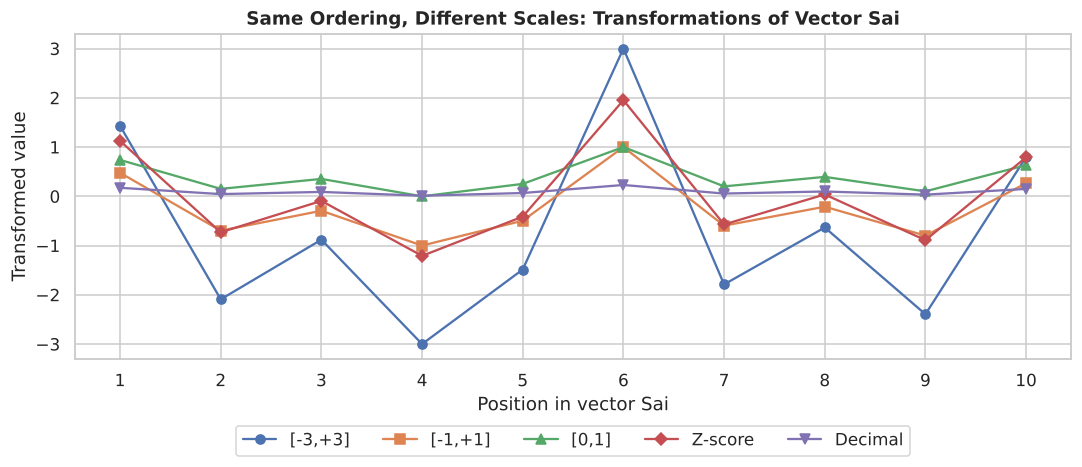

In [13]:
summary_transform = pd.DataFrame({
    "Original": Sai, "[-3,+3]": Sai_m3_p3, "[-1,+1]": Sai_m1_p1,
    "[0,1]": Sai_0_1, "Z-score": Sai_z, "Decimal": Sai_decimal
})
display(summary_transform.round(4))

fig, ax = plt.subplots(figsize=(10, 4.5))
for col, marker in zip(["[-3,+3]", "[-1,+1]", "[0,1]", "Z-score", "Decimal"], ["o", "s", "^", "D", "v"]):
    ax.plot(range(1, 11), summary_transform[col], marker=marker, label=col)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Position in vector Sai")
ax.set_ylabel("Transformed value")
ax.set_title("Same Ordering, Different Scales: Transformations of Vector Sai")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.tight_layout()
plt.show()

**Interpretation.** All five transformations preserve the *order* of the values – 12 is always the smallest and 230 the largest – only the scale changes. In every range normalisation the minimum (12) maps to the lower bound and the maximum (230) to the upper bound. The z-scores have mean 0 and standard deviation 1; my registration-number value 173 lies 1.13 standard deviations above the mean, and 230 is the most extreme at 1.95. Decimal scaling uses $j = 3$ because the largest absolute value has three digits, so all values fall in (0, 0.23]. Min–max scaling is sensitive to extreme values (one large value compresses everything else), while z-scores are the natural choice when the data are later used in distance-based methods.

---
# Assessment 2 – Data Import, Transform and Basic Statistical Analysis
**Experiment 4 · CO1: Engrave simple R programs.**

**Theory.** Preliminary exploration answers three questions before any modelling: *What does the data look like?* (shape, variable names, types), *Is it complete?* (missing values, duplicates) and *How is it distributed?* (summary statistics, spread). Missing values can be handled by deleting rows (listwise deletion) or by **imputation** – replacing them with a mean, median, mode, the previous/next observation (forward/backward fill) or a constant. As the question paper notes, no output below prints more than 10 records.

### 1. Import the dataset
`pd.read_csv()` is the counterpart of R's `read.csv()`. The `rownames` column is only R's row index written to the file, so it is dropped after import.

In [14]:
raw = pd.read_csv(URL)
mroz = raw.drop(columns="rownames")
print("Dataset imported successfully. Shape:", mroz.shape)

Dataset imported successfully. Shape: (753, 22)


### 2. First 10 records

In [15]:
mroz.head(10)

,inlf,hours,kidslt6,kidsge6,age,educ,wage,repwage,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,city,exper,nwifeinc,lwage,expersq
0,1,1610,1,0,32,12,3.3540,2.6500,2708,34,12,4.0288,16310,0.7215,12,7,5.0000,0,14,10.9101,1.2102,196
1,1,1656,0,2,30,12,1.3889,2.6500,2310,30,9,8.4416,21800,0.6615,7,7,11.0000,1,5,19.5000,0.3285,25
2,1,1980,1,3,35,12,4.5455,4.0400,3072,40,12,3.5807,21040,0.6915,12,7,5.0000,0,15,12.0399,1.5141,225
3,1,456,0,3,34,12,1.0965,3.2500,1920,53,10,3.5417,7300,0.7815,7,7,5.0000,0,6,6.8000,0.0921,36
4,1,1568,1,2,31,14,4.5918,3.6000,2000,32,12,10.0000,27300,0.6215,12,14,9.5000,1,7,20.1001,1.5243,49
5,1,2032,0,0,54,12,4.7421,4.7000,1040,57,11,6.7106,19495,0.6915,14,7,7.5000,1,33,9.8591,1.5565,1089
6,1,1440,0,2,37,16,8.3333,5.9500,2670,37,12,3.4277,21152,0.6915,14,7,5.0000,0,11,9.1520,2.1203,121
7,1,1020,0,0,54,12,7.8431,9.9800,4120,53,8,2.5485,18900,0.6915,3,3,5.0000,0,35,10.9000,2.0596,1225
8,1,1458,0,2,48,12,2.1262,0.0000,1995,52,4,4.2206,20405,0.7515,7,7,3.0000,0,24,17.3050,0.7543,576
9,1,1600,0,2,39,12,4.6875,4.1500,2100,43,12,5.7143,20425,0.6915,7,7,5.0000,0,21,12.9250,1.5449,441


### 3. Last 10 records

In [16]:
mroz.tail(10)

,inlf,hours,kidslt6,kidsge6,age,educ,wage,repwage,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,city,exper,nwifeinc,lwage,expersq
743,0,0,0,1,53,12,NaN,0.0000,2677,53,12,5.6033,23426,0.7215,0,0,7.5000,1,11,23.4260,NaN,121
744,0,0,0,3,42,10,NaN,2.7500,3150,44,12,7.9365,26000,0.6615,3,3,11.0000,1,14,26.0000,NaN,196
745,0,0,2,6,39,12,NaN,0.0000,1430,34,12,2.9476,7840,0.9415,7,0,9.5000,1,5,7.8400,NaN,25
746,0,0,1,2,32,10,NaN,0.0000,3307,36,4,2.0562,6800,0.7915,7,3,7.5000,0,2,6.8000,NaN,4
747,0,0,0,2,36,12,NaN,0.0000,3120,39,12,1.3013,5330,0.7915,7,12,14.0000,0,4,5.3300,NaN,16
748,0,0,0,2,40,13,NaN,0.0000,3020,43,16,9.2715,28200,0.6215,10,10,9.5000,1,5,28.2000,NaN,25
749,0,0,2,3,31,12,NaN,0.0000,2056,33,12,4.8638,10000,0.7715,12,12,7.5000,0,14,10.0000,NaN,196
750,0,0,0,0,43,12,NaN,0.0000,2383,43,12,1.0898,9952,0.7515,10,3,7.5000,0,4,9.9520,NaN,16
751,0,0,0,0,60,12,NaN,0.0000,1705,55,8,12.4400,24984,0.6215,12,12,14.0000,1,15,24.9840,NaN,225
752,0,0,0,3,39,9,NaN,0.0000,3120,48,12,6.0897,28363,0.6915,7,7,11.0000,1,12,28.3630,NaN,144


### 4. Total number of rows and columns

In [17]:
rows, cols = mroz.shape
print(f"Rows: {rows}\nColumns: {cols}")

Rows: 753
Columns: 22


### 5. Names of all variables

In [18]:
print(list(mroz.columns))

['inlf', 'hours', 'kidslt6', 'kidsge6', 'age', 'educ', 'wage', 'repwage', 'hushrs', 'husage', 'huseduc', 'huswage', 'faminc', 'mtr', 'motheduc', 'fatheduc', 'unem', 'city', 'exper', 'nwifeinc', 'lwage', 'expersq']


### 6. Data type (structure) of each variable
`DataFrame.info()` is the Python analogue of R's `str()`.

In [19]:
mroz.info()

<class 'pandas.DataFrame'>
RangeIndex: 753 entries, 0 to 752
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   inlf      753 non-null    int64  
 1   hours     753 non-null    int64  
 2   kidslt6   753 non-null    int64  
 3   kidsge6   753 non-null    int64  
 4   age       753 non-null    int64  
 5   educ      753 non-null    int64  
 6   wage      428 non-null    float64
 7   repwage   753 non-null    float64
 8   hushrs    753 non-null    int64  
 9   husage    753 non-null    int64  
 10  huseduc   753 non-null    int64  
 11  huswage   753 non-null    float64
 12  faminc    753 non-null    int64  
 13  mtr       753 non-null    float64
 14  motheduc  753 non-null    int64  
 15  fatheduc  753 non-null    int64  
 16  unem      753 non-null    float64
 17  city      753 non-null    int64  
 18  exper     753 non-null    int64  
 19  nwifeinc  753 non-null    float64
 20  lwage     428 non-null    float64
 21  expe

### 7. Summary statistics

In [20]:
mroz.describe().T

,count,mean,std,min,25%,50%,75%,max
inlf,753.0000,0.5684,0.4956,0.0000,0.0000,1.0000,1.0000,1.0000
hours,753.0000,740.5764,871.3142,0.0000,0.0000,288.0000,"1,516.00","4,950.00"
kidslt6,753.0000,0.2377,0.5240,0.0000,0.0000,0.0000,0.0000,3.0000
kidsge6,753.0000,1.3533,1.3199,0.0000,0.0000,1.0000,2.0000,8.0000
age,753.0000,42.5378,8.0726,30.0000,36.0000,43.0000,49.0000,60.0000
educ,753.0000,12.2869,2.2802,5.0000,12.0000,12.0000,13.0000,17.0000
wage,428.0000,4.1777,3.3103,0.1282,2.2626,3.4819,4.9708,25.0000
repwage,753.0000,1.8497,2.4199,0.0000,0.0000,0.0000,3.5800,9.9800
hushrs,753.0000,"2,267.27",595.5666,175.0000,"1,928.00","2,164.00","2,553.00","5,010.00"
husage,753.0000,45.1208,8.0588,30.0000,38.0000,46.0000,52.0000,60.0000


### 8. Number of missing values in each column

In [21]:
mroz.isna().sum()

inlf          0
hours         0
kidslt6       0
kidsge6       0
age           0
educ          0
wage        325
repwage       0
hushrs        0
husage        0
huseduc       0
huswage       0
faminc        0
mtr           0
motheduc      0
fatheduc      0
unem          0
city          0
exper         0
nwifeinc      0
lwage       325
expersq       0
dtype: int64

### 9. Total number of missing values in the dataset

In [22]:
print("Total missing values:", int(mroz.isna().sum().sum()))

Total missing values: 650


### 10. Number of missing values in each column (only affected columns, with percentage)
Task 8 listed every column; here the same information is presented as a compact report of only the columns that actually contain missing values.

In [23]:
na_report = pd.DataFrame({"Missing": mroz.isna().sum(), "Percent": mroz.isna().mean() * 100})
na_report[na_report["Missing"] > 0]

,Missing,Percent
wage,325,43.1607
lwage,325,43.1607


**Interpretation.** Only `wage` and `lwage` contain missing values – 325 each (43.16%), 650 in total – and they are missing in exactly the same rows. These are precisely the 325 women with `inlf = 0`: a wage cannot be observed for someone who did not work. The missingness is therefore **structural**, not random. Any imputation invents a wage for a non-worker; this is why the Mroz data are famous in econometrics as the textbook example of *sample-selection bias* (Heckman correction).

### 11. Rows containing at least one missing value

In [24]:
rows_with_na = mroz[mroz.isna().any(axis=1)]
print("Number of rows with at least one missing value:", len(rows_with_na))
print("Row positions (first 10):", rows_with_na.index[:10].tolist())
rows_with_na.head(10)

Number of rows with at least one missing value: 325
Row positions (first 10): [428, 429, 430, 431, 432, 433, 434, 435, 436, 437]


,inlf,hours,kidslt6,kidsge6,age,educ,wage,repwage,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,city,exper,nwifeinc,lwage,expersq
428,0,0,0,1,49,12,NaN,0.0000,2550,54,15,7.8529,21025,0.6615,14,12,7.5000,1,2,21.0250,NaN,4
429,0,0,2,0,30,16,NaN,0.0000,1928,34,16,11.9290,23600,0.6615,14,7,9.5000,1,5,23.6000,NaN,25
430,0,0,1,0,30,12,NaN,0.0000,1100,39,17,18.0000,22800,0.6615,12,12,7.5000,0,12,22.8000,NaN,144
431,0,0,0,4,41,12,NaN,0.0000,3193,40,16,10.0220,35910,0.5815,7,7,7.5000,1,1,35.9100,NaN,1
432,0,0,0,1,45,12,NaN,0.0000,2250,46,16,9.3333,21700,0.6615,7,7,5.0000,1,12,21.7000,NaN,144
433,0,0,0,5,43,12,NaN,0.0000,2012,44,13,6.0850,21823,0.7515,7,7,7.5000,1,4,21.8230,NaN,16
434,0,0,0,1,42,13,NaN,0.0000,3856,46,15,5.7054,31000,0.6615,10,7,11.0000,1,9,31.0000,NaN,81
435,0,0,0,0,60,12,NaN,0.0000,1645,58,12,9.1185,15300,0.7215,7,7,7.5000,1,9,15.3000,NaN,81
436,0,0,0,0,57,12,NaN,0.0000,1554,57,12,7.2072,12925,0.7215,9,3,7.5000,1,6,12.9250,NaN,36
437,0,0,0,2,38,10,NaN,0.0000,2352,41,8,5.3146,15830,0.7515,12,7,5.0000,0,5,15.8300,NaN,25


### 12. Remove all rows containing missing values
Listwise deletion keeps only complete records. Here it would discard every non-participant, which is why the imputation methods that follow are explored instead.

In [25]:
mroz_complete = mroz.dropna()
print("Shape before:", mroz.shape, "| Shape after dropna():", mroz_complete.shape)
print("Rows removed:", mroz.shape[0] - mroz_complete.shape[0])
mroz_complete.head(10)

Shape before: (753, 22) | Shape after dropna(): (428, 22)
Rows removed: 325


,inlf,hours,kidslt6,kidsge6,age,educ,wage,repwage,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,city,exper,nwifeinc,lwage,expersq
0,1,1610,1,0,32,12,3.3540,2.6500,2708,34,12,4.0288,16310,0.7215,12,7,5.0000,0,14,10.9101,1.2102,196
1,1,1656,0,2,30,12,1.3889,2.6500,2310,30,9,8.4416,21800,0.6615,7,7,11.0000,1,5,19.5000,0.3285,25
2,1,1980,1,3,35,12,4.5455,4.0400,3072,40,12,3.5807,21040,0.6915,12,7,5.0000,0,15,12.0399,1.5141,225
3,1,456,0,3,34,12,1.0965,3.2500,1920,53,10,3.5417,7300,0.7815,7,7,5.0000,0,6,6.8000,0.0921,36
4,1,1568,1,2,31,14,4.5918,3.6000,2000,32,12,10.0000,27300,0.6215,12,14,9.5000,1,7,20.1001,1.5243,49
5,1,2032,0,0,54,12,4.7421,4.7000,1040,57,11,6.7106,19495,0.6915,14,7,7.5000,1,33,9.8591,1.5565,1089
6,1,1440,0,2,37,16,8.3333,5.9500,2670,37,12,3.4277,21152,0.6915,14,7,5.0000,0,11,9.1520,2.1203,121
7,1,1020,0,0,54,12,7.8431,9.9800,4120,53,8,2.5485,18900,0.6915,3,3,5.0000,0,35,10.9000,2.0596,1225
8,1,1458,0,2,48,12,2.1262,0.0000,1995,52,4,4.2206,20405,0.7515,7,7,3.0000,0,24,17.3050,0.7543,576
9,1,1600,0,2,39,12,4.6875,4.1500,2100,43,12,5.7143,20425,0.6915,7,7,5.0000,0,21,12.9250,1.5449,441


### Preparing a categorical column with missing values
Task 15 needs a categorical column that has missing values, but every column in the raw file is numeric. A meaningful one is created from `wage`: **`Wage_Band`** = *Low* (≤ \$3), *Medium* (\$3–\$6], *High* (> \$6). It is missing exactly where `wage` is missing. The working copy `mroz_clean` is used for tasks 13–15 so that each imputation builds on the previous one.

In [26]:
mroz["Wage_Band"] = pd.cut(mroz["wage"], bins=[0, 3, 6, np.inf], labels=["Low", "Medium", "High"])
mroz_clean = mroz.copy()
mroz_clean[["wage", "lwage", "Wage_Band"]].isna().sum()

wage         325
lwage        325
Wage_Band    325
dtype: int64

### 13. Replace missing values in a numerical column with the mean (`lwage`)
`lwage` is roughly symmetric (it is a logarithm), so the mean is a reasonable centre.

In [27]:
lwage_mean = mroz_clean["lwage"].mean()
mroz_clean["lwage"] = mroz_clean["lwage"].fillna(lwage_mean)
print(f"Mean of lwage used for imputation: {lwage_mean:.4f}")
print("Missing in lwage after imputation:", mroz_clean["lwage"].isna().sum())

Mean of lwage used for imputation: 1.1902
Missing in lwage after imputation: 0


### 14. Replace missing values in another numerical column with the median (`wage`)
`wage` is strongly right-skewed (a few very high earners), so the median is the more robust centre.

In [28]:
wage_median = mroz_clean["wage"].median()
print(f"Mean of wage = {mroz['wage'].mean():.4f}  vs  median of wage = {wage_median:.4f}")
mroz_clean["wage"] = mroz_clean["wage"].fillna(wage_median)
print("Missing in wage after imputation:", mroz_clean["wage"].isna().sum())

Mean of wage = 4.1777  vs  median of wage = 3.4819
Missing in wage after imputation: 0


### 15. Replace missing values in a categorical column with the mode (`Wage_Band`)

In [29]:
band_mode = mroz_clean["Wage_Band"].mode()[0]
print("Frequencies before imputation:\n", mroz_clean["Wage_Band"].value_counts(dropna=False), sep="")
mroz_clean["Wage_Band"] = mroz_clean["Wage_Band"].fillna(band_mode)
print("\nMode used:", band_mode)
print("Frequencies after imputation:\n", mroz_clean["Wage_Band"].value_counts(), sep="")

Frequencies before imputation:
Wage_Band
NaN       325
Low       180
Medium    178
High       70
Name: count, dtype: int64

Mode used: Low
Frequencies after imputation:
Wage_Band
Low       505
Medium    178
High       70
Name: count, dtype: int64


### 16. Forward filling (Last Observation Carried Forward)
R's `zoo::na.locf()` replaces each `NA` with the last non-missing value above it; pandas' `ffill()` does the same. It is shown on a fresh copy of the original `wage` column. Because the file lists all 428 participants first, every missing wage receives the wage of the last participant (row 428). This illustrates that LOCF is suited to ordered (time-series) data rather than cross-sectional data.

In [30]:
wage_ffill = mroz["wage"].ffill()
window = slice(424, 432)
pd.DataFrame({"inlf": mroz["inlf"][window], "wage (original)": mroz["wage"][window], "wage (forward filled)": wage_ffill[window]})

,inlf,wage (original),wage (forward filled)
424,1,5.3061,5.3061
425,1,5.8675,5.8675
426,1,3.4091,3.4091
427,1,4.0816,4.0816
428,0,NaN,4.0816
429,0,NaN,4.0816
430,0,NaN,4.0816
431,0,NaN,4.0816


In [31]:
print("Missing after forward fill:", wage_ffill.isna().sum())

Missing after forward fill: 0


### 17. Backward filling (Next Observation Carried Backward)
`bfill()` replaces each `NA` with the next non-missing value below it. Since no observed wage follows the block of non-participants at the end of the file, backward filling cannot fill those values – an important limitation of this method.

In [32]:
wage_bfill = mroz["wage"].bfill()
print("Missing before backward fill:", mroz["wage"].isna().sum())
print("Missing after  backward fill:", wage_bfill.isna().sum())
pd.DataFrame({"wage (original)": mroz["wage"][window], "wage (backward filled)": wage_bfill[window]})

Missing before backward fill: 325
Missing after  backward fill: 325


,wage (original),wage (backward filled)
424,5.3061,5.3061
425,5.8675,5.8675
426,3.4091,3.4091
427,4.0816,4.0816
428,NaN,NaN
429,NaN,NaN
430,NaN,NaN
431,NaN,NaN


### 18. Replace remaining missing values with a constant (0 or "Unknown")
After backward filling, values are still missing. On that copy, numeric gaps are replaced with **0** and categorical gaps with **"Unknown"**. For this dataset a 0 wage is economically meaningful: the woman earned nothing in the labour market in 1975.

In [33]:
mroz_const = mroz.copy()
mroz_const["wage"] = wage_bfill
num_cols = mroz_const.select_dtypes(include="number").columns
mroz_const[num_cols] = mroz_const[num_cols].fillna(0)
mroz_const["Wage_Band"] = mroz_const["Wage_Band"].cat.add_categories("Unknown").fillna("Unknown")
print("Missing values remaining:", int(mroz_const.isna().sum().sum()))
print(mroz_const["Wage_Band"].value_counts())

Missing values remaining: 0
Wage_Band
Unknown    325
Low        180
Medium     178
High        70
Name: count, dtype: int64


### 19. Remove duplicate records
The analysis continues with `mroz_clean` (mean / median / mode imputed).

In [34]:
n_dup = mroz_clean.duplicated().sum()
print("Duplicate rows found:", n_dup)
mroz_clean = mroz_clean.drop_duplicates()
print("Shape after removing duplicates:", mroz_clean.shape)

Duplicate rows found: 0
Shape after removing duplicates: (753, 23)


### 20. Convert appropriate variables into factors
`inlf` and `city` are 0/1 codes for categories, and `Wage_Band` is ordinal. In pandas the `category` dtype plays the role of R's `factor`.

In [35]:
mroz_clean["inlf"] = pd.Categorical(mroz_clean["inlf"].map({1: "Participant", 0: "Non-participant"}))
mroz_clean["city"] = pd.Categorical(mroz_clean["city"].map({1: "Urban", 0: "Rural"}))
mroz_clean["Wage_Band"] = pd.Categorical(mroz_clean["Wage_Band"], categories=["Low", "Medium", "High"], ordered=True)
print(mroz_clean[["inlf", "city", "Wage_Band"]].dtypes)
print("\nLevels of inlf:", list(mroz_clean["inlf"].cat.categories))
print("Levels of city:", list(mroz_clean["city"].cat.categories))
print("Levels of Wage_Band:", list(mroz_clean["Wage_Band"].cat.categories))

inlf         category
city         category
Wage_Band    category
dtype: object

Levels of inlf: ['Non-participant', 'Participant']
Levels of city: ['Rural', 'Urban']
Levels of Wage_Band: ['Low', 'Medium', 'High']


### 21. Rename columns

In [36]:
mroz_clean = mroz_clean.rename(columns={"inlf": "labour_force", "city": "residence",
                                        "faminc": "family_income", "nwifeinc": "nonwife_income"})
print(list(mroz_clean.columns))

['labour_force', 'hours', 'kidslt6', 'kidsge6', 'age', 'educ', 'wage', 'repwage', 'hushrs', 'husage', 'huseduc', 'huswage', 'family_income', 'mtr', 'motheduc', 'fatheduc', 'unem', 'residence', 'exper', 'nonwife_income', 'lwage', 'expersq', 'Wage_Band']


### 22. Create a derived column
**`wife_earnings` = `hours` × `wage`** gives the wife's annual labour earnings. Non-participants worked 0 hours, so their derived earnings are correctly 0 even though their wage was imputed. A second derived column, **`total_kids`**, adds the two child counts.

In [37]:
mroz_clean["wife_earnings"] = mroz_clean["hours"] * mroz_clean["wage"]
mroz_clean["total_kids"] = mroz_clean["kidslt6"] + mroz_clean["kidsge6"]
mroz_clean[["hours", "wage", "wife_earnings", "kidslt6", "kidsge6", "total_kids"]].head(10)

,hours,wage,wife_earnings,kidslt6,kidsge6,total_kids
0,1610,3.3540,"5,399.94",1,0,1
1,1656,1.3889,"2,300.02",0,2,2
2,1980,4.5455,"9,000.09",1,3,4
3,456,1.0965,500.0040,0,3,3
4,1568,4.5918,"7,199.94",1,2,3
5,2032,4.7421,"9,635.95",0,0,0
6,1440,8.3333,"11,999.95",0,2,2
7,1020,7.8431,"7,999.96",0,0,0
8,1458,2.1262,"3,100.00",0,2,2
9,1600,4.6875,"7,500.00",0,2,2


### 23. Summary statistics of the cleaned dataset (`summary()`)
`describe(include="all")` reports numeric statistics together with counts, number of unique levels, top level and its frequency for factors, similar to R's `summary()`.

In [38]:
mroz_clean.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
labour_force,753,2,Participant,428,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hours,753.0000,NaN,NaN,NaN,740.5764,871.3142,0.0000,0.0000,288.0000,"1,516.00","4,950.00"
kidslt6,753.0000,NaN,NaN,NaN,0.2377,0.5240,0.0000,0.0000,0.0000,0.0000,3.0000
kidsge6,753.0000,NaN,NaN,NaN,1.3533,1.3199,0.0000,0.0000,1.0000,2.0000,8.0000
age,753.0000,NaN,NaN,NaN,42.5378,8.0726,30.0000,36.0000,43.0000,49.0000,60.0000
educ,753.0000,NaN,NaN,NaN,12.2869,2.2802,5.0000,12.0000,12.0000,13.0000,17.0000
wage,753.0000,NaN,NaN,NaN,3.8774,2.5181,0.1282,3.1666,3.4819,3.7879,25.0000
repwage,753.0000,NaN,NaN,NaN,1.8497,2.4199,0.0000,0.0000,0.0000,3.5800,9.9800
hushrs,753.0000,NaN,NaN,NaN,"2,267.27",595.5666,175.0000,"1,928.00","2,164.00","2,553.00","5,010.00"
husage,753.0000,NaN,NaN,NaN,45.1208,8.0588,30.0000,38.0000,46.0000,52.0000,60.0000


### 24. Minimum and maximum values

In [39]:
numeric_clean = mroz_clean.select_dtypes(include="number")
pd.DataFrame({"Minimum": numeric_clean.min(), "Maximum": numeric_clean.max()})

,Minimum,Maximum
hours,0.0000,"4,950.00"
kidslt6,0.0000,3.0000
kidsge6,0.0000,8.0000
age,30.0000,60.0000
educ,5.0000,17.0000
wage,0.1282,25.0000
repwage,0.0000,9.9800
hushrs,175.0000,"5,010.00"
husage,30.0000,60.0000
huseduc,3.0000,17.0000


### 25 – 28. Range, variance, standard deviation and IQR
Computed for **`family_income`** as required, and then for a few other key numerical variables for comparison.
* **Range** = max − min
* **Variance** $s^2 = \frac{1}{n-1}\sum (x_i - \bar{x})^2$ (sample variance, as in R's `var()`)
* **Standard deviation** $s = \sqrt{s^2}$
* **IQR** = $Q_3 - Q_1$, the spread of the middle 50% of observations

In [40]:
fi = mroz_clean["family_income"]
print(f"25. Range of family_income              : {fi.max() - fi.min():,.2f}  (from {fi.min():,.0f} to {fi.max():,.0f})")
print(f"26. Variance of family_income           : {fi.var():,.2f}")
print(f"27. Standard deviation of family_income : {fi.std():,.2f}")
print(f"28. IQR of family_income                : {fi.quantile(0.75) - fi.quantile(0.25):,.2f}")

25. Range of family_income              : 94,500.00  (from 1,500 to 96,000)
26. Variance of family_income           : 148,601,025.44
27. Standard deviation of family_income : 12,190.20
28. IQR of family_income                : 12,772.00


In [41]:
key_vars = ["family_income", "hours", "age", "educ", "wage", "exper", "huswage"]
pd.DataFrame({
    "Range": numeric_clean[key_vars].max() - numeric_clean[key_vars].min(),
    "Variance": numeric_clean[key_vars].var(),
    "Std Dev": numeric_clean[key_vars].std(),
    "IQR": numeric_clean[key_vars].quantile(0.75) - numeric_clean[key_vars].quantile(0.25)
})

,Range,Variance,Std Dev,IQR
family_income,"94,500.00","148,601,025.44","12,190.20","12,772.00"
hours,"4,950.00","759,188.46",871.3142,"1,516.00"
age,30.0000,65.1665,8.0726,13.0000
educ,12.0000,5.1995,2.2802,1.0000
wage,24.8718,6.3411,2.5181,0.6213
exper,45.0000,65.1109,8.0691,11.0000
huswage,40.0969,17.8976,4.2306,4.3784


**Interpretation.** Family income ranges from \$1,500 to \$96,000 (range \$94,500), with a standard deviation of \$12,190 and an IQR of \$12,772; because the IQR ignores the long upper tail, it is the more representative measure of typical spread. `educ` has an IQR of only 1 year because half of the women have exactly 12 years of schooling. Note the effect of imputation on `wage`: after filling 325 values with the median, its standard deviation falls from 3.31 to 2.52 and its IQR from 2.71 to 0.62. Median/mean imputation artificially shrinks variability, which must be remembered when interpreting any statistic computed on imputed data.

---
# Assessment 3 – Data Cleaning and Univariate Analysis
**CO2: Debug and execute R programs using R Studio.**

**Theory.** *Data cleaning* removes problems that would bias results: missing values, duplicates, wrong data types, inconsistent text and outliers. *Univariate analysis* then studies one variable at a time – its centre, spread and shape for numerical variables (histograms, density curves, box/violin/dot plots) and its frequencies for categorical variables (frequency tables, bar, pie, lollipop and dot charts).

**Libraries.** The R packages `dplyr`, `tidyr`, `ggplot2`, `stringr` and `forcats` correspond to `pandas` (data manipulation, string methods via `.str`, categorical handling via `category` dtype) and `matplotlib` / `seaborn` (graphics), all imported in the setup cell.

### 1. Import the dataset

In [42]:
df3 = pd.read_csv(URL).drop(columns="rownames")
print("Shape:", df3.shape)

Shape: (753, 22)


### 2. First and last six records

In [43]:
df3.head(6)

,inlf,hours,kidslt6,kidsge6,age,educ,wage,repwage,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,city,exper,nwifeinc,lwage,expersq
0,1,1610,1,0,32,12,3.3540,2.6500,2708,34,12,4.0288,16310,0.7215,12,7,5.0000,0,14,10.9101,1.2102,196
1,1,1656,0,2,30,12,1.3889,2.6500,2310,30,9,8.4416,21800,0.6615,7,7,11.0000,1,5,19.5000,0.3285,25
2,1,1980,1,3,35,12,4.5455,4.0400,3072,40,12,3.5807,21040,0.6915,12,7,5.0000,0,15,12.0399,1.5141,225
3,1,456,0,3,34,12,1.0965,3.2500,1920,53,10,3.5417,7300,0.7815,7,7,5.0000,0,6,6.8000,0.0921,36
4,1,1568,1,2,31,14,4.5918,3.6000,2000,32,12,10.0000,27300,0.6215,12,14,9.5000,1,7,20.1001,1.5243,49
5,1,2032,0,0,54,12,4.7421,4.7000,1040,57,11,6.7106,19495,0.6915,14,7,7.5000,1,33,9.8591,1.5565,1089


In [44]:
df3.tail(6)

,inlf,hours,kidslt6,kidsge6,age,educ,wage,repwage,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,city,exper,nwifeinc,lwage,expersq
747,0,0,0,2,36,12,NaN,0.0000,3120,39,12,1.3013,5330,0.7915,7,12,14.0000,0,4,5.3300,NaN,16
748,0,0,0,2,40,13,NaN,0.0000,3020,43,16,9.2715,28200,0.6215,10,10,9.5000,1,5,28.2000,NaN,25
749,0,0,2,3,31,12,NaN,0.0000,2056,33,12,4.8638,10000,0.7715,12,12,7.5000,0,14,10.0000,NaN,196
750,0,0,0,0,43,12,NaN,0.0000,2383,43,12,1.0898,9952,0.7515,10,3,7.5000,0,4,9.9520,NaN,16
751,0,0,0,0,60,12,NaN,0.0000,1705,55,8,12.4400,24984,0.6215,12,12,14.0000,1,15,24.9840,NaN,225
752,0,0,0,3,39,9,NaN,0.0000,3120,48,12,6.0897,28363,0.6915,7,7,11.0000,1,12,28.3630,NaN,144


### 3. Total number of missing values

In [45]:
print("Total missing values:", int(df3.isna().sum().sum()))
print(df3.isna().sum()[df3.isna().sum() > 0])

Total missing values: 650
wage     325
lwage    325
dtype: int64


### 4. Records containing at least one missing value

In [46]:
na_rows = df3[df3.isna().any(axis=1)]
print("Records with at least one missing value:", len(na_rows))
na_rows.head(10)

Records with at least one missing value: 325


,inlf,hours,kidslt6,kidsge6,age,educ,wage,repwage,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,city,exper,nwifeinc,lwage,expersq
428,0,0,0,1,49,12,NaN,0.0000,2550,54,15,7.8529,21025,0.6615,14,12,7.5000,1,2,21.0250,NaN,4
429,0,0,2,0,30,16,NaN,0.0000,1928,34,16,11.9290,23600,0.6615,14,7,9.5000,1,5,23.6000,NaN,25
430,0,0,1,0,30,12,NaN,0.0000,1100,39,17,18.0000,22800,0.6615,12,12,7.5000,0,12,22.8000,NaN,144
431,0,0,0,4,41,12,NaN,0.0000,3193,40,16,10.0220,35910,0.5815,7,7,7.5000,1,1,35.9100,NaN,1
432,0,0,0,1,45,12,NaN,0.0000,2250,46,16,9.3333,21700,0.6615,7,7,5.0000,1,12,21.7000,NaN,144
433,0,0,0,5,43,12,NaN,0.0000,2012,44,13,6.0850,21823,0.7515,7,7,7.5000,1,4,21.8230,NaN,16
434,0,0,0,1,42,13,NaN,0.0000,3856,46,15,5.7054,31000,0.6615,10,7,11.0000,1,9,31.0000,NaN,81
435,0,0,0,0,60,12,NaN,0.0000,1645,58,12,9.1185,15300,0.7215,7,7,7.5000,1,9,15.3000,NaN,81
436,0,0,0,0,57,12,NaN,0.0000,1554,57,12,7.2072,12925,0.7215,9,3,7.5000,1,6,12.9250,NaN,36
437,0,0,0,2,38,10,NaN,0.0000,2352,41,8,5.3146,15830,0.7515,12,7,5.0000,0,5,15.8300,NaN,25


### 5. Remove columns with more than 70% missing values
A column that is mostly empty carries little information and any imputation would be largely invented, so a 70% threshold is a common rule.

In [47]:
missing_pct = df3.isna().mean() * 100
print(missing_pct[missing_pct > 0].round(2).to_string())
cols_to_drop = missing_pct[missing_pct > 70].index.tolist()
df3 = df3.drop(columns=cols_to_drop)
print("\nColumns above 70% missing:", cols_to_drop if cols_to_drop else "None")
print("Shape after this step:", df3.shape)

wage    43.1600
lwage   43.1600

Columns above 70% missing: None
Shape after this step: (753, 22)


**Interpretation.** The worst columns (`wage`, `lwage`) are 43.16% missing, below the 70% threshold, so no column is removed and the dataset keeps all 22 variables. Dropping them would in any case be a poor choice, because they are the key outcome variables of the study.

### Creating a categorical column with missing values
To demonstrate mode imputation (task 8), the categorical **`Wage_Band`** (Low / Medium / High) is derived from `wage` *before* imputation, so it inherits the 325 genuine missing values.

In [48]:
df3["Wage_Band"] = pd.cut(df3["wage"], bins=[0, 3, 6, np.inf], labels=["Low", "Medium", "High"])
df3["Wage_Band"].value_counts(dropna=False)

Wage_Band
NaN       325
Low       180
Medium    178
High       70
Name: count, dtype: int64

### 6. Replace missing numerical values with the mean
### 7. Replace missing numerical values with the median
Both strategies are applied to `wage` on separate copies and compared. Mean imputation is pulled upwards by the long right tail, while median imputation is robust. For the cleaned dataset the **median is kept for `wage`** and the **mean for `lwage`** (log wages are nearly symmetric).

In [49]:
wage_mean_imp = df3["wage"].fillna(df3["wage"].mean())
wage_median_imp = df3["wage"].fillna(df3["wage"].median())
pd.DataFrame({
    "Original (observed only)": df3["wage"].describe(),
    "Mean-imputed": wage_mean_imp.describe(),
    "Median-imputed": wage_median_imp.describe()
}).round(3)

,Original (observed only),Mean-imputed,Median-imputed
count,428.0000,753.0000,753.0000
mean,4.1780,4.1780,3.8770
std,3.3100,2.4940,2.5180
min,0.1280,0.1280,0.1280
25%,2.2630,3.1670,3.1670
50%,3.4820,4.1780,3.4820
75%,4.9710,4.1780,3.7880
max,25.0000,25.0000,25.0000


In [50]:
df3["wage"] = wage_median_imp
df3["lwage"] = df3["lwage"].fillna(df3["lwage"].mean())
print("Missing in wage :", df3["wage"].isna().sum())
print("Missing in lwage:", df3["lwage"].isna().sum())

Missing in wage : 0
Missing in lwage: 0


### 8. Replace missing categorical values with the mode

In [51]:
mode_value = df3["Wage_Band"].mode()[0]
df3["Wage_Band"] = df3["Wage_Band"].fillna(mode_value)
print("Mode:", mode_value)
print(df3["Wage_Band"].value_counts())
print("Total missing values now:", int(df3.isna().sum().sum()))

Mode: Low
Wage_Band
Low       505
Medium    178
High       70
Name: count, dtype: int64
Total missing values now: 0


### 9. Identify duplicate rows

In [52]:
dups = df3[df3.duplicated(keep=False)]
print("Number of duplicated rows:", df3.duplicated().sum())
dups.head(10)

Number of duplicated rows: 0


,inlf,hours,kidslt6,kidsge6,age,educ,wage,repwage,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,city,exper,nwifeinc,lwage,expersq,Wage_Band


### 10. Remove duplicate rows

In [53]:
before = len(df3)
df3 = df3.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {before}, rows after: {len(df3)}, removed: {before - len(df3)}")

Rows before: 753, rows after: 753, removed: 0


### 11. Identify columns stored with incorrect data types
A simple rule flags integer columns that take only two values (0/1): these are category codes stored as numbers. Count variables (`kidslt6`, `kidsge6`) and continuous variables are correctly numeric.

In [54]:
type_check = pd.DataFrame({"dtype": df3.dtypes.astype(str), "unique_values": df3.nunique()})
type_check["suggested"] = np.where((type_check["unique_values"] <= 2) & (type_check["dtype"].str.startswith("int")),
                                   "category (binary code stored as number)", "OK")
type_check

,dtype,unique_values,suggested
inlf,int64,2,category (binary code stored as number)
hours,int64,306,OK
kidslt6,int64,4,OK
kidsge6,int64,9,OK
age,int64,31,OK
educ,int64,13,OK
wage,float64,374,OK
repwage,float64,164,OK
hushrs,int64,422,OK
husage,int64,31,OK


### 12. Convert character variables into factors
The raw file has no character columns. The binary codes are therefore first converted to descriptive text (character) columns `LF_Status` and `Residence`, and those character variables are then converted into factors (`category`), along with `Wage_Band`.

In [55]:
df3["LF_Status"] = df3["inlf"].map({1: "Participant", 0: "Non-participant"})
df3["Residence"] = df3["city"].map({1: "Urban", 0: "Rural"})
print("Before:", df3[["LF_Status", "Residence"]].dtypes.astype(str).to_dict())
for col in ["LF_Status", "Residence", "Wage_Band"]:
    df3[col] = df3[col].astype("category")
print("After :", df3[["LF_Status", "Residence", "Wage_Band"]].dtypes.astype(str).to_dict())

Before: {'LF_Status': 'str', 'Residence': 'str'}
After : {'LF_Status': 'category', 'Residence': 'category', 'Wage_Band': 'category'}


### 13. Convert text values to lowercase / uppercase
Consistent case prevents “Urban”, “urban” and “URBAN” being treated as different categories. `LF_Status` is converted to UPPERCASE and `Residence` to lowercase using pandas string methods (R: `stringr::str_to_upper` / `str_to_lower`).

In [56]:
df3["LF_Status"] = df3["LF_Status"].astype(str).str.upper().astype("category")
df3["Residence"] = df3["Residence"].astype(str).str.lower().astype("category")
print("LF_Status levels:", list(df3["LF_Status"].cat.categories))
print("Residence levels:", list(df3["Residence"].cat.categories))

LF_Status levels: ['NON-PARTICIPANT', 'PARTICIPANT']
Residence levels: ['rural', 'urban']


### 14. Detect outliers using box plots
A box plot draws the box from $Q_1$ to $Q_3$, a line at the median, and whiskers to the furthest points within $1.5 \times IQR$; points beyond the whiskers are potential outliers.

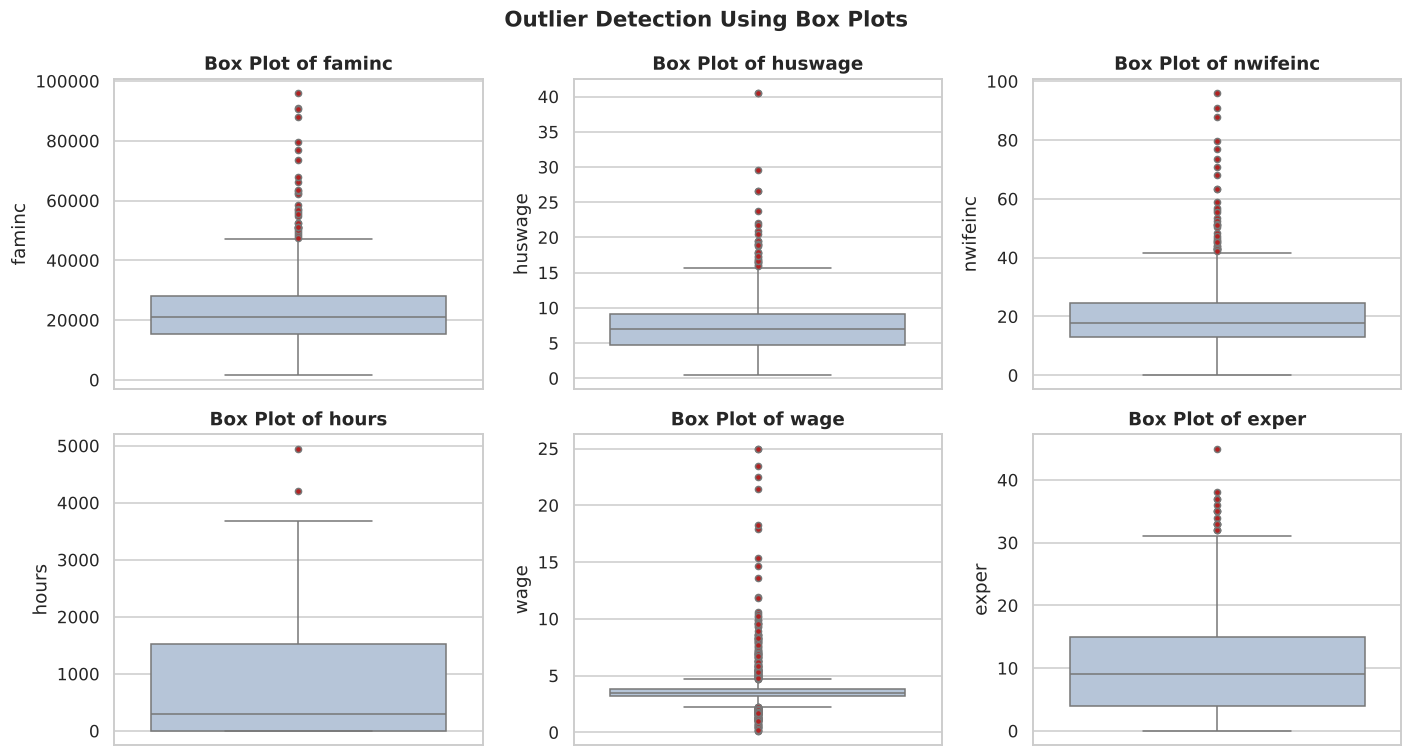

In [57]:
box_vars = ["faminc", "huswage", "nwifeinc", "hours", "wage", "exper"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, var in zip(axes.ravel(), box_vars):
    sns.boxplot(y=df3[var], ax=ax, color="lightsteelblue", flierprops={"markerfacecolor": "firebrick", "markersize": 4})
    ax.set_title(f"Box Plot of {var}")
    ax.set_ylabel(var)
fig.suptitle("Outlier Detection Using Box Plots", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 15. Identify outliers using the IQR method
Lower fence $= Q_1 - 1.5\,IQR$, upper fence $= Q_3 + 1.5\,IQR$ (mild outliers). Fences at $3\,IQR$ define **extreme** outliers.

In [58]:
def iqr_table(data, cols, k=1.5):
    rows = []
    for c in cols:
        q1, q3 = data[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - k * iqr, q3 + k * iqr
        n_out = ((data[c] < lo) | (data[c] > hi)).sum()
        rows.append([c, q1, q3, iqr, lo, hi, n_out, 100 * n_out / len(data)])
    return pd.DataFrame(rows, columns=["Variable", "Q1", "Q3", "IQR", "Lower", "Upper", "Outliers", "Percent"]).set_index("Variable")


print("Mild outliers (1.5 x IQR):")
display(iqr_table(df3, box_vars, 1.5))
print("Extreme outliers (3 x IQR):")
display(iqr_table(df3, box_vars, 3))

Mild outliers (1.5 x IQR):


,Q1,Q3,IQR,Lower,Upper,Outliers,Percent
Variable,,,,,,,
faminc,"15,428.00","28,200.00","12,772.00","-3,730.00","47,358.00",31,4.1169
huswage,4.7883,9.1667,4.3784,-1.7793,15.7343,29,3.8513
nwifeinc,13.0250,24.4660,11.4410,-4.1364,41.6274,35,4.6481
hours,0.0000,"1,516.00","1,516.00","-2,274.00","3,790.00",2,0.2656
wage,3.1666,3.7879,0.6213,2.2347,4.7198,226,30.0133
exper,4.0000,15.0000,11.0000,-12.5000,31.5000,16,2.1248


Extreme outliers (3 x IQR):


,Q1,Q3,IQR,Lower,Upper,Outliers,Percent
Variable,,,,,,,
faminc,"15,428.00","28,200.00","12,772.00","-22,888.00","66,516.00",8,1.0624
huswage,4.7883,9.1667,4.3784,-8.3469,22.3019,6,0.7968
nwifeinc,13.0250,24.4660,11.4410,-21.2978,58.7889,11,1.4608
hours,0.0000,"1,516.00","1,516.00","-4,548.00","6,064.00",0,0.0000
wage,3.1666,3.7879,0.6213,1.3027,5.6518,116,15.4050
exper,4.0000,15.0000,11.0000,-29.0000,48.0000,0,0.0000


### 16. Remove extreme outliers
Only **extreme** outliers (beyond $3 \times IQR$) are removed, and only for the income variables `faminc`, `huswage` and `nwifeinc`. Mild outliers are kept because high incomes are genuine, and `wage` is not filtered because its median-imputed values compress its IQR artificially.

In [59]:
mask = pd.Series(True, index=df3.index)
for c in ["faminc", "huswage", "nwifeinc"]:
    q1, q3 = df3[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask &= df3[c].between(q1 - 3 * iqr, q3 + 3 * iqr)
df3_no_out = df3[mask].reset_index(drop=True)
print(f"Rows before: {len(df3)}, rows after: {len(df3_no_out)}, removed: {len(df3) - len(df3_no_out)}")
print(f"Max faminc before: {df3['faminc'].max():,.0f}  ->  after: {df3_no_out['faminc'].max():,.0f}")

Rows before: 753, rows after: 740, removed: 13
Max faminc before: 96,000  ->  after: 62,500


### 17. Histogram of a numerical variable
Family income (`faminc`, in thousands of dollars) after removing extreme outliers.

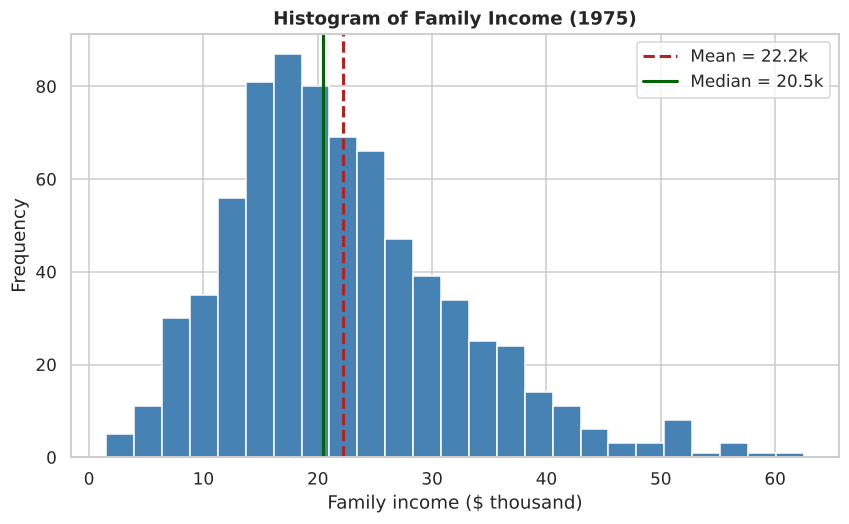

Skewness = 0.866


In [60]:
inc_k = df3_no_out["faminc"] / 1000
fig, ax = plt.subplots()
ax.hist(inc_k, bins=25, color="steelblue", edgecolor="white")
ax.axvline(inc_k.mean(), color="firebrick", ls="--", lw=2, label=f"Mean = {inc_k.mean():.1f}k")
ax.axvline(inc_k.median(), color="darkgreen", ls="-", lw=2, label=f"Median = {inc_k.median():.1f}k")
ax.set_title("Histogram of Family Income (1975)")
ax.set_xlabel("Family income ($ thousand)")
ax.set_ylabel("Frequency")
ax.legend()
plt.show()
print(f"Skewness = {stats.skew(inc_k):.3f}")

**Interpretation.** Family income is **unimodal and right-skewed** (skewness ≈ 0.87, even after removing extreme outliers). Most families earn between \$10k and \$30k, with the peak around \$15–20k, while a thinner tail stretches above \$50k. Because of this tail the mean (\$22.2k) is above the median (\$20.5k); the median is the better description of a typical family.

### 18. Histogram with a density curve
The histogram is put on the density scale so a kernel density estimate (KDE) – a smooth estimate of the probability density – can be overlaid.

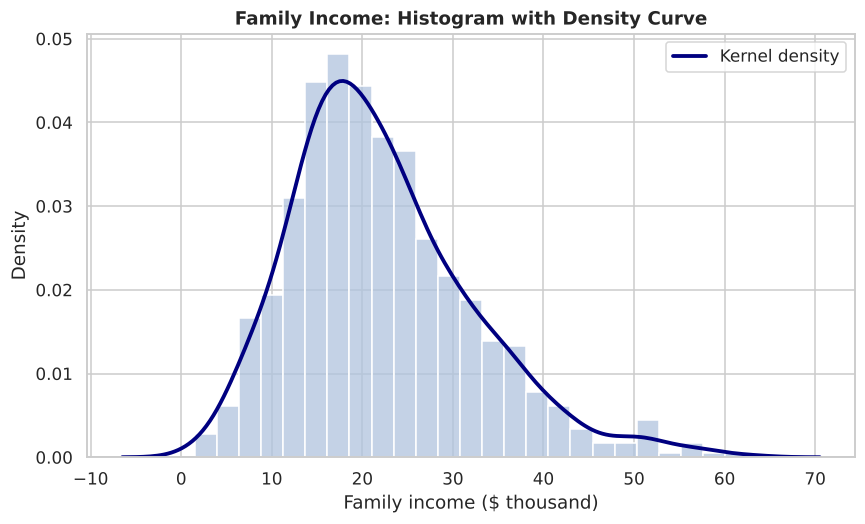

In [61]:
fig, ax = plt.subplots()
sns.histplot(inc_k, bins=25, stat="density", color="lightsteelblue", edgecolor="white", ax=ax)
sns.kdeplot(inc_k, color="navy", lw=2.5, ax=ax, label="Kernel density")
ax.set_title("Family Income: Histogram with Density Curve")
ax.set_xlabel("Family income ($ thousand)")
ax.set_ylabel("Density")
ax.legend()
plt.show()

### 19. Violin plot
A violin plot mirrors the density curve on both sides and adds an inner box plot, showing shape and summary statistics together.

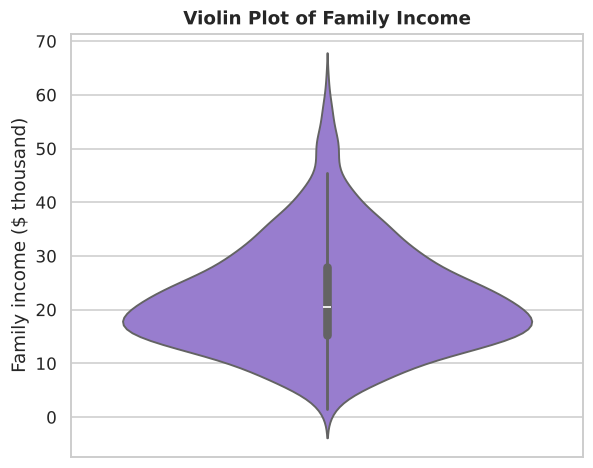

In [62]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.violinplot(y=inc_k, color="mediumpurple", inner="box", ax=ax)
ax.set_title("Violin Plot of Family Income")
ax.set_ylabel("Family income ($ thousand)")
plt.show()

### 20. Dot plot for a small numerical dataset
A Wilkinson-style dot plot stacks one dot per observation above its value; it works best for small samples. The years of schooling of the **first 30 women** form the small dataset.

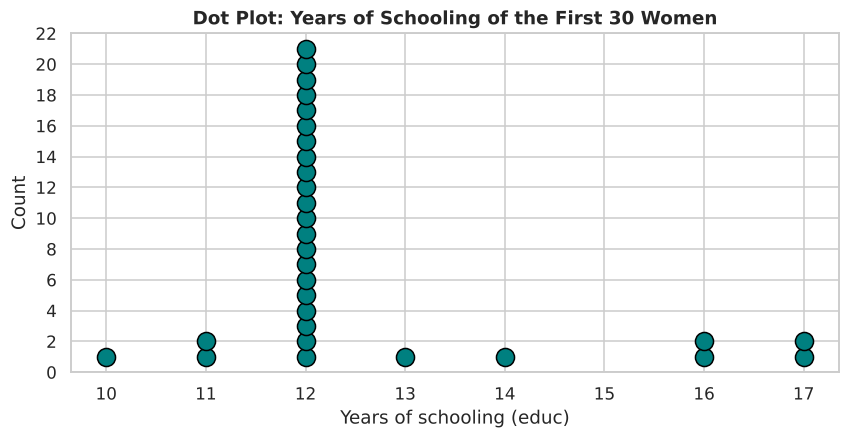

educ
10     1
11     2
12    21
13     1
14     1
16     2
17     2


In [63]:
small = df3["educ"].head(30)
fig, ax = plt.subplots(figsize=(9, 4))
for value, count in small.value_counts().sort_index().items():
    ax.scatter([value] * count, range(1, count + 1), s=140, color="teal", edgecolor="black")
ax.set_xticks(range(int(small.min()), int(small.max()) + 1))
ax.set_yticks(range(0, small.value_counts().max() + 3, 2))
ax.set_title("Dot Plot: Years of Schooling of the First 30 Women")
ax.set_xlabel("Years of schooling (educ)")
ax.set_ylabel("Count")
plt.show()
print(small.value_counts().sort_index().to_string())

### 21. Frequency table for a categorical variable
`Edu_Level` groups years of schooling into four education levels.

In [64]:
df3["Edu_Level"] = pd.cut(df3["educ"], bins=[0, 11, 12, 15, 17],
                          labels=["Below HS", "High School", "Some College", "College+"])
df3["Age_Group"] = pd.cut(df3["age"], bins=[29, 39, 49, 60], labels=["30-39", "40-49", "50-60"])
freq = df3["Edu_Level"].value_counts().sort_index()
freq_table = freq.rename_axis("Edu_Level").reset_index(name="Frequency")
freq_table

,Edu_Level,Frequency
0,Below HS,160
1,High School,381
2,Some College,109
3,College+,103


### 22. Proportion and percentage of each category

In [65]:
freq_table["Proportion"] = freq_table["Frequency"] / freq_table["Frequency"].sum()
freq_table["Percentage"] = (freq_table["Proportion"] * 100).round(2)
freq_table["Cumulative %"] = (freq_table["Proportion"].cumsum() * 100).round(2)
freq_table

,Edu_Level,Frequency,Proportion,Percentage,Cumulative %
0,Below HS,160,0.2125,21.2500,21.2500
1,High School,381,0.5060,50.6000,71.8500
2,Some College,109,0.1448,14.4800,86.3200
3,College+,103,0.1368,13.6800,100.0000


**Interpretation.** Half of the women (50.6%) stopped at exactly 12 years of schooling (high-school graduates). About one in five (21.25%) did not finish high school, and only 28% went beyond high school (14.5% some college, 13.7% four or more years). This concentration at 12 years explains why `educ` has a very small IQR.

### 23. Bar chart of category frequencies

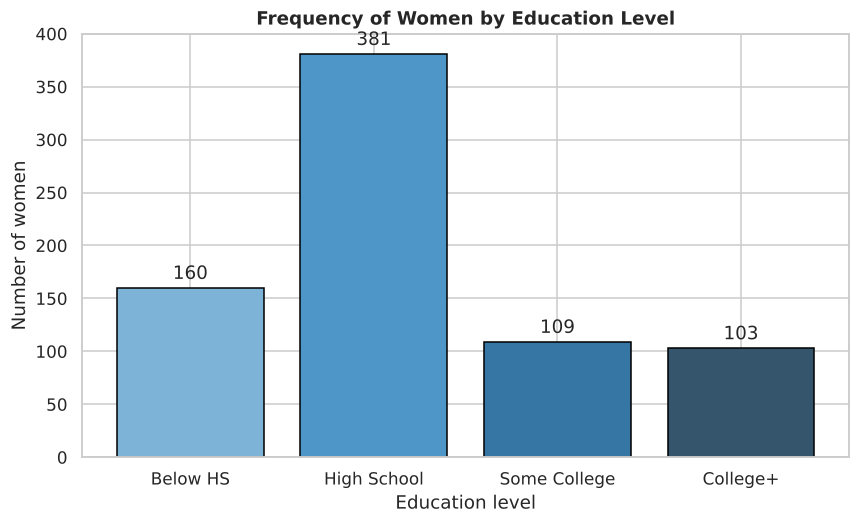

In [66]:
fig, ax = plt.subplots()
bars = ax.bar(freq_table["Edu_Level"].astype(str), freq_table["Frequency"],
              color=sns.color_palette("Blues_d", 4), edgecolor="black")
ax.bar_label(bars, padding=3)
ax.set_title("Frequency of Women by Education Level")
ax.set_xlabel("Education level")
ax.set_ylabel("Number of women")
plt.show()

### 24. Horizontal bar chart for a variable with several categories
`kidsge6` (number of children aged 6–18) has nine levels (0–8), and long category lists read best horizontally.

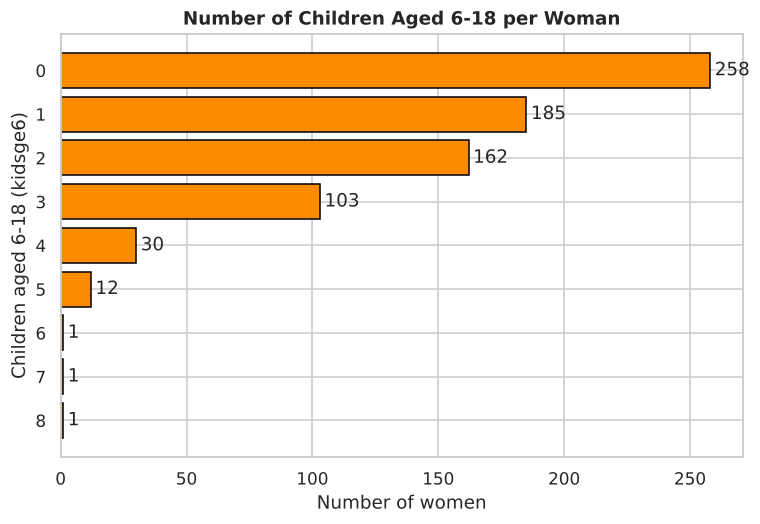

In [67]:
kids_freq = df3["kidsge6"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(kids_freq.index.astype(str), kids_freq.values, color="darkorange", edgecolor="black")
ax.bar_label(bars, padding=3)
ax.invert_yaxis()
ax.set_title("Number of Children Aged 6-18 per Woman")
ax.set_xlabel("Number of women")
ax.set_ylabel("Children aged 6-18 (kidsge6)")
plt.show()

### 25. Percentage bar chart

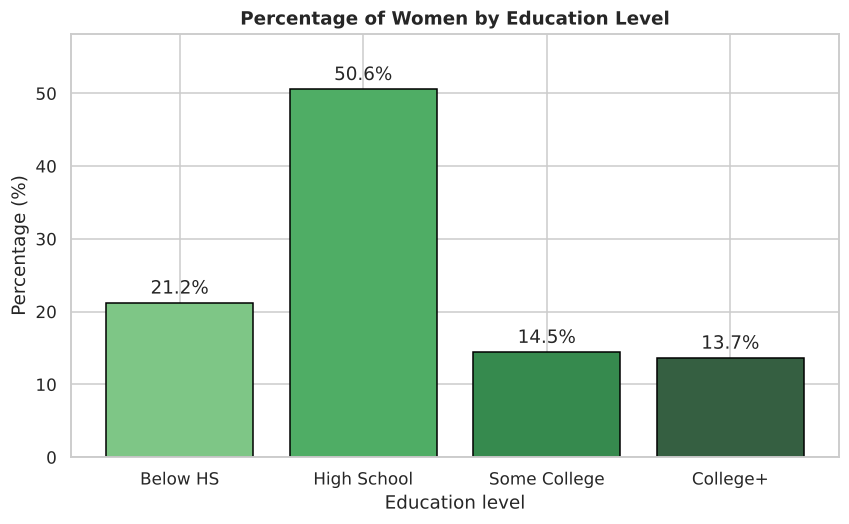

In [68]:
fig, ax = plt.subplots()
bars = ax.bar(freq_table["Edu_Level"].astype(str), freq_table["Percentage"],
              color=sns.color_palette("Greens_d", 4), edgecolor="black")
ax.bar_label(bars, labels=[f"{p:.1f}%" for p in freq_table["Percentage"]], padding=3)
ax.set_ylim(0, freq_table["Percentage"].max() * 1.15)
ax.set_title("Percentage of Women by Education Level")
ax.set_xlabel("Education level")
ax.set_ylabel("Percentage (%)")
plt.show()

### 26. Pie chart for a variable with few categories
Labour-force participation has only two categories, which suits a pie chart.

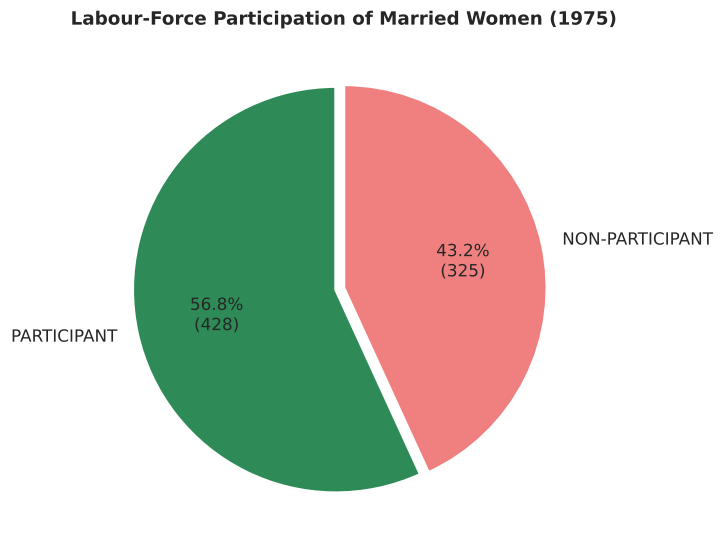

In [69]:
lf_freq = df3["LF_Status"].value_counts()
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(lf_freq.values, labels=lf_freq.index, autopct=lambda p: f"{p:.1f}%\n({round(p * lf_freq.sum() / 100)})",
       colors=["seagreen", "lightcoral"], startangle=90, explode=(0.04, 0),
       wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 11})
ax.set_title("Labour-Force Participation of Married Women (1975)")
plt.show()

### 27. Lollipop chart for categorical frequencies
A lollipop chart is a lighter alternative to a bar chart: a thin stem with a dot at the frequency.

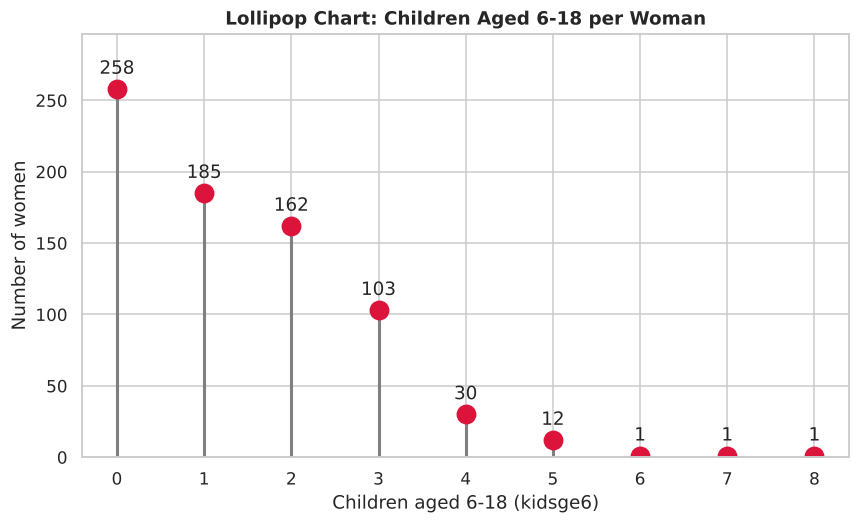

In [70]:
fig, ax = plt.subplots()
ax.vlines(kids_freq.index, 0, kids_freq.values, color="gray", lw=2)
ax.plot(kids_freq.index, kids_freq.values, "o", ms=12, color="crimson")
for x, y in kids_freq.items():
    ax.annotate(str(y), (x, y), textcoords="offset points", xytext=(0, 10), ha="center")
ax.set_xticks(kids_freq.index)
ax.set_ylim(0, kids_freq.max() * 1.15)
ax.set_title("Lollipop Chart: Children Aged 6-18 per Woman")
ax.set_xlabel("Children aged 6-18 (kidsge6)")
ax.set_ylabel("Number of women")
plt.show()

### 28. Dot chart
A Cleveland dot chart (R's `dotchart()`) places one dot per category on a horizontal scale, sorted by value, which makes comparison easy. Frequencies of the age groups are shown.

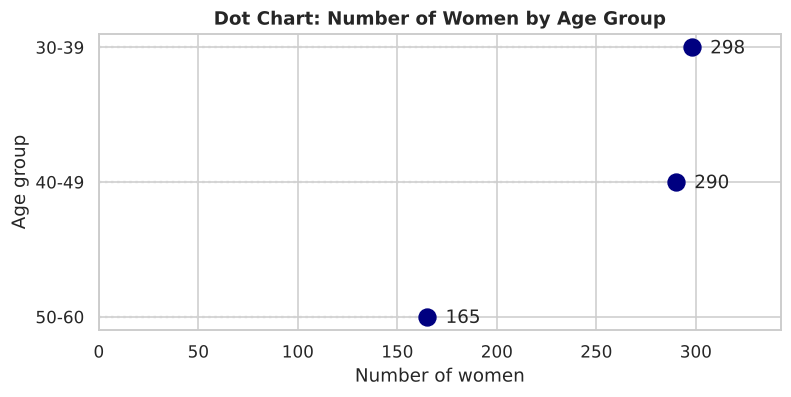

In [71]:
age_freq = df3["Age_Group"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hlines(age_freq.index.astype(str), 0, age_freq.values, color="lightgray", ls=":", lw=1.5)
ax.plot(age_freq.values, age_freq.index.astype(str), "o", ms=11, color="navy")
for y, x in zip(age_freq.index.astype(str), age_freq.values):
    ax.annotate(str(x), (x, y), textcoords="offset points", xytext=(12, -4))
ax.set_xlim(0, age_freq.max() * 1.15)
ax.set_title("Dot Chart: Number of Women by Age Group")
ax.set_xlabel("Number of women")
ax.set_ylabel("Age group")
plt.show()

### 29. Density plot (ggplot2 style)
The age distributions of participants and non-participants are compared with filled kernel density curves – the Python equivalent of `ggplot(aes(age, fill = group)) + geom_density(alpha = 0.4)`.

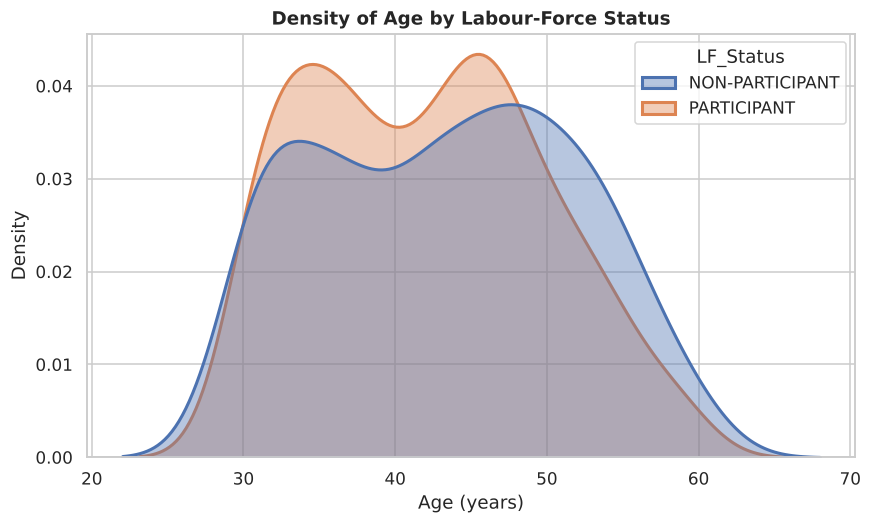

In [72]:
fig, ax = plt.subplots()
sns.kdeplot(data=df3, x="age", hue="LF_Status", fill=True, alpha=0.4, common_norm=False, lw=2, ax=ax)
ax.set_title("Density of Age by Labour-Force Status")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Density")
plt.show()

### 30. `facet_wrap()` – distribution of one variable across groups
Family income is shown in one panel per education level (seaborn's `col` + `col_wrap` reproduce `facet_wrap(~ Edu_Level)`). The summary table below the plot supports the interpretation of each panel.

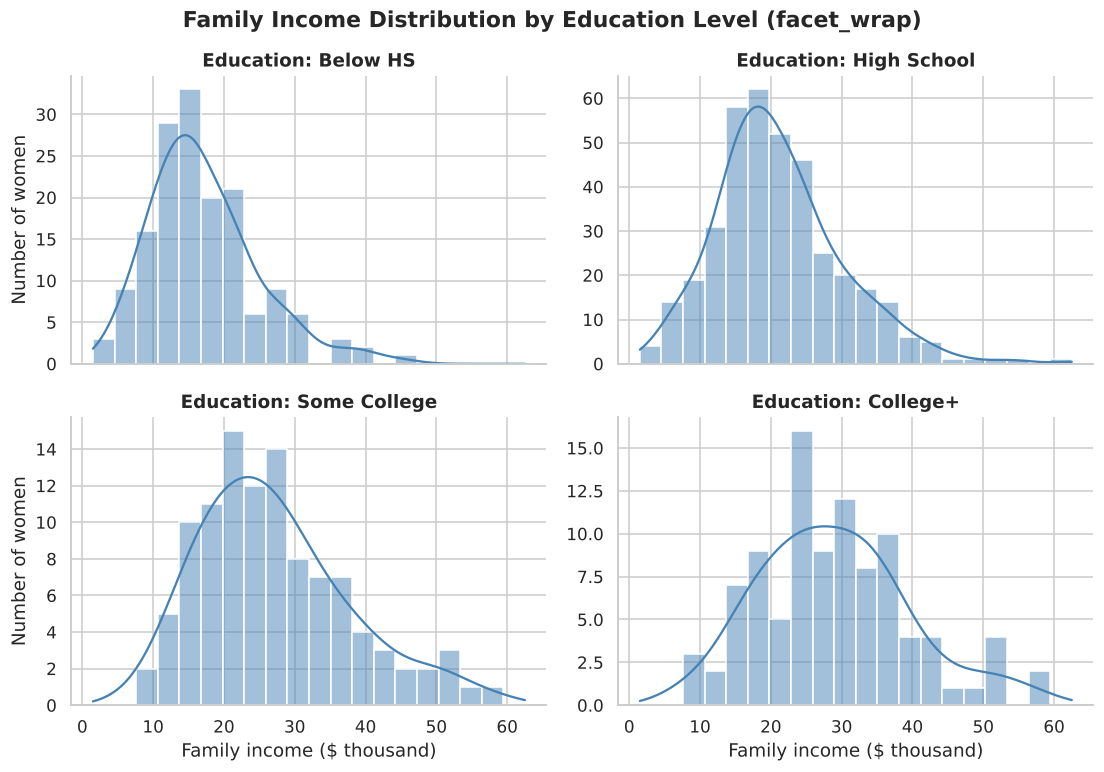

,n,mean,median,sd,skew
Edu_Level,,,,,
Below HS,158,17.1800,15.7400,7.6400,0.9600
High School,378,21.1100,19.8100,9.0000,0.8500
Some College,107,27.1200,25.7800,10.6400,0.7600
College+,97,28.9700,28.4500,10.6200,0.4800


In [73]:
facet_df = df3_no_out.assign(
    Edu_Level=pd.cut(df3_no_out["educ"], bins=[0, 11, 12, 15, 17],
                     labels=["Below HS", "High School", "Some College", "College+"]),
    faminc_k=df3_no_out["faminc"] / 1000)
g = sns.displot(data=facet_df, x="faminc_k", col="Edu_Level", col_wrap=2, bins=20, kde=True,
                color="steelblue", height=3.4, aspect=1.5, facet_kws={"sharey": False})
g.set_titles("Education: {col_name}")
g.set_axis_labels("Family income ($ thousand)", "Number of women")
g.fig.suptitle("Family Income Distribution by Education Level (facet_wrap)", y=1.03, fontweight="bold")
plt.show()

facet_df.groupby("Edu_Level", observed=True)["faminc_k"].agg(
    n="count", mean="mean", median="median", sd="std", skew=lambda s: stats.skew(s)).round(2)

**Interpretation of each panel (family income, \$ thousand):**
* **Below HS (n = 158):** concentrated at the low end, median ≈ \$15.7k, and the most right-skewed (skew ≈ 0.96) – most families are clustered at low incomes with a few higher-income exceptions.
* **High School (n = 378):** the largest group; median ≈ \$19.8k, still clearly right-skewed (≈ 0.85), with a single peak near \$18–20k.
* **Some College (n = 107):** the whole distribution shifts right, median ≈ \$25.8k, and it is more spread out (SD ≈ \$10.6k).
* **College+ (n = 97):** highest centre (median ≈ \$28.5k) and the most symmetric shape (skew ≈ 0.48), with incomes spread widely between \$10k and \$60k.

Overall, the median family income rises steadily with the wife's education (from about \$16k to \$28k) while the distributions become wider and less skewed.

---
# Assessment 4 – Bivariate Analysis
**Theory.** Bivariate analysis studies the relationship between **two** variables. The technique depends on their types:

| Pair of variables | Numerical summary | Visualisation |
|---|---|---|
| Categorical – Categorical | Contingency table, row/column % | Stacked / grouped bar chart |
| Numerical – Numerical | Correlation (Pearson, Spearman) | Scatter plot, line plot, heatmap, correlogram |
| Categorical – Numerical | Group means / medians | Box, violin, density plots by group |

### 1. Load the dataset

In [74]:
df4 = add_labels(pd.read_csv(URL).drop(columns="rownames"))
workers4 = df4[df4["inlf"] == 1].copy()
print("Full sample:", df4.shape, "| Working women (wage observed):", workers4.shape)
df4[["inlf", "LF_Status", "city", "Residence", "kidslt6", "Young_Kids", "educ", "Edu_Level"]].head()

Full sample: (753, 27) | Working women (wage observed): (428, 27)


,inlf,LF_Status,city,Residence,kidslt6,Young_Kids,educ,Edu_Level
0,1,Participant,0,Rural,1,Has child <6,12,High School
1,1,Participant,1,Urban,0,No child <6,12,High School
2,1,Participant,0,Rural,1,Has child <6,12,High School
3,1,Participant,0,Rural,0,No child <6,12,High School
4,1,Participant,1,Urban,1,Has child <6,14,Some College


### 2. Contingency table and stacked bar plots (two categorical variables)
**Variables:** `Young_Kids` (has a child under 6 or not) and `LF_Status`. Young children are expected to reduce participation.

In [75]:
ct4 = pd.crosstab(df4["Young_Kids"], df4["LF_Status"], margins=True, margins_name="Total")
print("Contingency table:")
display(ct4)
print("Row percentages:")
display((pd.crosstab(df4["Young_Kids"], df4["LF_Status"], normalize="index") * 100).round(2))

Contingency table:


LF_Status,Non-participant,Participant,Total
Young_Kids,,,
Has child <6,94,53,147
No child <6,231,375,606
Total,325,428,753


Row percentages:


LF_Status,Non-participant,Participant
Young_Kids,,
Has child <6,63.9500,36.0500
No child <6,38.1200,61.8800


**(a) Simple stacked bar plot – base graphics (matplotlib / pandas)**

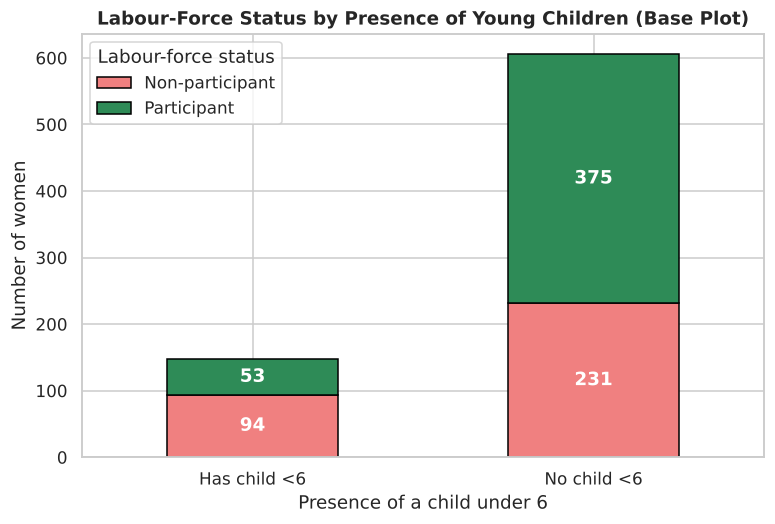

In [76]:
ct4_plain = pd.crosstab(df4["Young_Kids"], df4["LF_Status"])
ax = ct4_plain.plot(kind="bar", stacked=True, color=["lightcoral", "seagreen"], edgecolor="black", figsize=(8, 5), rot=0)
for container in ax.containers:
    ax.bar_label(container, label_type="center", color="white", fontweight="bold")
ax.set_title("Labour-Force Status by Presence of Young Children (Base Plot)")
ax.set_xlabel("Presence of a child under 6")
ax.set_ylabel("Number of women")
ax.legend(title="Labour-force status")
plt.show()

**(b) Stacked bar plot – ggplot2 style**
`seaborn.objects` implements the grammar of graphics (data → aesthetics → geometry → statistical transformation → position adjustment), the same layered idea as `ggplot(df, aes(x, fill = g)) + geom_bar(position = "stack")`.

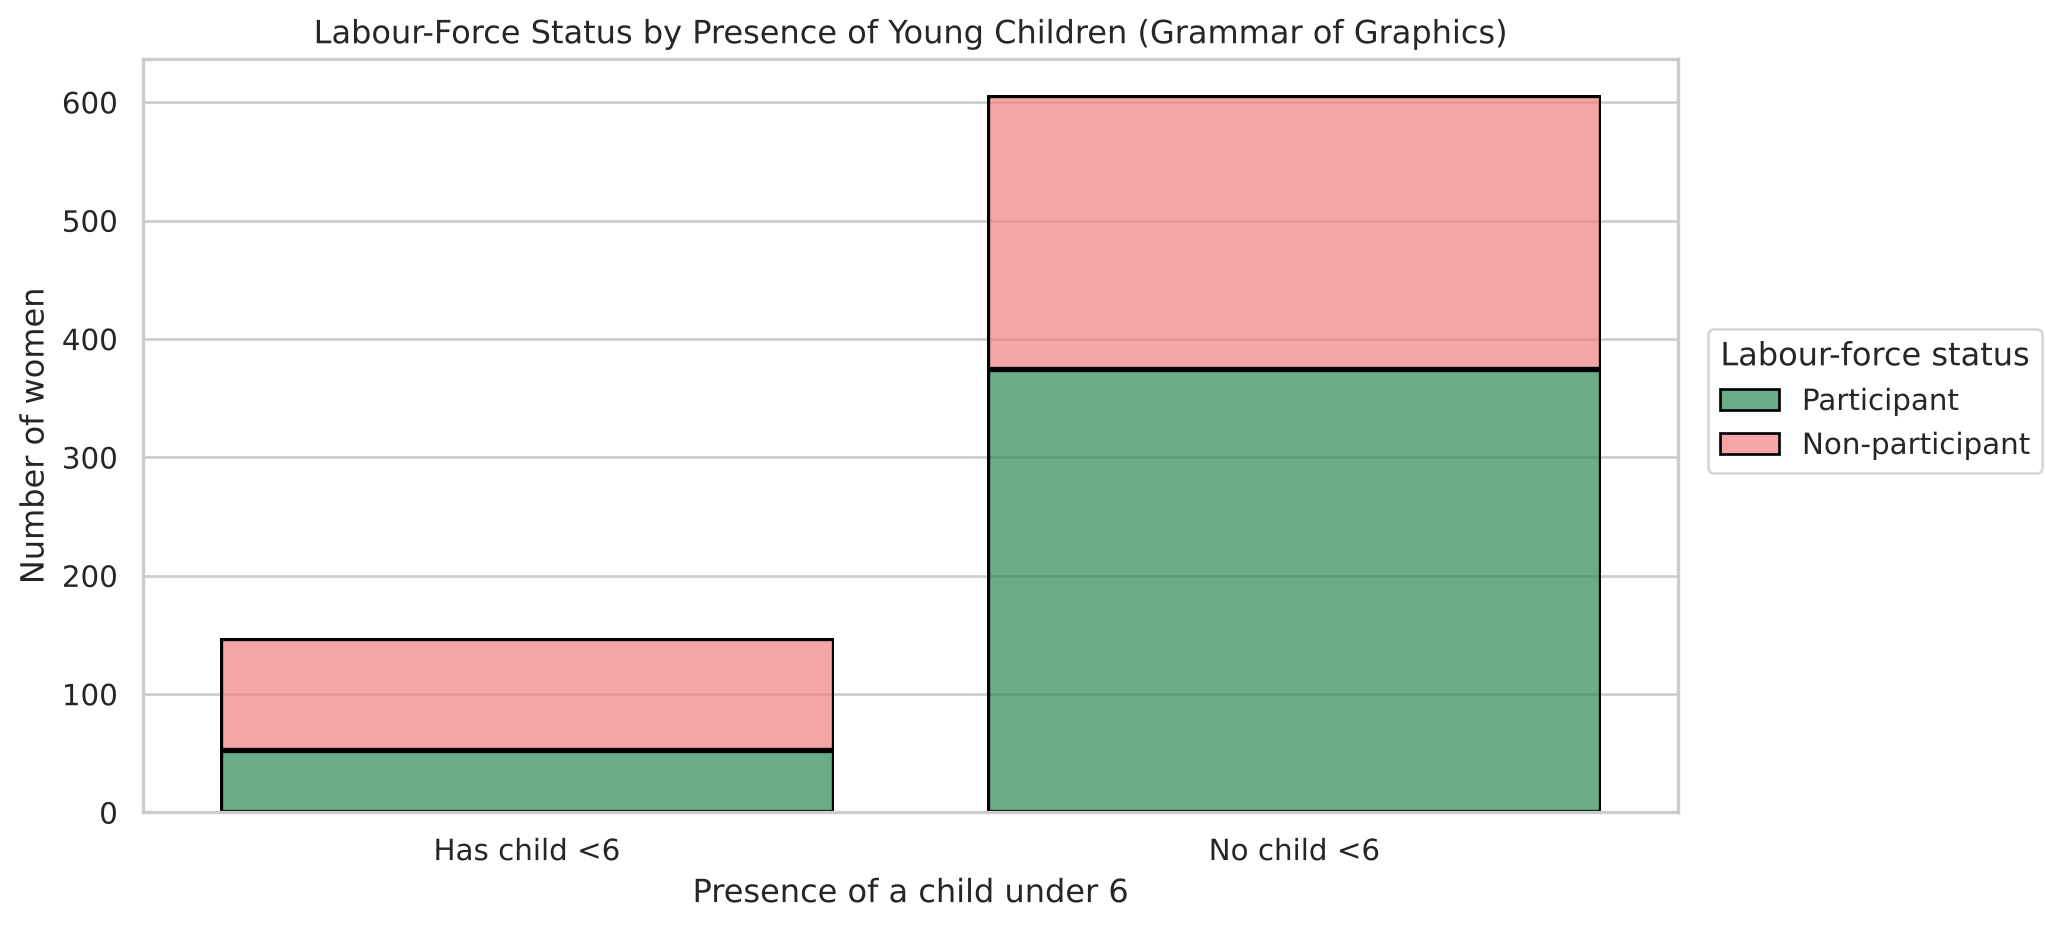

In [77]:
(
    so.Plot(df4, x="Young_Kids", color="LF_Status")
    .add(so.Bar(edgecolor="black"), so.Count(), so.Stack())
    .scale(color={"Participant": "seagreen", "Non-participant": "lightcoral"})
    .label(title="Labour-Force Status by Presence of Young Children (Grammar of Graphics)",
           x="Presence of a child under 6", y="Number of women", color="Labour-force status")
    .theme({**sns.axes_style("whitegrid")})
    .layout(size=(9, 5))
)

**Interpretation.** Of the 147 women with a child under six, only 36.1% were in the labour force, compared with 61.9% of the 606 women without young children – a gap of about 26 percentage points. The base-graphics and grammar-of-graphics versions show the same data; the second is built declaratively by mapping variables to aesthetics and adding a stacked-count layer.

### 3. Grouped (side-by-side) bar plot
**Variables:** `Edu_Level` and `LF_Status`. Side-by-side bars compare the frequencies of each status within every education level.

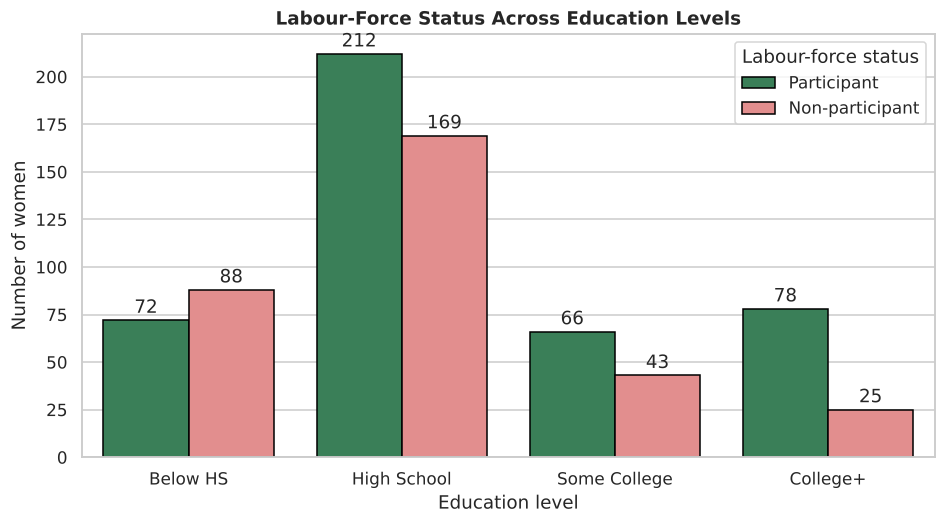

Participation rate by education level (%):
Edu_Level
Below HS       45.0000
High School    55.6000
Some College   60.6000
College+       75.7000


In [78]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=df4, x="Edu_Level", hue="LF_Status", palette=["seagreen", "lightcoral"],
              hue_order=["Participant", "Non-participant"], edgecolor="black", ax=ax)
for container in ax.containers:
    ax.bar_label(container, padding=2)
ax.set_title("Labour-Force Status Across Education Levels")
ax.set_xlabel("Education level")
ax.set_ylabel("Number of women")
ax.legend(title="Labour-force status")
plt.show()
print("Participation rate by education level (%):")
print((df4.groupby("Edu_Level", observed=True)["inlf"].mean() * 100).round(1).to_string())

### 4. Scatter plot of two numerical variables
**Variables:** husband's hourly wage (`huswage`) and family income (`faminc`). Pearson's $r$ is reported in the title.

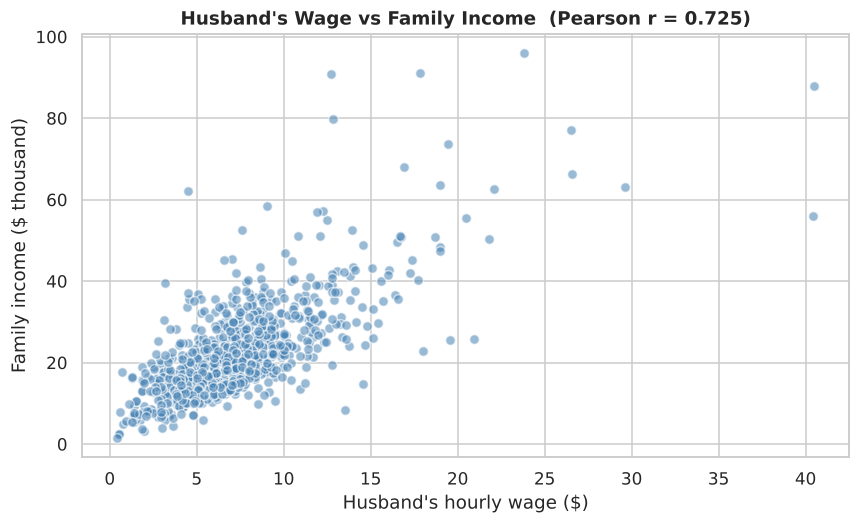

In [79]:
r4 = df4["huswage"].corr(df4["faminc"])
fig, ax = plt.subplots()
ax.scatter(df4["huswage"], df4["faminc"] / 1000, alpha=0.55, color="steelblue", edgecolor="white", s=40)
ax.set_title(f"Husband's Wage vs Family Income  (Pearson r = {r4:.3f})")
ax.set_xlabel("Husband's hourly wage ($)")
ax.set_ylabel("Family income ($ thousand)")
plt.show()

### 5. Line plot
**Variables:** years of schooling (`educ`) and the average hourly wage of working women at each level. A line plot is appropriate because `educ` is ordered, so the line shows the trend (the *return to education*).

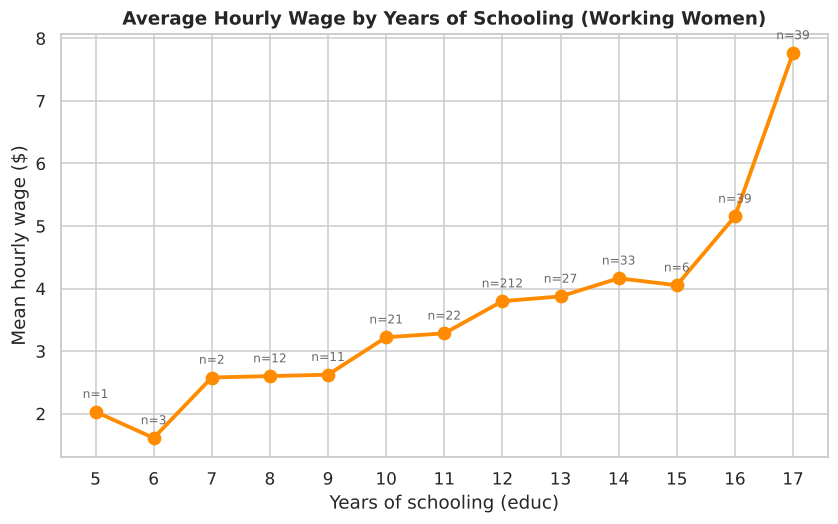

In [80]:
wage_by_educ = workers4.groupby("educ")["wage"].agg(["mean", "count"]).reset_index()
fig, ax = plt.subplots()
ax.plot(wage_by_educ["educ"], wage_by_educ["mean"], marker="o", ms=8, lw=2.5, color="darkorange")
for _, row in wage_by_educ.iterrows():
    ax.annotate(f"n={int(row['count'])}", (row["educ"], row["mean"]), textcoords="offset points",
                xytext=(0, 9), ha="center", fontsize=8, color="dimgray")
ax.set_xticks(wage_by_educ["educ"])
ax.set_title("Average Hourly Wage by Years of Schooling (Working Women)")
ax.set_xlabel("Years of schooling (educ)")
ax.set_ylabel("Mean hourly wage ($)")
plt.show()

### 6. Heatmap of numerical variables
A heatmap colours each cell of a matrix. Here it displays the Pearson correlation matrix of eight numerical variables (red = positive, blue = negative).

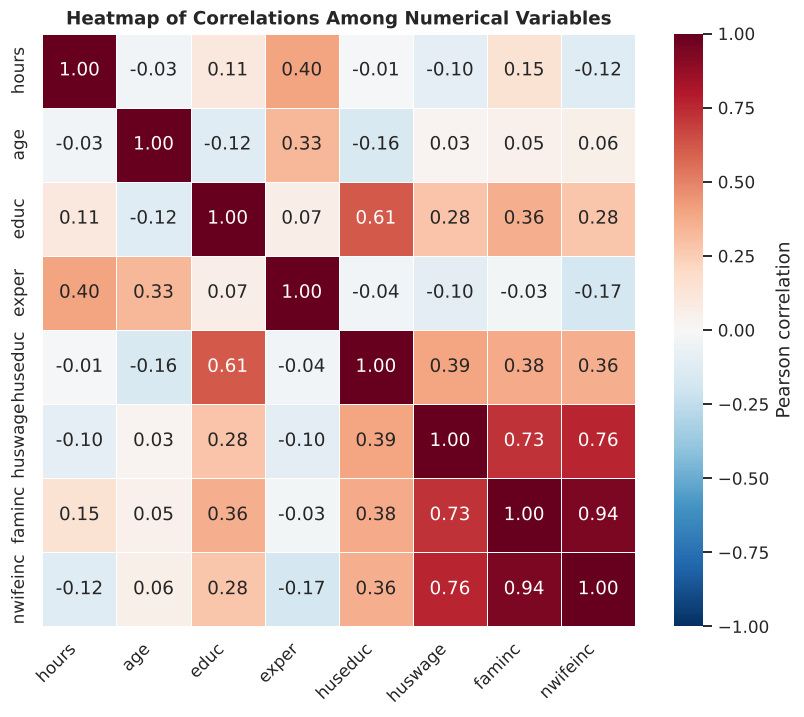

In [81]:
heat_vars = ["hours", "age", "educ", "exper", "huseduc", "huswage", "faminc", "nwifeinc"]
corr4 = df4[heat_vars].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr4, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_title("Heatmap of Correlations Among Numerical Variables")
plt.show()

### 7. Bar chart comparing two variables
**Variables:** wife's schooling (`educ`) and husband's schooling (`huseduc`). The frequencies of the two variables are compared level by level using paired bars.

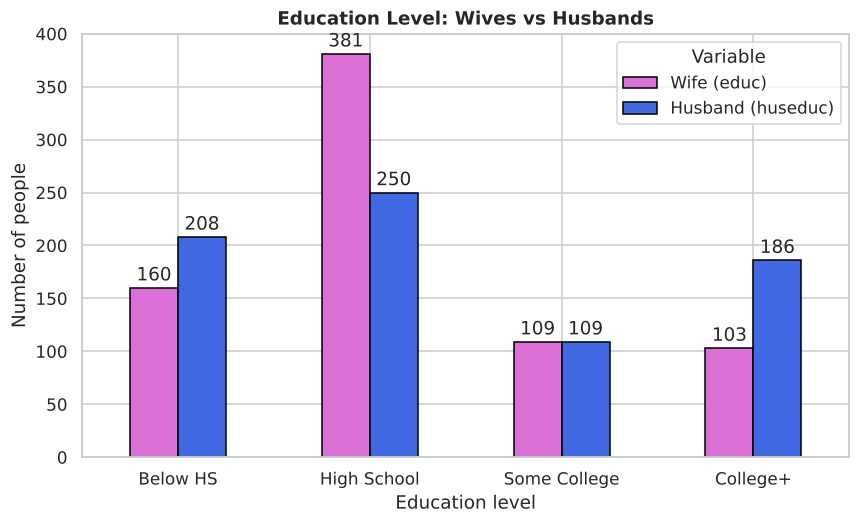

Mean years of schooling - wife: 12.29, husband: 12.49


In [82]:
edu_bins = [0, 11, 12, 15, 17]
edu_labels = ["Below HS", "High School", "Some College", "College+"]
compare = pd.DataFrame({
    "Wife (educ)": pd.cut(df4["educ"], edu_bins, labels=edu_labels).value_counts().sort_index(),
    "Husband (huseduc)": pd.cut(df4["huseduc"], edu_bins, labels=edu_labels).value_counts().sort_index()
})
ax = compare.plot(kind="bar", figsize=(9, 5), color=["orchid", "royalblue"], edgecolor="black", rot=0)
for container in ax.containers:
    ax.bar_label(container, padding=2)
ax.set_title("Education Level: Wives vs Husbands")
ax.set_xlabel("Education level")
ax.set_ylabel("Number of people")
ax.legend(title="Variable")
plt.show()
print(f"Mean years of schooling - wife: {df4['educ'].mean():.2f}, husband: {df4['huseduc'].mean():.2f}")

### 8. Density plot of a numerical variable across categories
**Variables:** non-wife family income (`nwifeinc`, \$ thousand) by `LF_Status`. Economic theory predicts an *income effect*: women with more income from other sources are less likely to work.

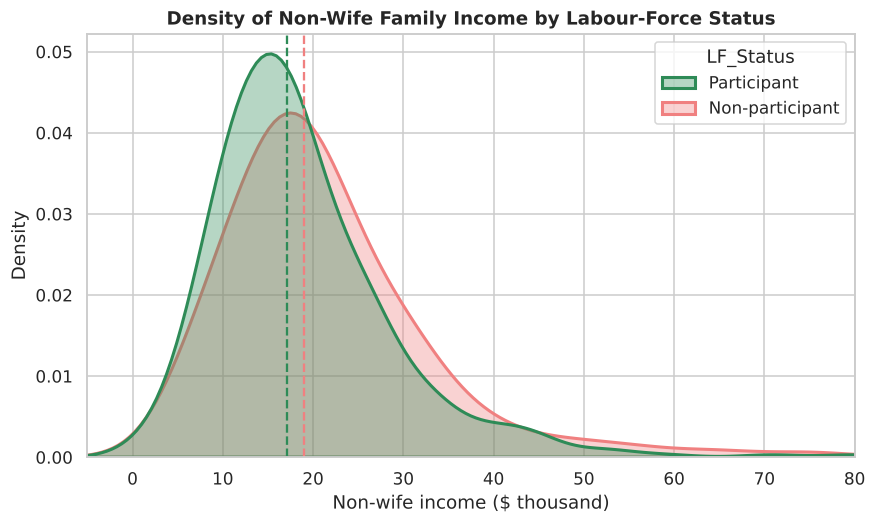

                   mean  median
LF_Status                      
Non-participant 21.7000 18.9700
Participant     18.9400 17.0800


In [83]:
fig, ax = plt.subplots()
sns.kdeplot(data=df4, x="nwifeinc", hue="LF_Status", fill=True, alpha=0.35, common_norm=False,
            palette={"Participant": "seagreen", "Non-participant": "lightcoral"}, lw=2, ax=ax)
for status, color in [("Participant", "seagreen"), ("Non-participant", "lightcoral")]:
    ax.axvline(df4.loc[df4["LF_Status"] == status, "nwifeinc"].median(), color=color, ls="--", lw=1.5)
ax.set_xlim(-5, 80)
ax.set_title("Density of Non-Wife Family Income by Labour-Force Status")
ax.set_xlabel("Non-wife income ($ thousand)")
ax.set_ylabel("Density")
plt.show()
print(df4.groupby("LF_Status")["nwifeinc"].agg(["mean", "median"]).round(2))

### 9. Box plot of a numerical variable across groups
**Variables:** hourly wage (`wage`) of working women by `Edu_Level`.

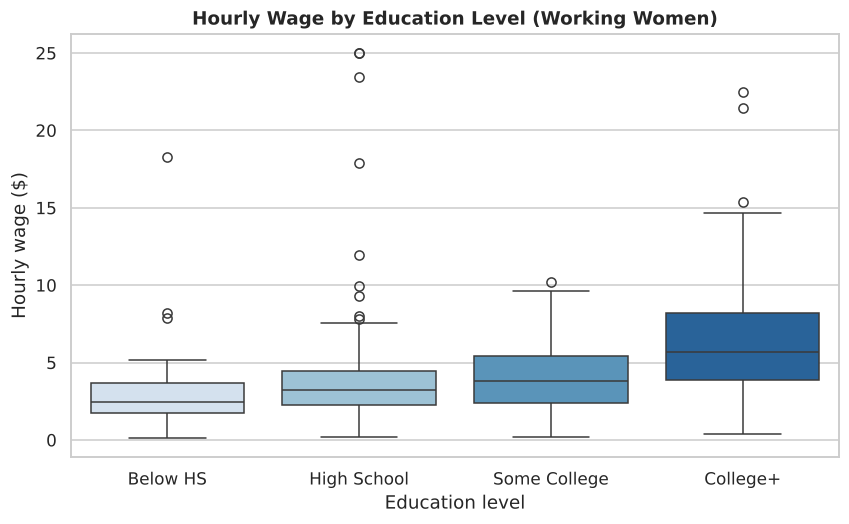

Edu_Level
Below HS       2.4600
High School    3.2400
Some College   3.8400
College+       5.6600


In [84]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=workers4, x="Edu_Level", y="wage", hue="Edu_Level", palette="Blues", legend=False, dodge=False, ax=ax)
ax.set_title("Hourly Wage by Education Level (Working Women)")
ax.set_xlabel("Education level")
ax.set_ylabel("Hourly wage ($)")
plt.show()
print(workers4.groupby("Edu_Level", observed=True)["wage"].median().round(2).to_string())

### 10. Violin plot
**Variables:** annual hours worked (`hours`) by working women, split by `Young_Kids`.

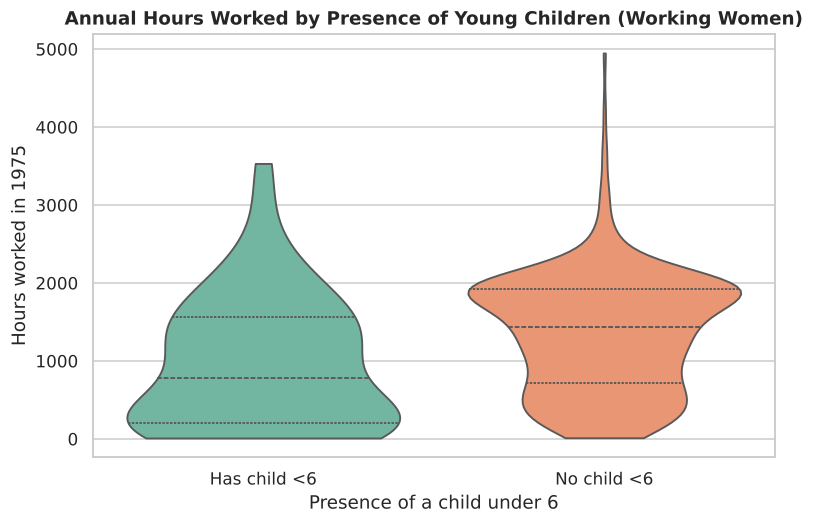

              count     mean   median
Young_Kids                           
Has child <6     53 965.4000 780.0000
No child <6     375 1,350.60 1,440.00


In [85]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=workers4, x="Young_Kids", y="hours", hue="Young_Kids", palette="Set2", inner="quartile",
               cut=0, legend=False, ax=ax)
ax.set_title("Annual Hours Worked by Presence of Young Children (Working Women)")
ax.set_xlabel("Presence of a child under 6")
ax.set_ylabel("Hours worked in 1975")
plt.show()
print(workers4.groupby("Young_Kids")["hours"].agg(["count", "mean", "median"]).round(1))

### 11. Violin plot combined with a box plot
**Variables:** log hourly wage (`lwage`) by `Edu_Level`. The violin shows the full density; the narrow box inside shows median and quartiles.

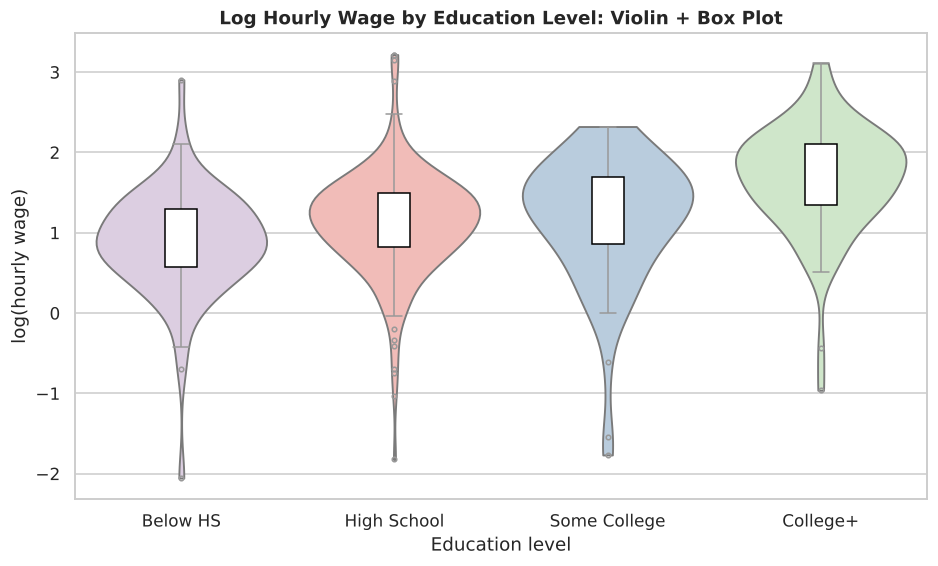

In [86]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.violinplot(data=workers4, x="Edu_Level", y="lwage", hue="Edu_Level", palette="Pastel1", inner=None,
               cut=0, legend=False, dodge=False, ax=ax)
sns.boxplot(data=workers4, x="Edu_Level", y="lwage", width=0.15, color="white", fliersize=3,
            boxprops={"zorder": 3, "edgecolor": "black"}, ax=ax)
ax.set_title("Log Hourly Wage by Education Level: Violin + Box Plot")
ax.set_xlabel("Education level")
ax.set_ylabel("log(hourly wage)")
plt.show()

### 12. Correlation matrix and correlogram
A **correlogram** (R: `corrplot`) encodes each correlation by both colour *and* circle size in the lower triangle, so strong relationships stand out immediately. It is computed for working women so that `wage` can be included.

,wage,hours,educ,exper,age,huswage,faminc,nwifeinc,kidslt6
wage,1.0000,-0.0980,0.3420,0.0550,0.0300,0.2160,0.3030,0.1420,0.0310
hours,-0.0980,1.0000,-0.0650,0.2990,0.0550,-0.1100,0.1510,-0.0810,-0.1680
educ,0.3420,-0.0650,1.0000,-0.0150,-0.0520,0.3030,0.3620,0.2840,0.1290
exper,0.0550,0.2990,-0.0150,1.0000,0.4840,-0.1120,-0.0270,-0.1610,-0.1860
age,0.0300,0.0550,-0.0520,0.4840,1.0000,0.0890,0.1140,0.0970,-0.3380
huswage,0.2160,-0.1100,0.3030,-0.1120,0.0890,1.0000,0.6690,0.6980,-0.0210
faminc,0.3030,0.1510,0.3620,-0.0270,0.1140,0.6690,1.0000,0.9300,-0.0720
nwifeinc,0.1420,-0.0810,0.2840,-0.1610,0.0970,0.6980,0.9300,1.0000,-0.0280
kidslt6,0.0310,-0.1680,0.1290,-0.1860,-0.3380,-0.0210,-0.0720,-0.0280,1.0000


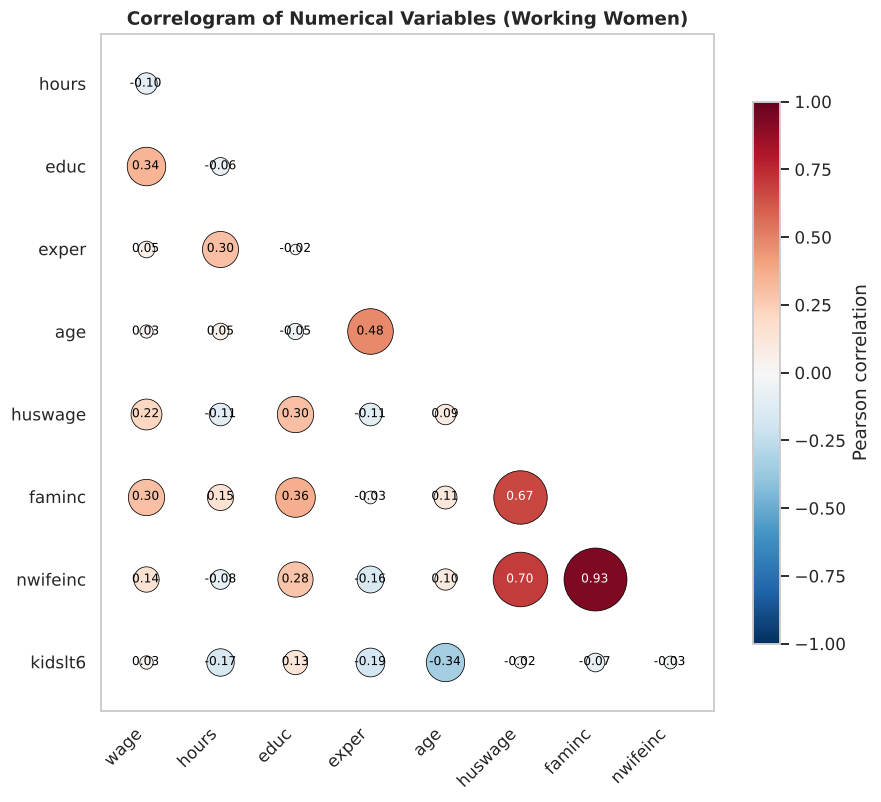

In [87]:
cg_vars = ["wage", "hours", "educ", "exper", "age", "huswage", "faminc", "nwifeinc", "kidslt6"]
corr12 = workers4[cg_vars].corr()
display(corr12.round(3))

n = len(cg_vars)
fig, ax = plt.subplots(figsize=(9, 8))
cmap = plt.get_cmap("RdBu_r")
for i in range(n):
    for jj in range(n):
        if i > jj:
            r = corr12.iloc[i, jj]
            ax.scatter(jj, i, s=abs(r) * 1800 + 20, color=cmap((r + 1) / 2), edgecolor="black", lw=0.5)
            ax.text(jj, i, f"{r:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(r) > 0.5 else "black")
ax.set_xlim(-0.6, n - 1.4)
ax.set_ylim(n - 0.4, 0.4)
ax.set_xticks(range(n - 1))
ax.set_xticklabels(cg_vars[:-1], rotation=45, ha="right")
ax.set_yticks(range(1, n))
ax.set_yticklabels(cg_vars[1:])
ax.grid(False)
sm_ = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(-1, 1))
fig.colorbar(sm_, ax=ax, label="Pearson correlation", shrink=0.8)
ax.set_title("Correlogram of Numerical Variables (Working Women)")
plt.show()

**Interpretation of the bivariate plots (working women).**
* **Line plot / box plot:** wages rise with schooling – median hourly wage \$2.46 (Below HS), \$3.24 (High School), \$3.84 (Some College) and \$5.66 (College+); the mean wage jumps sharply at 16–17 years (college degree). Wage dispersion also widens at higher education.
* **Density plot:** participants have slightly lower non-wife income (median \$17.1k vs \$19.0k), consistent with the income effect: a higher income from other sources lowers the need to work.
* **Violin plot:** working mothers of young children work fewer hours (mean 965 vs 1,351 hours), and their distribution is concentrated at part-time levels.
* **Correlogram:** the strongest relationships are `faminc`–`nwifeinc` (r = 0.93, expected since non-wife income is most of family income), `nwifeinc`–`huswage` (0.70) and `faminc`–`huswage` (0.67). Among the wife's own variables, `educ`–`wage` (0.34) is the strongest predictor of her wage, `age`–`exper` (0.48) reflects time in the labour market, and `kidslt6`–`age` (−0.34) shows young children belong to younger mothers. Correlations between `hours` and `wage` are close to zero.

### 13. Titles, labels, legends and graphical parameters
Every plot in this assessment has a descriptive title, labelled axes with units, a legend wherever colour encodes a variable, and consistent colours (green = participant, red = non-participant).

---
# Assessment 5 – Multivariate Analysis
**Theory.** Multivariate visualisation displays three or more variables at once by mapping them to additional *aesthetics* – colour, shape, size, or separate panels (*facets*) – or by using specialised displays such as pair plots and parallel coordinate plots. This reveals interactions that two-variable plots cannot show.

### 1. Load the dataset and identify numerical and categorical variables

In [88]:
df5 = add_labels(pd.read_csv(URL).drop(columns="rownames"))
workers5 = df5[df5["inlf"] == 1].copy()

binary_codes = [c for c in df5.select_dtypes("number").columns if df5[c].nunique() == 2]
numeric_vars = [c for c in df5.select_dtypes("number").columns if c not in binary_codes]
categorical_vars = binary_codes + df5.select_dtypes(exclude="number").columns.tolist()
print("Numerical variables  :", numeric_vars)
print("Categorical variables:", categorical_vars)
print("\n(inlf and city are stored as numbers but are 0/1 category codes; the last five are derived labels.)")

Numerical variables  : ['hours', 'kidslt6', 'kidsge6', 'age', 'educ', 'wage', 'repwage', 'hushrs', 'husage', 'huseduc', 'huswage', 'faminc', 'mtr', 'motheduc', 'fatheduc', 'unem', 'exper', 'nwifeinc', 'lwage', 'expersq']
Categorical variables: ['inlf', 'city', 'LF_Status', 'Residence', 'Young_Kids', 'Edu_Level', 'Age_Group']

(inlf and city are stored as numbers but are 0/1 category codes; the last five are derived labels.)


### 2. Scatter plot with three variables (x, y, colour)
x = `age`, y = `faminc`, colour = `LF_Status`.

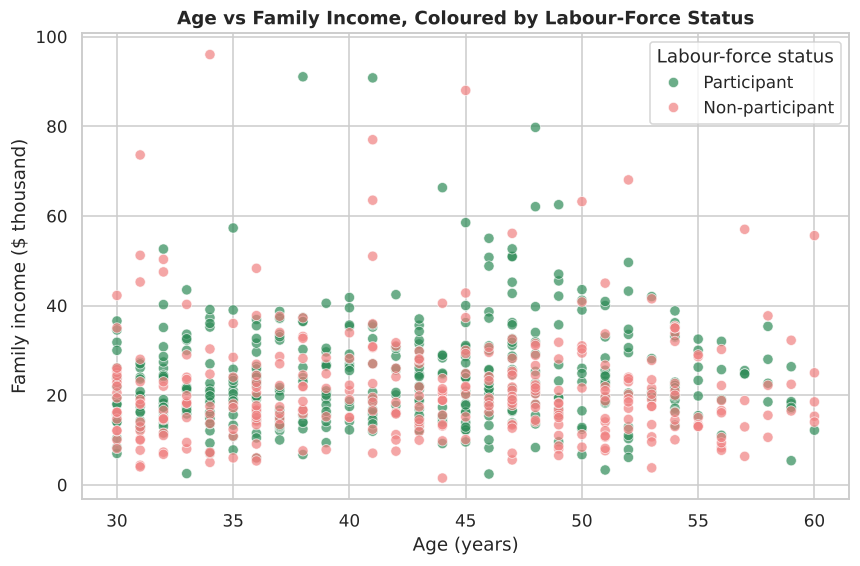

In [89]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=df5, x="age", y=df5["faminc"] / 1000, hue="LF_Status",
                palette={"Participant": "seagreen", "Non-participant": "lightcoral"}, alpha=0.7, s=45, ax=ax)
ax.set_title("Age vs Family Income, Coloured by Labour-Force Status")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Family income ($ thousand)")
ax.legend(title="Labour-force status")
plt.show()

### 3. Scatter plot with four variables (x, y, colour, shape)
x = `educ`, y = `wage`, colour = `Young_Kids`, shape = `Residence` (working women).

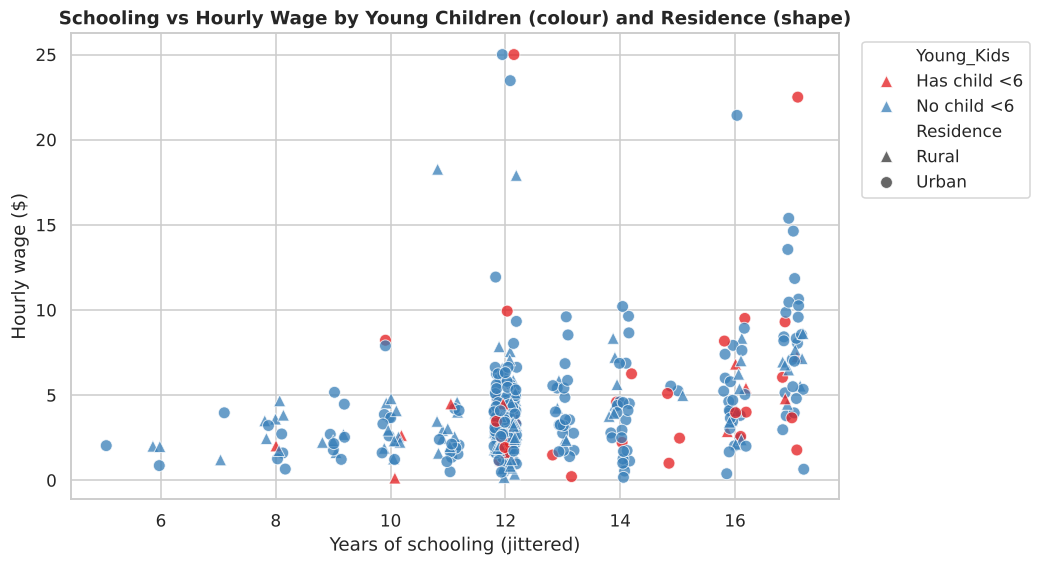

In [90]:
fig, ax = plt.subplots(figsize=(9, 5.5))
jitter = np.random.default_rng(173).uniform(-0.2, 0.2, len(workers5))
sns.scatterplot(x=workers5["educ"] + jitter, y=workers5["wage"], hue=workers5["Young_Kids"], style=workers5["Residence"],
                markers={"Urban": "o", "Rural": "^"}, palette="Set1", s=60, alpha=0.75, ax=ax)
ax.set_title("Schooling vs Hourly Wage by Young Children (colour) and Residence (shape)")
ax.set_xlabel("Years of schooling (jittered)")
ax.set_ylabel("Hourly wage ($)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### 4. Scatter plot with four variables (x, y, colour, size)
x = `exper`, y = `lwage`, colour = `Edu_Level`, size = `hours` (numerical).

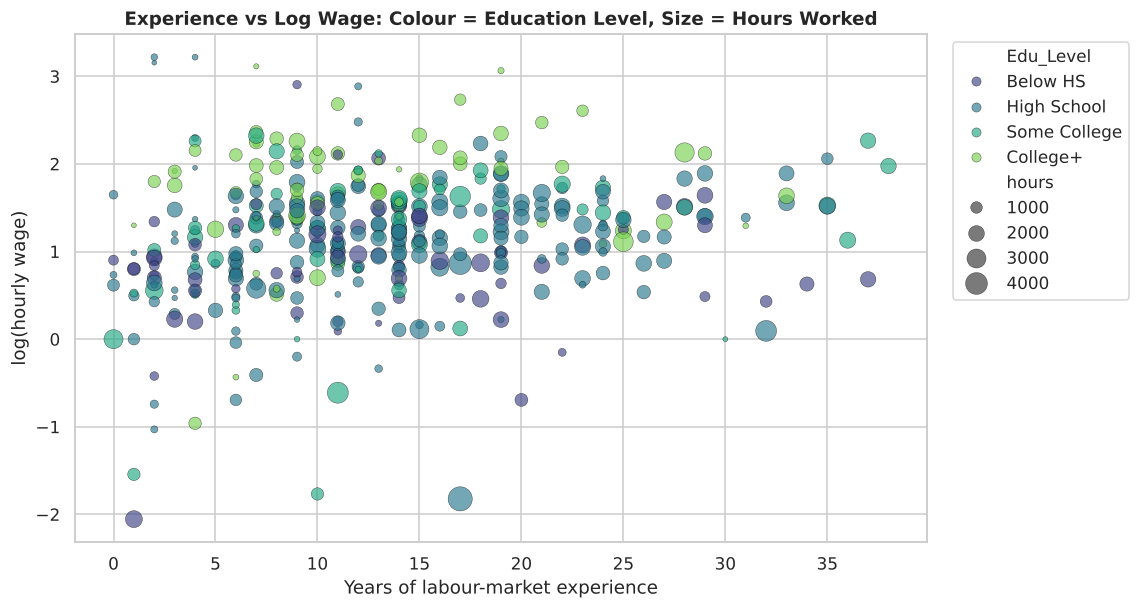

In [91]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=workers5, x="exper", y="lwage", hue="Edu_Level", size="hours", sizes=(10, 250),
                palette="viridis", alpha=0.65, edgecolor="black", linewidth=0.3, ax=ax)
ax.set_title("Experience vs Log Wage: Colour = Education Level, Size = Hours Worked")
ax.set_xlabel("Years of labour-market experience")
ax.set_ylabel("log(hourly wage)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### 5. Bubble plot with three numerical variables
x = `huswage`, y = `faminc` (\$ thousand), bubble size = `hushrs` (husband's annual hours). The bubble colour repeats `hushrs` to aid reading.

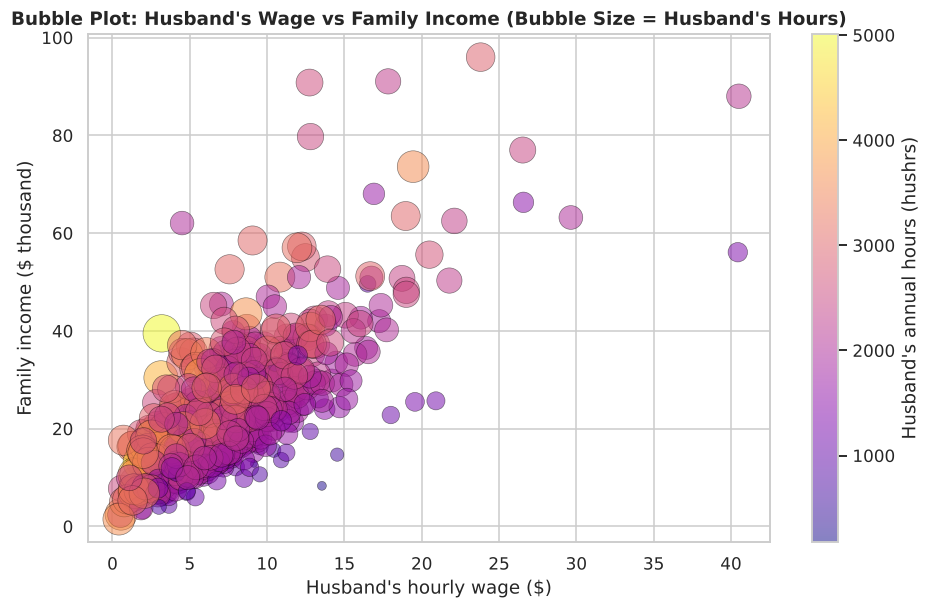

In [92]:
fig, ax = plt.subplots(figsize=(10, 6))
bubble = ax.scatter(df5["huswage"], df5["faminc"] / 1000, s=(df5["hushrs"] / df5["hushrs"].max()) * 600,
                    c=df5["hushrs"], cmap="plasma", alpha=0.5, edgecolor="black", linewidth=0.4)
fig.colorbar(bubble, ax=ax, label="Husband's annual hours (hushrs)")
ax.set_title("Bubble Plot: Husband's Wage vs Family Income (Bubble Size = Husband's Hours)")
ax.set_xlabel("Husband's hourly wage ($)")
ax.set_ylabel("Family income ($ thousand)")
plt.show()

**Interpretation of the colour, shape, size and bubble plots.** Family income is high at every age for some women, so age alone separates participants and non-participants poorly (task 2). In task 3, wages rise with schooling in both rural and urban areas, and women with young children (red) are scattered through the same range rather than forming a separate group. In task 4, larger bubbles (more hours) are spread across all experience levels, while the highest log wages belong mostly to the more educated groups. The bubble plot (task 5) shows family income rising almost linearly with the husband's wage; families with large bubbles (husbands working long hours) appear even at low hourly wages, where long hours partly make up for a low rate of pay.

### 6. Subplots with `facet_wrap()`
One panel per `Age_Group`: experience vs log wage with a fitted regression line, for working women.

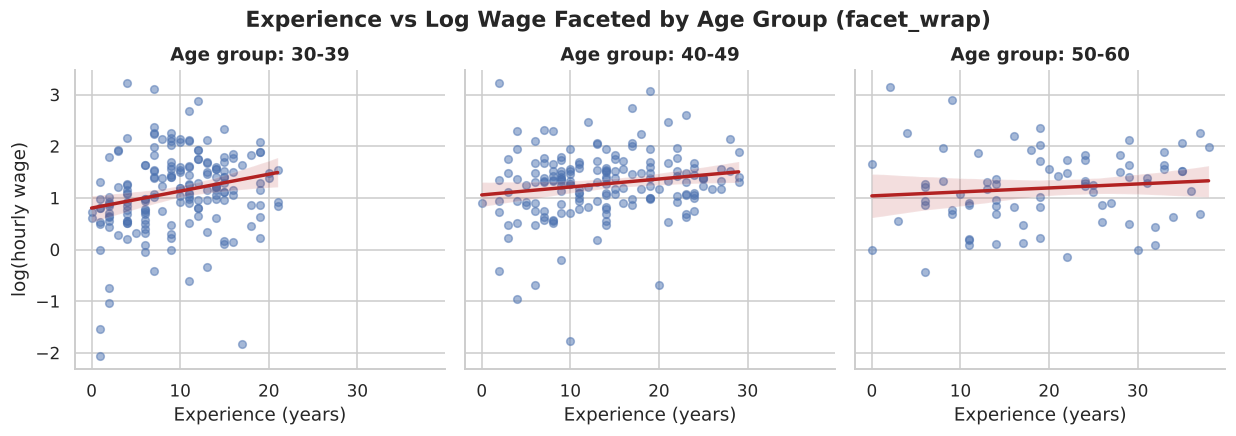

In [93]:
g = sns.lmplot(data=workers5, x="exper", y="lwage", col="Age_Group", col_wrap=3, height=3.8, aspect=1,
               scatter_kws={"alpha": 0.5, "s": 25}, line_kws={"color": "firebrick"})
g.set_titles("Age group: {col_name}")
g.set_axis_labels("Experience (years)", "log(hourly wage)")
g.fig.suptitle("Experience vs Log Wage Faceted by Age Group (facet_wrap)", y=1.04, fontweight="bold")
plt.show()

### 7. Subplots with `facet_grid()` (rows × columns)
Rows = `Residence`, columns = `Young_Kids`; each panel is the distribution of non-wife income, coloured by labour-force status. This compares four sub-populations at once.

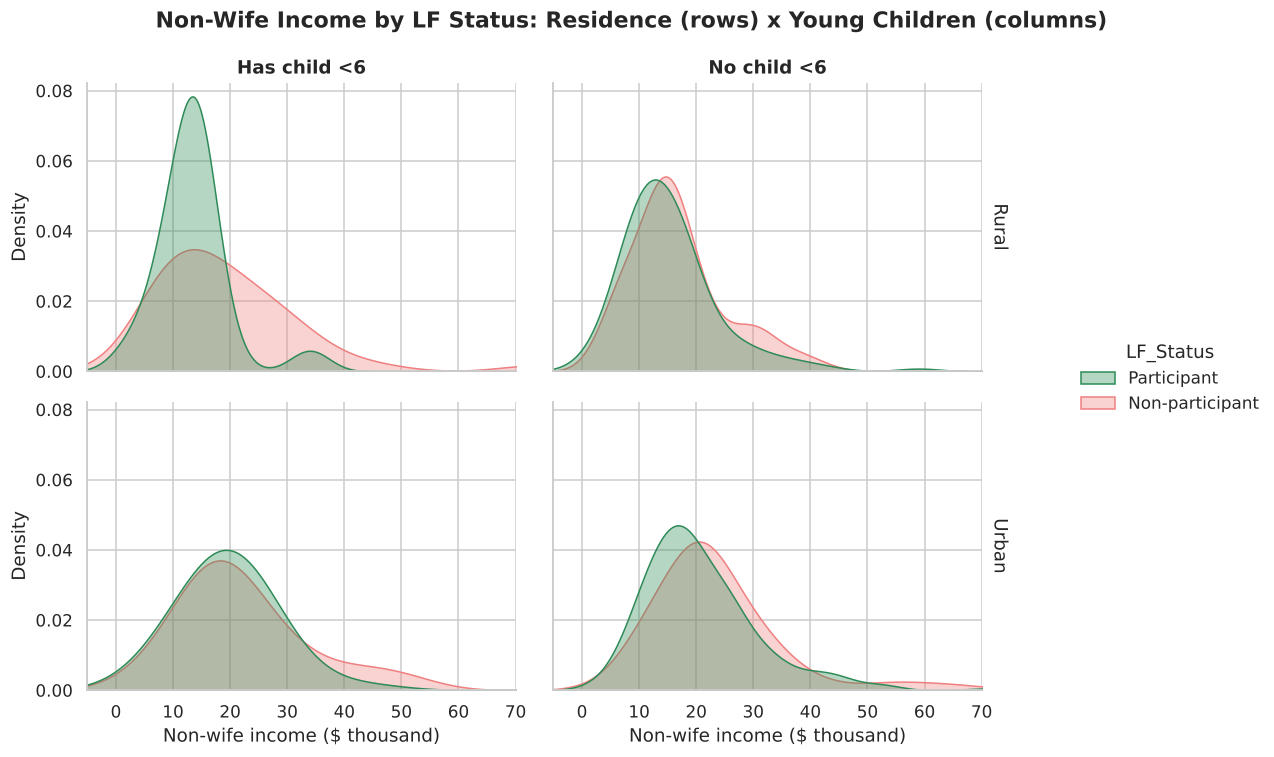

n  participation_rate  median_nwifeinc
Residence Young_Kids                                            
Rural     Has child <6   58             34.5000          14.7500
          No child <6   211             63.5000          14.1970
Urban     Has child <6   89             37.1000          19.0220
          No child <6   395             61.0000          20.2000

In [94]:
g = sns.displot(data=df5, x="nwifeinc", hue="LF_Status", row="Residence", col="Young_Kids", kind="kde",
                fill=True, common_norm=False, alpha=0.35, height=3.3, aspect=1.5,
                palette={"Participant": "seagreen", "Non-participant": "lightcoral"},
                facet_kws={"margin_titles": True})
g.set_titles(row_template="{row_name}", col_template="{col_name}")
g.set_axis_labels("Non-wife income ($ thousand)", "Density")
g.set(xlim=(-5, 70))
g.fig.suptitle("Non-Wife Income by LF Status: Residence (rows) x Young Children (columns)", y=1.04, fontweight="bold")
plt.show()

summary_grid = df5.groupby(["Residence", "Young_Kids"]).agg(
    n=("inlf", "size"), participation_rate=("inlf", "mean"), median_nwifeinc=("nwifeinc", "median"))
summary_grid["participation_rate"] = (summary_grid["participation_rate"] * 100).round(1)
summary_grid

**Interpretation of the facet plots.** In the `facet_wrap` panels the experience–wage slope is steepest for women aged 30–39 and almost flat for 50–60, i.e. early-career experience pays off most. In the `facet_grid` the striking comparison is across columns: in **both** rural and urban areas, participation is about 35–37% for women with a child under six, against about 61–64% without. The rows differ mainly in income level: urban families have a higher median non-wife income (about \$19–20k vs \$14–15k). The participant and non-participant curves largely overlap within each panel, so non-wife income is a much weaker driver of participation than the presence of young children.

### 8. Pairs plot (at least four numerical variables)
Diagonal = distribution of each variable by group; off-diagonal = pairwise scatter plots.

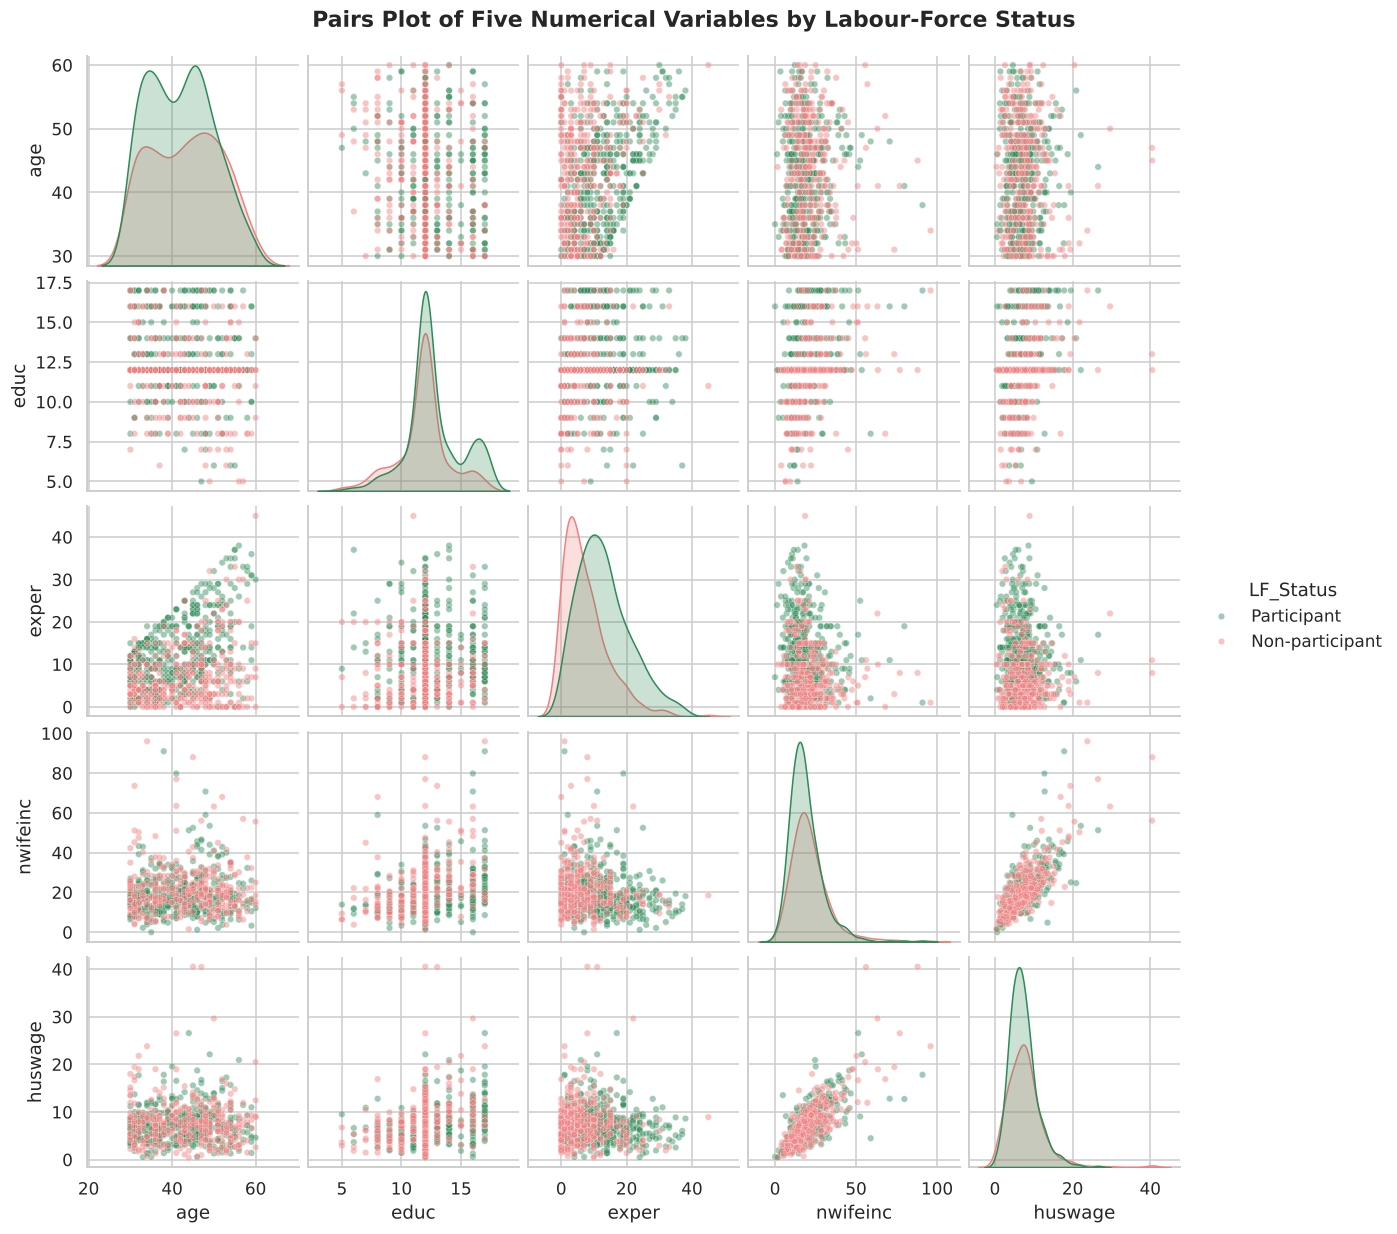

,age,educ,exper,nwifeinc,huswage
age,1.0000,-0.1200,0.3340,0.0590,0.0270
educ,-0.1200,1.0000,0.0660,0.2780,0.2850
exper,0.3340,0.0660,1.0000,-0.1720,-0.1030
nwifeinc,0.0590,0.2780,-0.1720,1.0000,0.7580
huswage,0.0270,0.2850,-0.1030,0.7580,1.0000


In [95]:
pair_vars = ["age", "educ", "exper", "nwifeinc", "huswage"]
g = sns.pairplot(df5, vars=pair_vars, hue="LF_Status", palette={"Participant": "seagreen", "Non-participant": "lightcoral"},
                 diag_kind="kde", plot_kws={"alpha": 0.45, "s": 18}, height=2.2)
g.fig.suptitle("Pairs Plot of Five Numerical Variables by Labour-Force Status", y=1.02, fontweight="bold")
plt.show()
df5[pair_vars].corr().round(3)

**Interpretation.** The clearest pairwise pattern is the strong positive relationship between husband's wage and non-wife income (r = 0.76). Age and experience are moderately related (0.33), and the wife's education is positively related to both husband's wage (0.29) and non-wife income (0.28). On the diagonal, participants (green) have a visibly higher `exper` distribution than non-participants, while their `age` and `nwifeinc` distributions overlap heavily.

### 9. Parallel coordinate plot
Each woman is one line crossing parallel vertical axes, one per variable. Variables are min–max scaled to [0, 1] so that all axes are comparable, and lines are coloured by `LF_Status`. The thick lines are the group means.

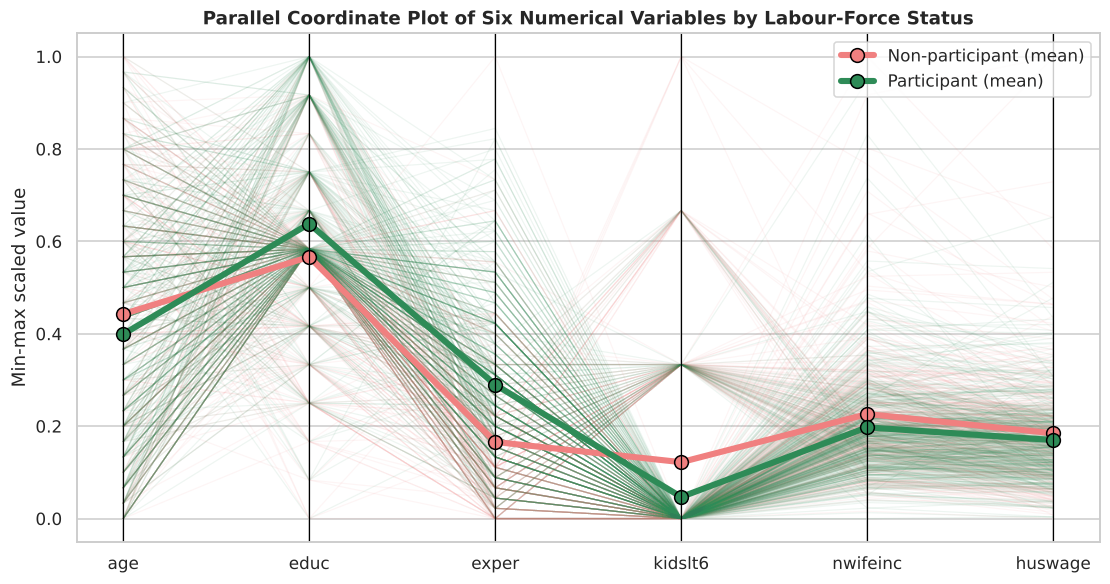

In [96]:
pc_vars = ["age", "educ", "exper", "kidslt6", "nwifeinc", "huswage"]
pc = df5[pc_vars].apply(lambda s: (s - s.min()) / (s.max() - s.min()))
pc["LF_Status"] = df5["LF_Status"]
colors_pc = {"Participant": "seagreen", "Non-participant": "lightcoral"}

fig, ax = plt.subplots(figsize=(12, 6))
for status in ["Non-participant", "Participant"]:
    sub = pc[pc["LF_Status"] == status]
    ax.plot(range(len(pc_vars)), sub[pc_vars].T.values, color=colors_pc[status], alpha=0.08, lw=0.8)
for status in ["Non-participant", "Participant"]:
    ax.plot(range(len(pc_vars)), pc.loc[pc["LF_Status"] == status, pc_vars].mean(), color=colors_pc[status],
            lw=4, marker="o", ms=9, markeredgecolor="black", label=f"{status} (mean)")
for x in range(len(pc_vars)):
    ax.axvline(x, color="black", lw=0.8)
ax.set_xticks(range(len(pc_vars)))
ax.set_xticklabels(pc_vars)
ax.set_ylabel("Min-max scaled value")
ax.set_title("Parallel Coordinate Plot of Six Numerical Variables by Labour-Force Status")
ax.legend(loc="upper right")
plt.show()

**Interpretation.** The group-mean lines separate most on **experience** (participants higher), **young children** (non-participants higher) and **education** (participants higher). On age, non-wife income and husband's wage the two means are nearly equal. The parallel coordinate plot therefore summarises the multivariate profile of a working woman: more educated, more experienced and less likely to have a child under six.

---
# Assessment 6 – Time Series Analysis
**Theory.** A time series is a sequence of observations ordered in time. Classical analysis:
1. **Decomposition** splits the series into **trend** (long-run level), **seasonal** (repeating pattern of fixed period) and **random** (irregular) components. In the additive model $Y_t = T_t + S_t + R_t$.
2. **ACF / PACF.** The autocorrelation function measures the correlation between $Y_t$ and $Y_{t-k}$; the partial autocorrelation removes the effect of intermediate lags. Their cut-off patterns suggest the AR order $p$ (PACF) and MA order $q$ (ACF).
3. **ARIMA(p, d, q)** models a series after $d$ differences as a combination of $p$ autoregressive and $q$ moving-average terms, and is then used to **forecast**.

### How the AirPassengers tasks are applied to the Mroz dataset
The question uses R's built-in `AirPassengers` (monthly airline passengers, 1949–1960, frequency 12). As instructed, the same workflow is applied to the Mroz dataset. Mroz is a **cross-section** (753 women surveyed in 1975) and has no date column, so a time index has to be constructed:
* **Series:** family income `faminc` (in \$ thousand).
* **Time index:** the 753 records in their stored file order, treated as consecutive **monthly** observations starting January 1949 – the same start and frequency (12) as `AirPassengers`.

Because the index is artificial, the results must be read with this in mind: any “trend” reflects how the file is ordered (all participants are listed before all non-participants), and genuine seasonality is not expected. Recognising this is itself part of a correct analysis.

### 1. Load the dataset and build the time series

In [97]:
df6 = pd.read_csv(URL)
ts_index = pd.date_range(start="1949-01-01", periods=len(df6), freq="MS")
ts = pd.Series((df6["faminc"] / 1000).values, index=ts_index, name="faminc_k")
print(f"Time series of family income ($ thousand) with {len(ts)} monthly observations")

Time series of family income ($ thousand) with 753 monthly observations


### 2. First five and last five observations

In [98]:
print("First five observations:")
display(ts.head(5).to_frame())
print("Last five observations:")
display(ts.tail(5).to_frame())

First five observations:


,faminc_k
1949-01-01,16.3100
1949-02-01,21.8000
1949-03-01,21.0400
1949-04-01,7.3000
1949-05-01,27.3000


Last five observations:


,faminc_k
2011-05-01,28.2000
2011-06-01,10.0000
2011-07-01,9.9520
2011-08-01,24.9840
2011-09-01,28.3630


### 3. Starting and ending time periods (`start`, `end`)

In [99]:
print("Start:", ts.index[0].strftime("%B %Y"), "->", (ts.index[0].year, ts.index[0].month))
print("End  :", ts.index[-1].strftime("%B %Y"), "->", (ts.index[-1].year, ts.index[-1].month))

Start: January 1949 -> (1949, 1)
End  : September 2011 -> (2011, 9)


### 4. Frequency and time-series characteristics (`frequency`, `class`)

In [100]:
print("Frequency (observations per cycle):", 12)
print("pandas frequency code             :", ts.index.freqstr, "(month start)")
print("Class                             :", type(ts).__name__, "with", type(ts.index).__name__)
print("Number of observations            :", len(ts))
print(f"Span                              : {len(ts) / 12:.2f} 'years'")
print(f"Mean = {ts.mean():.3f}, SD = {ts.std():.3f}, Min = {ts.min():.3f}, Max = {ts.max():.3f}")
adf = adfuller(ts, autolag="AIC")
print(f"Augmented Dickey-Fuller test: statistic = {adf[0]:.3f}, p-value = {adf[1]:.4f}",
      "-> stationary" if adf[1] < 0.05 else "-> non-stationary")

Frequency (observations per cycle): 12
pandas frequency code             : MS (month start)
Class                             : Series with DatetimeIndex
Number of observations            : 753
Span                              : 62.75 'years'
Mean = 23.081, SD = 12.190, Min = 1.500, Max = 96.000
Augmented Dickey-Fuller test: statistic = -25.836, p-value = 0.0000 -> stationary


### 5. Visualise the series over the entire period (`plot`)

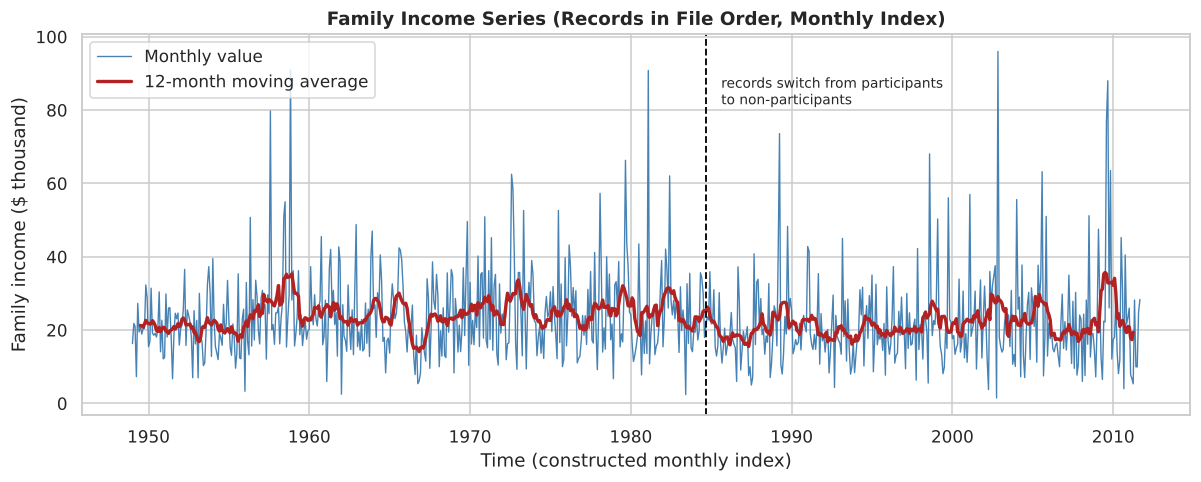

In [101]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(ts, color="steelblue", lw=0.9, label="Monthly value")
ax.plot(ts.rolling(12, center=True).mean(), color="firebrick", lw=2.2, label="12-month moving average")
boundary = ts.index[df6["inlf"].eq(0).idxmax()]
ax.axvline(boundary, color="black", ls="--", lw=1.2)
ax.annotate("records switch from participants\nto non-participants", (boundary, ts.max() * 0.85), xytext=(10, 0),
            textcoords="offset points", fontsize=9)
ax.set_title("Family Income Series (Records in File Order, Monthly Index)")
ax.set_xlabel("Time (constructed monthly index)")
ax.set_ylabel("Family income ($ thousand)")
ax.legend(loc="upper left")
plt.show()

### 6. Decompose into trend, seasonal and random components (`decompose`)
`seasonal_decompose(model="additive", period=12)` reproduces R's `decompose()`: the trend is a centred 12-month moving average, the seasonal component is the average de-trended value for each calendar month, and the remainder is the random component.

In [102]:
decomp = seasonal_decompose(ts, model="additive", period=12)
seasonal_profile = decomp.seasonal.iloc[:12]
seasonal_profile.index = seasonal_profile.index.strftime("%b")
print("Estimated seasonal effect for each month ($ thousand):")
print(seasonal_profile.round(3).to_string())

Estimated seasonal effect for each month ($ thousand):
Jan   -0.5790
Feb    0.3460
Mar   -0.7190
Apr   -2.0540
May   -0.2970
Jun   -2.5070
Jul   -0.0260
Aug    1.5270
Sep    2.3870
Oct   -0.8270
Nov    3.4340
Dec   -0.6850


### 7. Plot the decomposed components

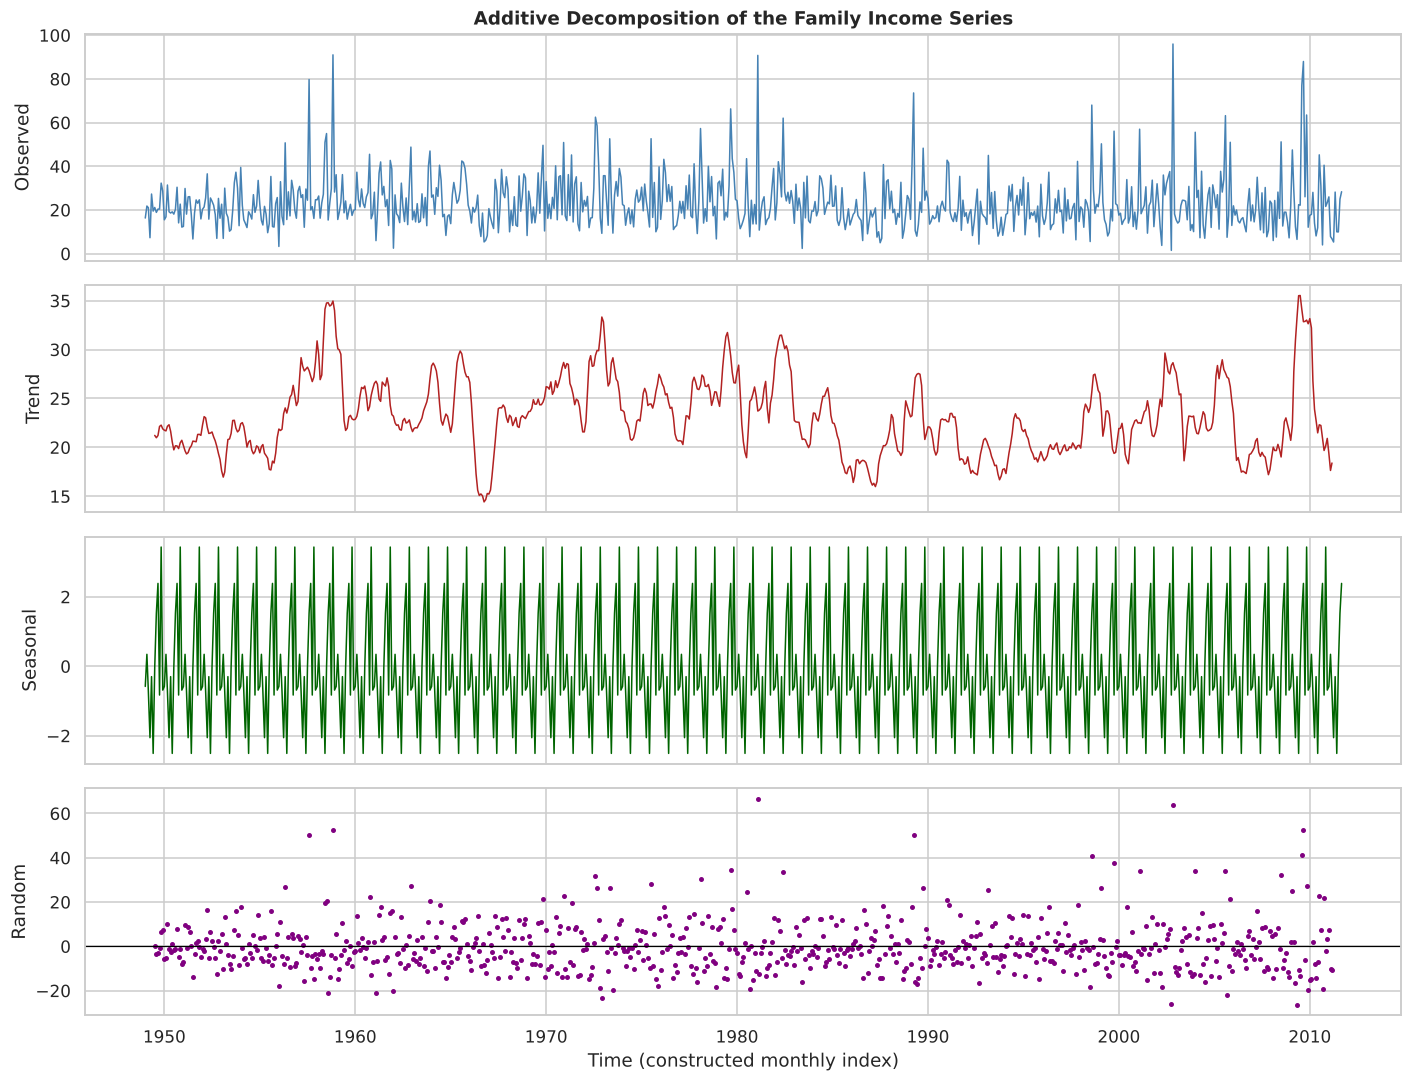

Share of variance by component (%):
Trend       9.8900
Seasonal    1.8300
Random     88.2900


In [103]:
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
parts = [(decomp.observed, "Observed", "steelblue"), (decomp.trend, "Trend", "firebrick"),
         (decomp.seasonal, "Seasonal", "darkgreen"), (decomp.resid, "Random", "purple")]
for ax, (series, label, color) in zip(axes, parts):
    if label == "Random":
        ax.scatter(series.index, series, s=5, color=color)
        ax.axhline(0, color="black", lw=0.8)
    else:
        ax.plot(series, color=color, lw=1)
    ax.set_ylabel(label)
axes[0].set_title("Additive Decomposition of the Family Income Series")
axes[-1].set_xlabel("Time (constructed monthly index)")
plt.tight_layout()
plt.show()

var_parts = pd.Series({"Trend": decomp.trend.var(), "Seasonal": decomp.seasonal.var(), "Random": decomp.resid.var()})
print("Share of variance by component (%):")
print((100 * var_parts / var_parts.sum()).round(2).to_string())

**Interpretation.** The ADF test (statistic −25.8, p < 0.001) shows the series is already **stationary**: there is no long-run trend, unlike AirPassengers. In the decomposition, the "trend" is a wandering 12-month moving average around \$20–25k with no direction, the seasonal component accounts for only about 2% of the variance, and the random component accounts for about 88%. The level shift that might be expected where the file switches from participants to non-participants (record 429) is small, because family income differs only modestly between the two groups (means \$24.1k vs \$21.7k). This is the correct conclusion for a cross-section: the "time" order carries no information.

### 8. Autocorrelation and partial autocorrelation (`acf`, `pacf`)
The shaded band is the 95% confidence region; spikes outside it are statistically significant. The Ljung–Box test checks whether the first 12 autocorrelations are jointly zero.

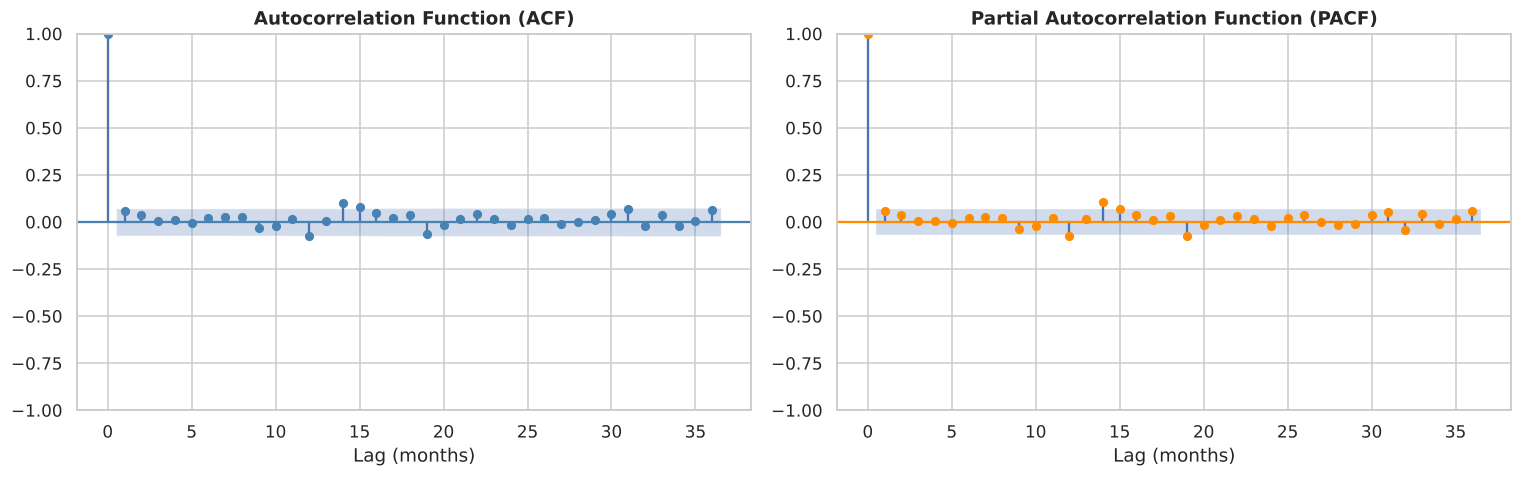

Ljung-Box test on the series:
    lb_stat  lb_pvalue
12  10.9460     0.5335
24  32.0375     0.1261


In [104]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_acf(ts, lags=36, ax=axes[0], color="steelblue")
plot_pacf(ts, lags=36, ax=axes[1], method="ywm", color="darkorange")
axes[0].set_title("Autocorrelation Function (ACF)")
axes[1].set_title("Partial Autocorrelation Function (PACF)")
for ax in axes:
    ax.set_xlabel("Lag (months)")
plt.tight_layout()
plt.show()

lb = sm.stats.acorr_ljungbox(ts, lags=[12, 24], return_df=True)
print("Ljung-Box test on the series:")
print(lb.round(4))

**Interpretation.** Apart from lag 0, almost every ACF and PACF spike lies inside the 95% band, and there is no spike at the seasonal lags 12, 24 or 36. The Ljung–Box tests do not reject independence (p = 0.53 at lag 12 and 0.13 at lag 24). The series therefore behaves like **white noise**, so at most a very small AR or MA term is justified.

### 9. Fit an ARIMA model (`arima`)
Instead of guessing the order, the model is chosen in two steps:
1. **Differencing order $d$** comes from the Augmented Dickey–Fuller test (Task 4): if the series is already stationary, $d = 0$; otherwise $d = 1$.
2. **AR and MA orders** – every ARIMA(p, d, q) with $p, q \in \{0, 1, 2\}$ is fitted and the one with the lowest **AIC** (Akaike Information Criterion, which rewards fit and penalises complexity) is selected. AIC values are only compared between models with the same $d$, because differencing changes the data being modelled.

In [105]:
d_order = 0 if adfuller(ts, autolag="AIC")[1] < 0.05 else 1
results = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for p in range(3):
        for q in range(3):
            fit = ARIMA(ts, order=(p, d_order, q)).fit()
            results.append({"order": (p, d_order, q), "AIC": fit.aic, "BIC": fit.bic})
    aic_table = pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)
    best_order = aic_table.loc[0, "order"]
    arima_fit = ARIMA(ts, order=best_order).fit()
print("Differencing order chosen from the ADF test: d =", d_order)
display(aic_table)
print("Selected model: ARIMA", best_order)

Differencing order chosen from the ADF test: d = 0


,order,AIC,BIC
0,"(1, 0, 0)","5,905.31","5,919.19"
1,"(0, 0, 1)","5,905.49","5,919.36"
2,"(0, 0, 0)","5,905.87","5,915.12"
3,"(2, 0, 0)","5,906.35","5,924.85"
4,"(1, 0, 1)","5,906.39","5,924.89"
5,"(0, 0, 2)","5,906.40","5,924.90"
6,"(2, 0, 1)","5,908.34","5,931.46"
7,"(1, 0, 2)","5,908.35","5,931.47"
8,"(2, 0, 2)","5,910.23","5,937.97"


Selected model: ARIMA (1, 0, 0)


### 10. Model parameters and summary (`summary`)

In [106]:
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:               faminc_k   No. Observations:                  753
Model:                 ARIMA(1, 0, 0)   Log Likelihood               -2949.657
Date:                Fri, 16 Oct 2026   AIC                           5905.313
Time:                        16:18:08   BIC                           5919.186
Sample:                    01-01-1949   HQIC                          5910.658
                         - 09-01-2011                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         23.0805      0.620     37.222      0.000      21.865      24.296
ar.L1          0.0582      0.027      2.130      0.033       0.005       0.112
sigma2       147.8994      4.880     30.306      0.0

In [107]:
params = pd.DataFrame({"Estimate": arima_fit.params, "Std. Error": arima_fit.bse, "p-value": arima_fit.pvalues})
display(params.round(4))
resid_lb = sm.stats.acorr_ljungbox(arima_fit.resid, lags=[12], return_df=True)
print(f"AIC = {arima_fit.aic:.2f}, BIC = {arima_fit.bic:.2f}, log-likelihood = {arima_fit.llf:.2f}")
print(f"Residual Ljung-Box (lag 12) p-value = {resid_lb['lb_pvalue'].iloc[0]:.4f}")

,Estimate,Std. Error,p-value
const,23.0805,0.6201,0.0000
ar.L1,0.0582,0.0273,0.0332
sigma2,147.8994,4.8802,0.0000


AIC = 5905.31, BIC = 5919.19, log-likelihood = -2949.66
Residual Ljung-Box (lag 12) p-value = 0.7515


**Interpretation.** Since the series is stationary, $d = 0$. The lowest AIC is for **ARIMA(1, 0, 0)**, i.e. $Y_t = 23.08 + 0.058\,(Y_{t-1} - 23.08) + \varepsilon_t$, although its AIC (5905.3) is barely below the white-noise ARIMA(0, 0, 0) (5905.9). The constant (\$23.08k) equals the sample mean; the AR(1) coefficient is tiny (0.058, p = 0.03), meaning one record's income says almost nothing about the next. The residual variance $\sigma^2 \approx 147.9$ (SD ≈ \$12.2k) is essentially the variance of the data, and the residual Ljung–Box p-value (0.75) shows no remaining autocorrelation. The model is adequate, but it explains almost nothing beyond the mean.

### 11. Forecast the next 12 months (`predict`)

In [108]:
fc = arima_fit.get_forecast(steps=12)
forecast_df = pd.DataFrame({
    "Forecast": fc.predicted_mean,
    "SE": fc.se_mean,
    "Lower 95%": fc.conf_int().iloc[:, 0],
    "Upper 95%": fc.conf_int().iloc[:, 1]
})
forecast_df.index = forecast_df.index.strftime("%b %Y")
forecast_df.round(3)

,Forecast,SE,Lower 95%,Upper 95%
Oct 2011,23.3880,12.1610,-0.4480,47.2240
Nov 2011,23.0980,12.1820,-0.7780,46.9750
Dec 2011,23.0820,12.1820,-0.7950,46.9580
Jan 2012,23.0810,12.1820,-0.7960,46.9570
Feb 2012,23.0810,12.1820,-0.7960,46.9570
Mar 2012,23.0810,12.1820,-0.7960,46.9570
Apr 2012,23.0810,12.1820,-0.7960,46.9570
May 2012,23.0810,12.1820,-0.7960,46.9570
Jun 2012,23.0810,12.1820,-0.7960,46.9570
Jul 2012,23.0810,12.1820,-0.7960,46.9570


### 12. Plot actual and forecasted values (`plot`, `lines`)

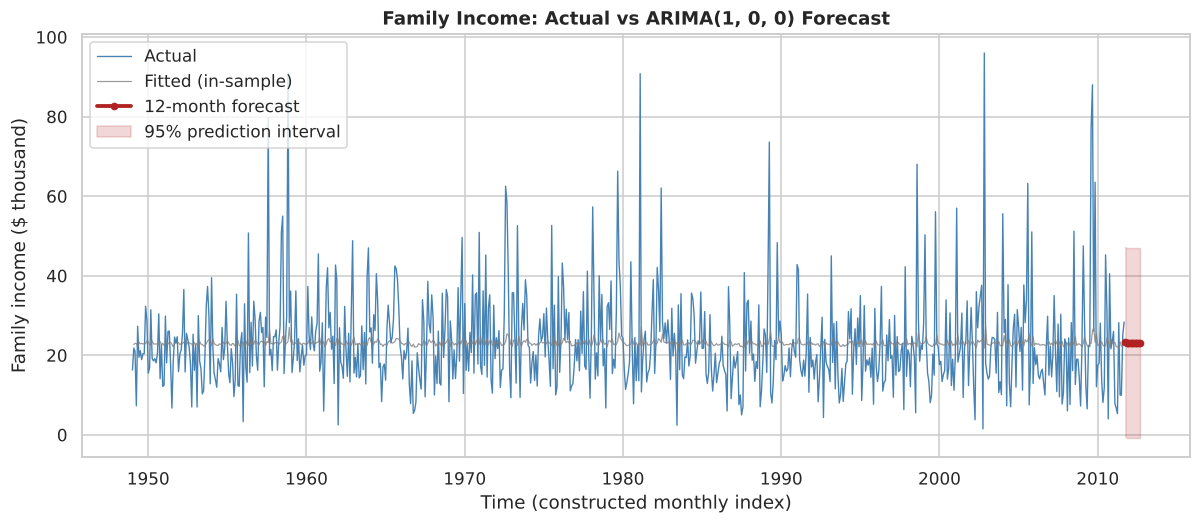

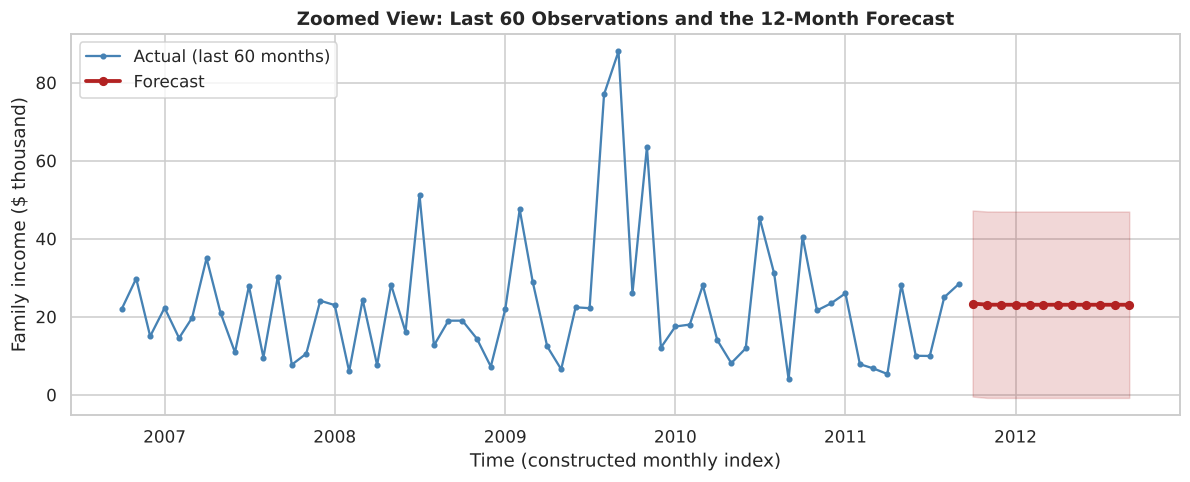

In [109]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(ts, color="steelblue", lw=0.9, label="Actual")
ax.plot(arima_fit.fittedvalues.iloc[1:], color="gray", lw=0.8, alpha=0.8, label="Fitted (in-sample)")
ax.plot(fc.predicted_mean, color="firebrick", lw=2.5, marker="o", ms=4, label="12-month forecast")
ax.fill_between(fc.predicted_mean.index, fc.conf_int().iloc[:, 0], fc.conf_int().iloc[:, 1],
                color="firebrick", alpha=0.18, label="95% prediction interval")
ax.set_title(f"Family Income: Actual vs ARIMA{best_order} Forecast")
ax.set_xlabel("Time (constructed monthly index)")
ax.set_ylabel("Family income ($ thousand)")
ax.legend(loc="upper left")
plt.show()

fig, ax = plt.subplots(figsize=(13, 4.5))
recent = ts.iloc[-60:]
ax.plot(recent, color="steelblue", marker="o", ms=3, label="Actual (last 60 months)")
ax.plot(fc.predicted_mean, color="firebrick", lw=2.5, marker="o", ms=5, label="Forecast")
ax.fill_between(fc.predicted_mean.index, fc.conf_int().iloc[:, 0], fc.conf_int().iloc[:, 1], color="firebrick", alpha=0.18)
ax.set_title("Zoomed View: Last 60 Observations and the 12-Month Forecast")
ax.set_xlabel("Time (constructed monthly index)")
ax.set_ylabel("Family income ($ thousand)")
ax.legend(loc="upper left")
plt.show()

**Interpretation.** The forecast starts at \$23.39k and reverts to the mean of \$23.08k within two steps, staying flat for the rest of the 12 months. The 95% prediction interval is very wide (about −\$0.8k to \$47k) and its lower bound is even negative, which is impossible for income: the model assumes normal errors while family income is right-skewed. Compared with AirPassengers, where trend and seasonality make forecasting meaningful, this exercise shows that ARIMA can only forecast structure that exists; for cross-sectional data the best forecast is simply the average.

---
# Assessment 7 – 1-D, 2-D and N-D Analysis
**Theory.** Exploratory analysis moves from **one dimension** (the distribution of a single variable), to **two dimensions** (how a pair of variables relate), to **N dimensions** (how several variables relate simultaneously). Each level combines numerical summaries with matching plots.

### 1. Load the dataset

In [110]:
df7 = add_labels(pd.read_csv(URL).drop(columns="rownames"))
workers7 = df7[df7["inlf"] == 1].copy()
print("Shape:", df7.shape)

Shape: (753, 27)


### 2. Summary statistics (1-D)
Computed for every continuous numerical variable. **Skewness** measures asymmetry (0 = symmetric, > 0 = long right tail). **Kurtosis** here is *excess* kurtosis (0 for a normal distribution; > 0 = heavier tails). Both are computed with the **type 3** formulas that `e1071::skewness()` and `e1071::kurtosis()` use by default, so the values match R:
$$g_1 = \frac{m_3}{m_2^{3/2}}, \quad b_1 = g_1\left(\frac{n-1}{n}\right)^{3/2}, \qquad g_2 = \frac{m_4}{m_2^{2}} - 3, \quad b_2 = (g_2 + 3)\left(\frac{n-1}{n}\right)^{2} - 3$$
where $m_k$ is the $k$-th central moment. `wage` and `lwage` use their 428 observed values.

In [111]:
def e1071_skewness(x):
    x = np.asarray(x.dropna(), dtype=float)
    n = len(x)
    m2, m3 = np.mean((x - x.mean()) ** 2), np.mean((x - x.mean()) ** 3)
    return (m3 / m2 ** 1.5) * ((n - 1) / n) ** 1.5


def e1071_kurtosis(x):
    x = np.asarray(x.dropna(), dtype=float)
    n = len(x)
    m2, m4 = np.mean((x - x.mean()) ** 2), np.mean((x - x.mean()) ** 4)
    return (m4 / m2 ** 2) * ((n - 1) / n) ** 2 - 3


stat_vars = ["hours", "age", "educ", "wage", "lwage", "hushrs", "husage", "huseduc", "huswage",
             "faminc", "mtr", "motheduc", "fatheduc", "unem", "exper", "nwifeinc"]

### 3. Store the statistics in a single structured data frame

In [112]:
summary_stats = pd.DataFrame({
    "N": df7[stat_vars].count(),
    "Mean": df7[stat_vars].mean(),
    "Median": df7[stat_vars].median(),
    "Minimum": df7[stat_vars].min(),
    "Maximum": df7[stat_vars].max(),
    "Range": df7[stat_vars].max() - df7[stat_vars].min(),
    "Variance": df7[stat_vars].var(),
    "Std_Dev": df7[stat_vars].std(),
    "IQR": df7[stat_vars].quantile(0.75) - df7[stat_vars].quantile(0.25),
    "Skewness": [e1071_skewness(df7[v]) for v in stat_vars],
    "Kurtosis": [e1071_kurtosis(df7[v]) for v in stat_vars]
})
summary_stats.round(3)

,N,Mean,Median,Minimum,Maximum,Range,Variance,Std_Dev,IQR,Skewness,Kurtosis
hours,753,740.5760,288.0000,0.0000,"4,950.00","4,950.00","759,188.46",871.3140,"1,516.00",0.9210,0.1850
age,753,42.5380,43.0000,30.0000,60.0000,30.0000,65.1660,8.0730,13.0000,0.1510,-1.0240
educ,753,12.2870,12.0000,5.0000,17.0000,12.0000,5.2000,2.2800,1.0000,0.0210,0.7340
wage,428,4.1780,3.4820,0.1280,25.0000,24.8720,10.9580,3.3100,2.7080,3.0690,13.7430
lwage,428,1.1900,1.2480,-2.0540,3.2190,5.2730,0.5230,0.7230,0.7870,-0.6830,2.5280
hushrs,753,"2,267.27","2,164.00",175.0000,"5,010.00","4,835.00","354,699.63",595.5670,625.0000,0.5650,1.8380
husage,753,45.1210,46.0000,30.0000,60.0000,30.0000,64.9440,8.0590,14.0000,-0.0640,-1.0090
huseduc,753,12.4910,12.0000,3.0000,17.0000,14.0000,9.1250,3.0210,4.0000,-0.2760,-0.3430
huswage,753,7.4820,6.9760,0.4120,40.5090,40.0970,17.8980,4.2310,4.3780,2.2630,11.4660
faminc,753,"23,080.60","20,880.00","1,500.00","96,000.00","94,500.00","148,601,025.44","12,190.20","12,772.00",1.8980,6.4580


**Interpretation.**
* **Strongly right-skewed and heavy-tailed:** `wage` (skew 3.07, kurtosis 13.7), `huswage` (2.26, 11.5), `nwifeinc` (2.21, 8.35) and `faminc` (1.90, 6.46). Mean > median for all of them – typical of income data.
* **Log transformation works:** `lwage` is much closer to symmetric (skew −0.68), which is why economists model log wages; it slightly over-corrects, leaving a short left tail of very low wages.
* **Platykurtic (flat):** `age` and `husage` have kurtosis ≈ −1.0, i.e. ages are spread almost uniformly from 30 to 60.
* **Peaked:** `educ` is symmetric (skew 0.02) but has positive kurtosis (0.73) because half of the observations sit at exactly 12 years.
* `hours` is right-skewed (0.92) because 325 women have 0 hours.

### 4. Frequency and relative frequency tables for a categorical variable, with pie chart and bar plot
**Variable:** `Edu_Level`.

,Frequency,Relative Frequency,Percent
Edu_Level,,,
Below HS,160,0.2125,21.2500
High School,381,0.5060,50.6000
Some College,109,0.1448,14.4800
College+,103,0.1368,13.6800


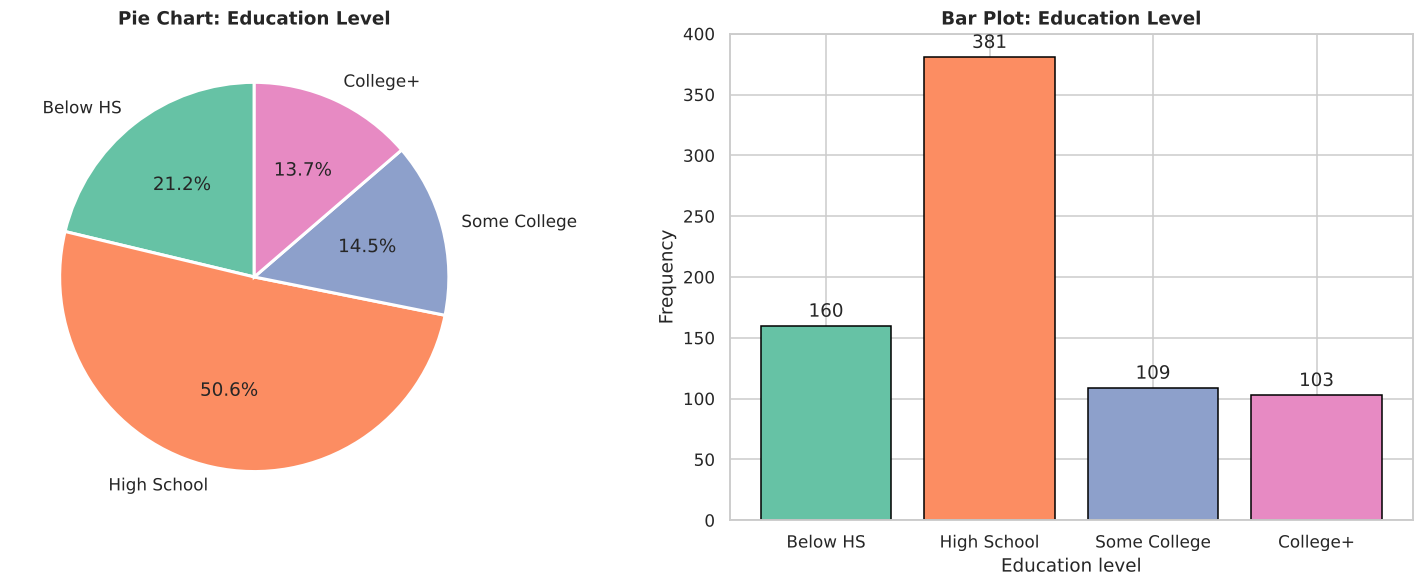

In [113]:
f7 = df7["Edu_Level"].value_counts().sort_index()
freq7 = pd.DataFrame({"Frequency": f7, "Relative Frequency": (f7 / f7.sum()).round(4),
                      "Percent": (100 * f7 / f7.sum()).round(2)})
display(freq7)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
pal = sns.color_palette("Set2", 4)
axes[0].pie(f7.values, labels=f7.index, autopct="%1.1f%%", colors=pal, startangle=90,
            wedgeprops={"edgecolor": "white", "linewidth": 2})
axes[0].set_title("Pie Chart: Education Level")
bars = axes[1].bar(f7.index.astype(str), f7.values, color=pal, edgecolor="black")
axes[1].bar_label(bars, padding=3)
axes[1].set_title("Bar Plot: Education Level")
axes[1].set_xlabel("Education level")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

### 5. Binned frequency table for a numerical variable, histogram and box plot
**Variable:** `faminc`, grouped into \$10,000-wide class intervals.

,Family income interval ($),Frequency,Relative Freq,Cumulative Freq
0,"[0, 10000)",57,0.0757,57
1,"[10000, 20000)",298,0.3958,355
2,"[20000, 30000)",236,0.3134,591
3,"[30000, 40000)",106,0.1408,697
4,"[40000, 50000)",29,0.0385,726
5,"[50000, 60000)",14,0.0186,740
6,"[60000, 70000)",6,0.0080,746
7,"[70000, 80000)",3,0.0040,749
8,"[80000, 90000)",1,0.0013,750
9,"[90000, 100000)",3,0.0040,753


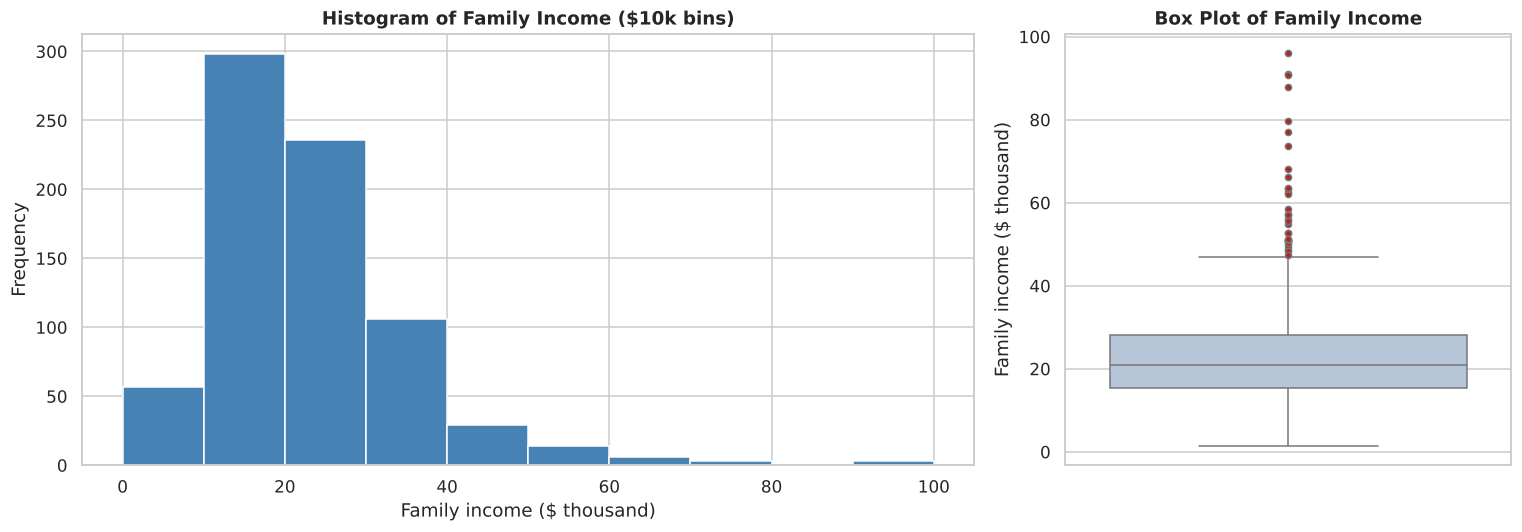

Outliers above the upper whisker (Q3 + 1.5 IQR): 31


In [114]:
bins7 = np.arange(0, 100001, 10000)
binned = pd.cut(df7["faminc"], bins=bins7, right=False)
bin_table = binned.value_counts().sort_index().rename_axis("Family income interval ($)").reset_index(name="Frequency")
bin_table["Relative Freq"] = (bin_table["Frequency"] / bin_table["Frequency"].sum()).round(4)
bin_table["Cumulative Freq"] = bin_table["Frequency"].cumsum()
display(bin_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].hist(df7["faminc"] / 1000, bins=bins7 / 1000, color="steelblue", edgecolor="white")
axes[0].set_title("Histogram of Family Income ($10k bins)")
axes[0].set_xlabel("Family income ($ thousand)")
axes[0].set_ylabel("Frequency")
sns.boxplot(y=df7["faminc"] / 1000, color="lightsteelblue", ax=axes[1],
            flierprops={"markerfacecolor": "firebrick", "markersize": 4})
axes[1].set_title("Box Plot of Family Income")
axes[1].set_ylabel("Family income ($ thousand)")
plt.tight_layout()
plt.show()
q1, q3 = df7["faminc"].quantile([0.25, 0.75])
print("Outliers above the upper whisker (Q3 + 1.5 IQR):", (df7["faminc"] > q3 + 1.5 * (q3 - q1)).sum())

### 6. Contingency table with row and column percentages (2-D, categorical × categorical)
**Variables:** `Edu_Level` × `LF_Status`. `normalize="index"` and `normalize="columns"` are the Python equivalents of `prop.table(table, 1)` and `prop.table(table, 2)`. A chi-square test of independence is added to check whether the association is statistically significant.

In [115]:
ct7 = pd.crosstab(df7["Edu_Level"], df7["LF_Status"])
print("Contingency table:")
display(pd.crosstab(df7["Edu_Level"], df7["LF_Status"], margins=True, margins_name="Total"))
print("Row percentages (each education level sums to 100%):")
display((pd.crosstab(df7["Edu_Level"], df7["LF_Status"], normalize="index") * 100).round(2))
print("Column percentages (each status sums to 100%):")
display((pd.crosstab(df7["Edu_Level"], df7["LF_Status"], normalize="columns") * 100).round(2))
chi2, p_chi, dof, _ = stats.chi2_contingency(ct7)
print(f"Chi-square test of independence: chi2 = {chi2:.3f}, df = {dof}, p-value = {p_chi:.5f}")

Contingency table:


LF_Status,Non-participant,Participant,Total
Edu_Level,,,
Below HS,88,72,160
High School,169,212,381
Some College,43,66,109
College+,25,78,103
Total,325,428,753


Row percentages (each education level sums to 100%):


LF_Status,Non-participant,Participant
Edu_Level,,
Below HS,55.0000,45.0000
High School,44.3600,55.6400
Some College,39.4500,60.5500
College+,24.2700,75.7300


Column percentages (each status sums to 100%):


LF_Status,Non-participant,Participant
Edu_Level,,
Below HS,27.0800,16.8200
High School,52.0000,49.5300
Some College,13.2300,15.4200
College+,7.6900,18.2200


Chi-square test of independence: chi2 = 24.956, df = 3, p-value = 0.00002


**Interpretation.** Participation rises steadily with education: 45.0% (Below HS), 55.6% (High School), 60.6% (Some College) and 75.7% (College+). The column percentages show the same thing from the other side: college graduates are 18.2% of participants but only 7.7% of non-participants. The chi-square test ($\chi^2$ = 24.96, df = 3, p ≈ 0.00002) rejects independence, so education and labour-force participation are significantly associated.

### 7. Stacked and grouped bar plots

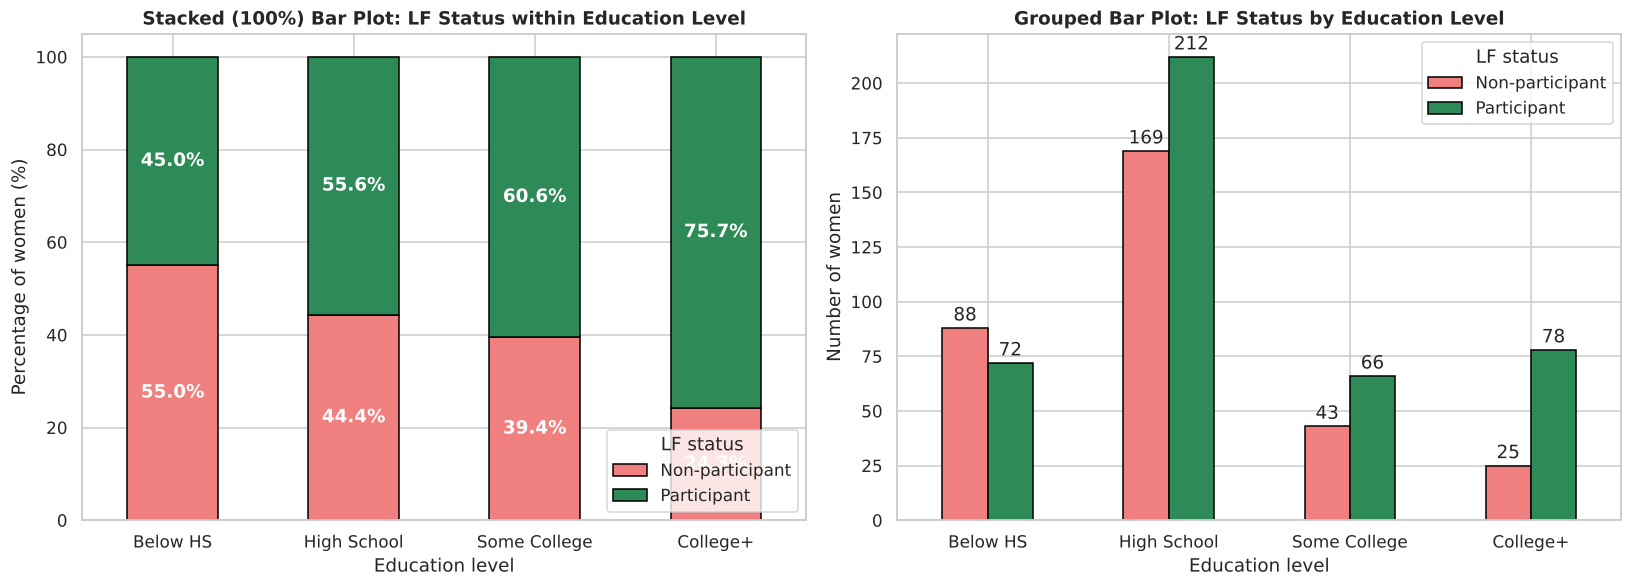

In [116]:
pct7 = pd.crosstab(df7["Edu_Level"], df7["LF_Status"], normalize="index") * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
pct7.plot(kind="bar", stacked=True, color=["lightcoral", "seagreen"], edgecolor="black", rot=0, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontweight="bold")
axes[0].set_title("Stacked (100%) Bar Plot: LF Status within Education Level")
axes[0].set_xlabel("Education level")
axes[0].set_ylabel("Percentage of women (%)")
axes[0].legend(title="LF status", loc="lower right")
ct7.plot(kind="bar", color=["lightcoral", "seagreen"], edgecolor="black", rot=0, ax=axes[1])
for container in axes[1].containers:
    axes[1].bar_label(container, padding=2)
axes[1].set_title("Grouped Bar Plot: LF Status by Education Level")
axes[1].set_xlabel("Education level")
axes[1].set_ylabel("Number of women")
axes[1].legend(title="LF status")
plt.tight_layout()
plt.show()

### 8. Grouped statistics with `aggregate()` (2-D, categorical × numerical)
**Variables:** `Edu_Level` and `faminc`. `groupby().agg()` is the pandas equivalent of `aggregate(faminc ~ Edu_Level, FUN = ...)`.

In [117]:
agg7 = df7.groupby("Edu_Level", observed=True)["faminc"].agg(Mean="mean", Median="median", SD="std", N="count")
agg7.round(2)

,Mean,Median,SD,N
Edu_Level,,,,
Below HS,"17,777.68","15,827.50","9,283.93",160
High School,"21,539.46","19,840.00","10,240.60",381
Some College,"27,812.94","25,872.00","11,763.59",109
College+,"32,010.82","29,000.00","16,326.41",103


### 9. Side-by-side box plots and violin plot

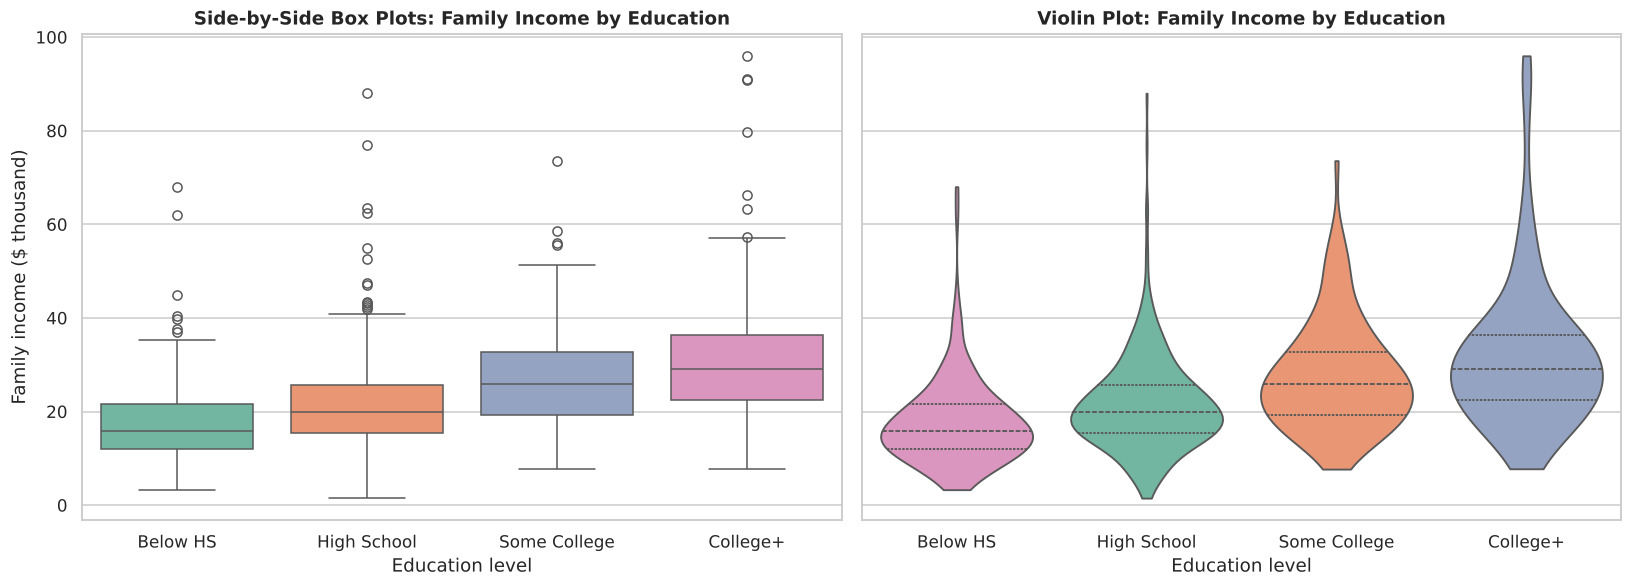

In [118]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
sns.boxplot(data=df7, x="Edu_Level", y=df7["faminc"] / 1000, hue="Edu_Level", palette="Set2", legend=False, dodge=False, ax=axes[0])
axes[0].set_title("Side-by-Side Box Plots: Family Income by Education")
sns.violinplot(data=df7, x="Edu_Level", y=df7["faminc"] / 1000, hue="Edu_Level", palette="Set2", inner="quartile",
               cut=0, legend=False, dodge=False, ax=axes[1])
axes[1].set_title("Violin Plot: Family Income by Education")
for ax in axes:
    ax.set_xlabel("Education level")
    ax.set_ylabel("Family income ($ thousand)")
plt.tight_layout()
plt.show()

**Interpretation.** Mean family income rises from \$17,778 (Below HS) to \$21,539, \$27,813 and \$32,011 (College+), and medians follow the same order. The standard deviation also increases (from \$9,284 to \$16,326), so better-educated households are both richer and more varied in income. In every group the mean exceeds the median, and the box plots show high-income outliers in all groups. Part of this pattern reflects *assortative mating*: educated women tend to marry educated, higher-earning husbands (`educ`–`huseduc` r = 0.61).

### 10. Pearson and Spearman correlation with a scatter plot and fitted regression line (2-D, numerical × numerical)
**Variables:** `huswage` and `faminc`.
* **Pearson's $r$** measures the strength of a *linear* relationship and is sensitive to outliers.
* **Spearman's $\rho$** is Pearson's $r$ computed on ranks, so it measures any *monotonic* relationship and is robust to outliers.

Pearson  r   = 0.7250 (p = 9.45e-124)
Spearman rho = 0.6909 (p = 6.25e-108)
Fitted line : faminc ($k) = 7.449 + 2.089 x huswage   (R^2 = 0.5257)


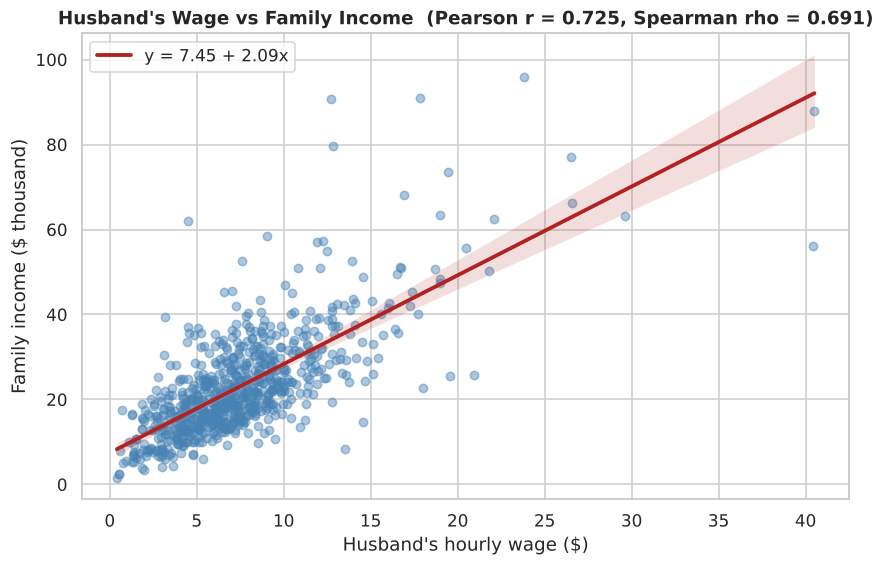

In [119]:
pear = stats.pearsonr(df7["huswage"], df7["faminc"])
spear = stats.spearmanr(df7["huswage"], df7["faminc"])
slope, intercept, r_lin, p_lin, se_lin = stats.linregress(df7["huswage"], df7["faminc"] / 1000)
print(f"Pearson  r   = {pear[0]:.4f} (p = {pear[1]:.2e})")
print(f"Spearman rho = {spear[0]:.4f} (p = {spear[1]:.2e})")
print(f"Fitted line : faminc ($k) = {intercept:.3f} + {slope:.3f} x huswage   (R^2 = {r_lin ** 2:.4f})")

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.regplot(data=df7, x="huswage", y=df7["faminc"] / 1000, scatter_kws={"alpha": 0.45, "s": 30, "color": "steelblue"},
            line_kws={"color": "firebrick", "lw": 2.5, "label": f"y = {intercept:.2f} + {slope:.2f}x"}, ax=ax)
ax.set_title(f"Husband's Wage vs Family Income  (Pearson r = {pear[0]:.3f}, Spearman rho = {spear[0]:.3f})")
ax.set_xlabel("Husband's hourly wage ($)")
ax.set_ylabel("Family income ($ thousand)")
ax.legend()
plt.show()

**Interpretation.** Both coefficients show a **strong positive** relationship (Pearson r = 0.725, Spearman ρ = 0.691, both p < 0.001). The fitted line says each extra \$1 of husband's hourly wage is associated with about \$2,089 more family income, and husband's wage alone explains 52.6% of the variation in family income. Pearson is slightly larger than Spearman because a few very high-wage, high-income families strengthen the linear fit.

### 11. Two categorical + one numerical variable (N-D)
**Variables:** `Residence`, `LF_Status` and `faminc`. Mean and standard deviation are computed for all four combinations, then shown as a faceted box plot and a grouped bar chart with ±1 SD error bars.

,Residence,LF_Status,Mean,SD,N
0,Rural,Non-participant,"17,743.58","10,203.12",115
1,Rural,Participant,"20,069.63","10,652.47",154
2,Urban,Non-participant,"23,863.60","13,455.38",210
3,Urban,Participant,"26,412.77","11,616.07",274


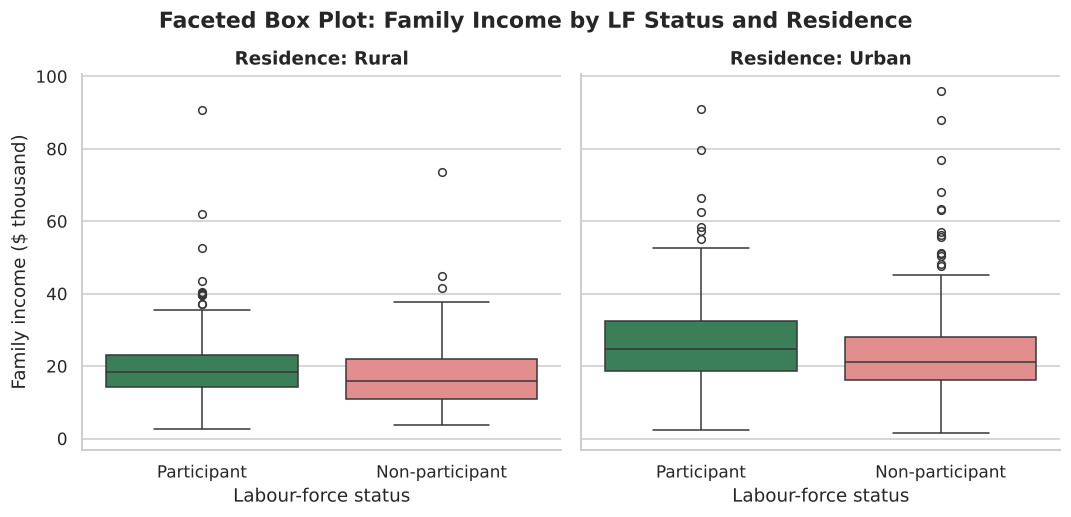

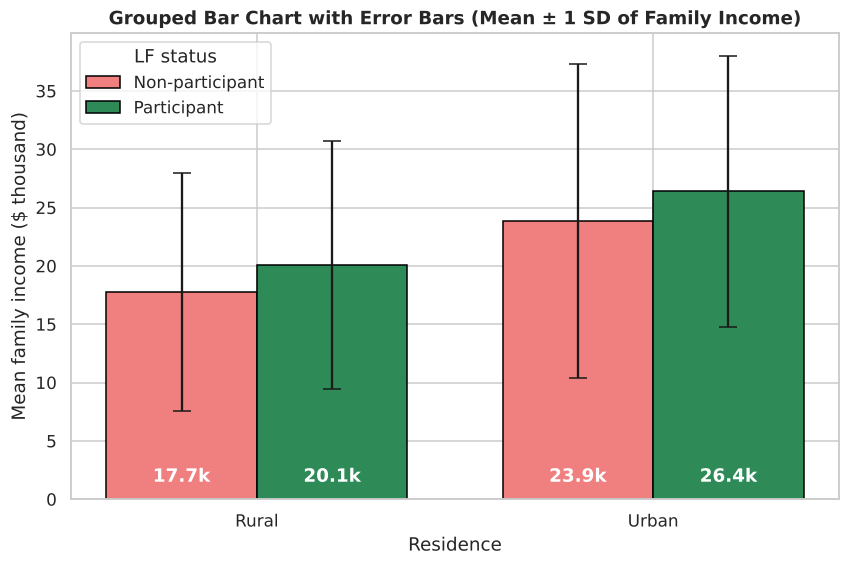

In [120]:
combo = df7.groupby(["Residence", "LF_Status"])["faminc"].agg(Mean="mean", SD="std", N="count").reset_index()
display(combo.round(2))

g = sns.catplot(data=df7, x="LF_Status", y=df7["faminc"] / 1000, col="Residence", kind="box", hue="LF_Status",
                palette={"Participant": "seagreen", "Non-participant": "lightcoral"}, height=4.5, aspect=1.1, legend=False)
g.set_titles("Residence: {col_name}")
g.set_axis_labels("Labour-force status", "Family income ($ thousand)")
g.fig.suptitle("Faceted Box Plot: Family Income by LF Status and Residence", y=1.04, fontweight="bold")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5.5))
width = 0.38
x = np.arange(2)
for i, (status, color) in enumerate([("Non-participant", "lightcoral"), ("Participant", "seagreen")]):
    sub = combo[combo["LF_Status"] == status].set_index("Residence").loc[["Rural", "Urban"]]
    bars = ax.bar(x + (i - 0.5) * width, sub["Mean"] / 1000, width, yerr=sub["SD"] / 1000, capsize=6,
                  color=color, edgecolor="black", label=status)
    for bar, mean_val in zip(bars, sub["Mean"] / 1000):
        ax.text(bar.get_x() + bar.get_width() / 2, 1.5, f"{mean_val:.1f}k", ha="center", color="white", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(["Rural", "Urban"])
ax.set_title("Grouped Bar Chart with Error Bars (Mean ± 1 SD of Family Income)")
ax.set_xlabel("Residence")
ax.set_ylabel("Mean family income ($ thousand)")
ax.legend(title="LF status")
plt.show()

**Interpretation.** Urban families earn about \$6k more than rural families in both participation groups (e.g. participants \$26.4k vs \$20.1k). Within each area, families where the wife works earn about \$2.3–2.5k more, roughly her own contribution. The error bars (±1 SD ≈ \$10–13k) are large and overlap heavily, so these group differences are modest compared with the variation within each group.

### 12. One categorical + two numerical variables (N-D)
**Variables:** categorical `Edu_Level` with numerical `exper` (years of experience) and `lwage` (log hourly wage), for working women. Points are coloured *and* shaped by education level, and a separate correlation matrix of the two numerical variables is computed for each level.

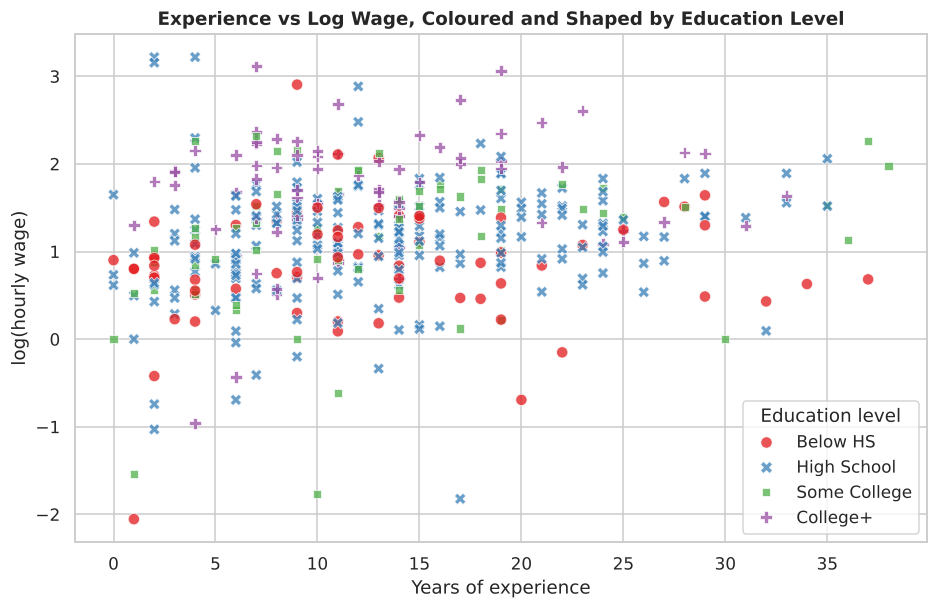

Correlation matrix for Below HS (n = 72):


,exper,lwage
exper,1.0000,0.1130
lwage,0.1130,1.0000


Correlation matrix for High School (n = 212):


,exper,lwage
exper,1.0000,0.1800
lwage,0.1800,1.0000


Correlation matrix for Some College (n = 66):


,exper,lwage
exper,1.0000,0.3070
lwage,0.3070,1.0000


Correlation matrix for College+ (n = 78):


,exper,lwage
exper,1.0000,0.1510
lwage,0.1510,1.0000


In [121]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=workers7, x="exper", y="lwage", hue="Edu_Level", style="Edu_Level", palette="Set1",
                s=55, alpha=0.75, ax=ax)
ax.set_title("Experience vs Log Wage, Coloured and Shaped by Education Level")
ax.set_xlabel("Years of experience")
ax.set_ylabel("log(hourly wage)")
ax.legend(title="Education level")
plt.show()

for level, grp in workers7.groupby("Edu_Level", observed=True):
    print(f"Correlation matrix for {level} (n = {len(grp)}):")
    display(grp[["exper", "lwage"]].corr().round(3))

**Interpretation.** Experience and log wage are positively correlated at every education level, i.e. wages rise with experience regardless of schooling. The relationship is weak (r = 0.11 for Below HS, 0.18 for High School, 0.15 for College+) and strongest for Some College (r = 0.31). In the scatter plot, College+ women (purple) sit higher at almost every level of experience, showing that education shifts the whole wage level up.

### 13. Full correlation matrix and heatmap (at least three numerical variables)

,hours,age,educ,exper,kidslt6,kidsge6,huseduc,huswage,faminc,nwifeinc,mtr,unem
hours,1.0000,-0.0330,0.1060,0.4050,-0.2220,-0.0910,-0.0100,-0.0990,0.1460,-0.1250,-0.1920,-0.0600
age,-0.0330,1.0000,-0.1200,0.3340,-0.4340,-0.3850,-0.1630,0.0270,0.0520,0.0590,-0.0590,0.0770
educ,0.1060,-0.1200,1.0000,0.0660,0.1090,-0.0590,0.6120,0.2850,0.3610,0.2780,-0.4050,0.0720
exper,0.4050,0.3340,0.0660,1.0000,-0.1940,-0.3000,-0.0360,-0.1030,-0.0280,-0.1720,-0.0330,0.0040
kidslt6,-0.2220,-0.4340,0.1090,-0.1940,1.0000,0.0840,0.1340,0.0320,-0.0280,0.0380,0.0600,-0.0090
kidsge6,-0.0910,-0.3850,-0.0590,-0.3000,0.0840,1.0000,0.0090,-0.0300,-0.0200,0.0250,0.1460,0.0140
huseduc,-0.0100,-0.1630,0.6120,-0.0360,0.1340,0.0090,1.0000,0.3950,0.3770,0.3620,-0.4370,0.0550
huswage,-0.0990,0.0270,0.2850,-0.1030,0.0320,-0.0300,0.3950,1.0000,0.7250,0.7580,-0.7210,0.1580
faminc,0.1460,0.0520,0.3610,-0.0280,-0.0280,-0.0200,0.3770,0.7250,1.0000,0.9410,-0.8840,0.0620
nwifeinc,-0.1250,0.0590,0.2780,-0.1720,0.0380,0.0250,0.3620,0.7580,0.9410,1.0000,-0.8100,0.0750


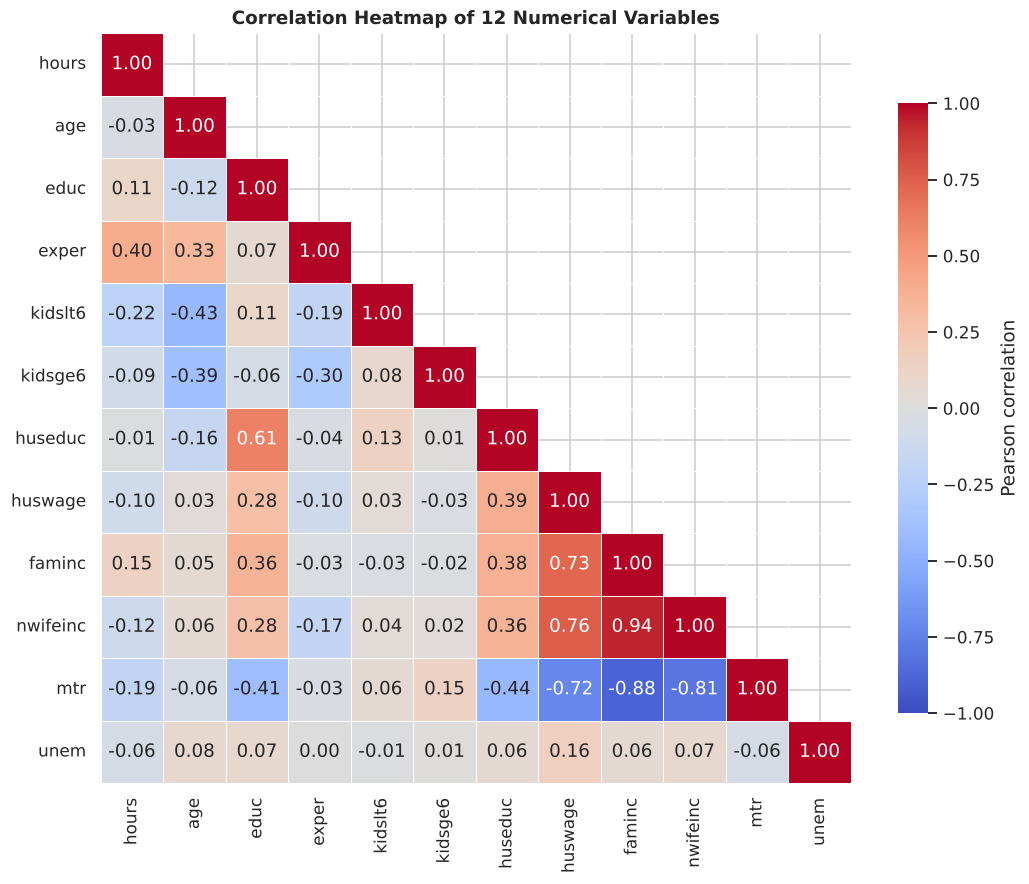

Strongest relationships (|r|):
faminc    nwifeinc    0.9410
          mtr        -0.8840
nwifeinc  mtr        -0.8100
huswage   nwifeinc    0.7580
          faminc      0.7250
          mtr        -0.7210


In [122]:
n_vars = ["hours", "age", "educ", "exper", "kidslt6", "kidsge6", "huseduc", "huswage", "faminc", "nwifeinc", "mtr", "unem"]
corr13 = df7[n_vars].corr()
display(corr13.round(3))
mask = np.triu(np.ones_like(corr13, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr13, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
ax.set_title("Correlation Heatmap of 12 Numerical Variables")
plt.show()

pairs = corr13.where(np.triu(np.ones(corr13.shape, dtype=bool), k=1)).stack()
print("Strongest relationships (|r|):")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(6).round(3).to_string())

**Interpretation.**
* **`faminc`–`nwifeinc` (0.94)** – non-wife income is most of family income.
* **`mtr` is strongly negative with `faminc` (−0.88), `nwifeinc` (−0.81) and `huswage` (−0.72).** Its values (0.44–0.94) and this negative link show that the variable is coded as **one minus** the marginal tax rate (the share of an extra dollar the family keeps): richer families face higher tax rates, so their `mtr` value is lower.
* **`educ`–`huseduc` (0.61)** – spouses have similar schooling (assortative mating).
* **`hours`–`exper` (0.41)** and **`hours`–`kidslt6` (−0.22)** – women with more past experience work more, and young children reduce hours.
* **`age`–`kidslt6` (−0.43)** and **`age`–`kidsge6` (−0.39)** – younger women have younger and more children at home.
* `unem` is almost unrelated to every other variable.

### 14. Pairs plot / scatterplot matrix
Lower triangle: scatter plots with regression lines; diagonal: histograms; upper triangle: kernel-density contours. This shows pairwise relationships and distributions simultaneously.

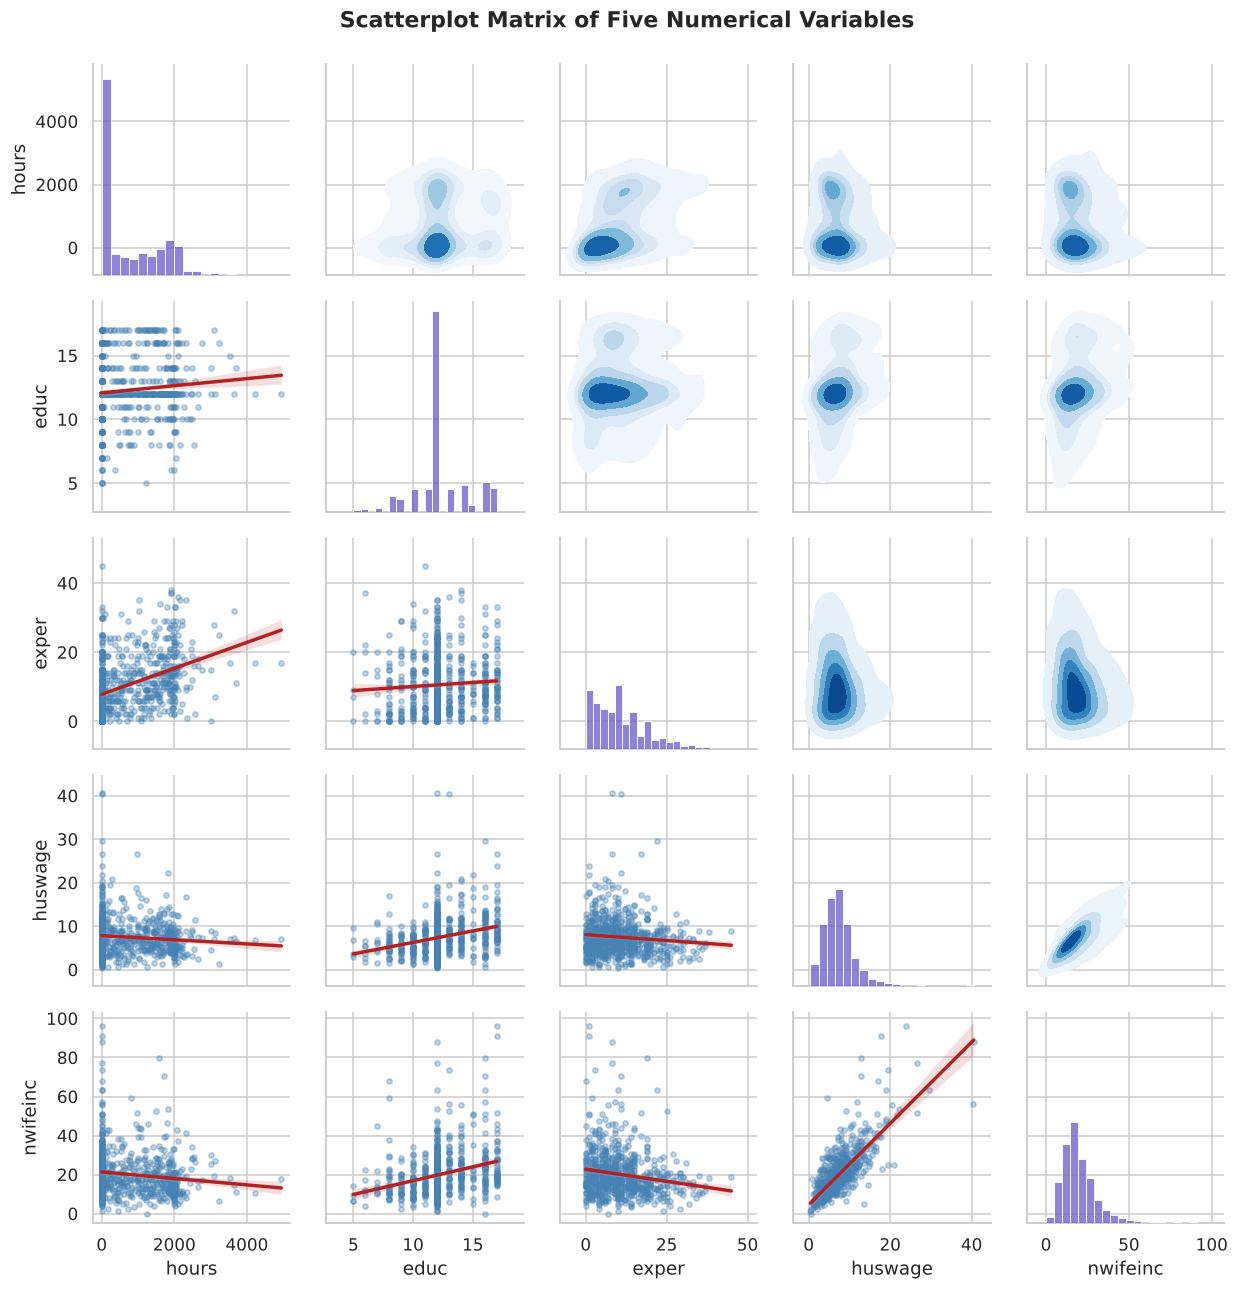

In [123]:
pp_vars = ["hours", "educ", "exper", "huswage", "nwifeinc"]
g = sns.PairGrid(df7[pp_vars], height=2.3)
g.map_lower(sns.regplot, scatter_kws={"alpha": 0.35, "s": 12, "color": "steelblue"}, line_kws={"color": "firebrick"})
g.map_diag(sns.histplot, color="slateblue", bins=20)
g.map_upper(sns.kdeplot, cmap="Blues", fill=True, levels=6)
g.fig.suptitle("Scatterplot Matrix of Five Numerical Variables", y=1.02, fontweight="bold")
plt.show()

---
# Assessment 8 – K-Means and Hierarchical Clustering

## Part A – K-Means Clustering
**Theory.** K-means partitions $n$ observations into $K$ clusters by minimising the **within-cluster sum of squares (WCSS)**
$$WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$
Algorithm: choose $K$ initial centres → assign every point to its nearest centre → recompute each centre as the mean of its points → repeat until assignments stop changing. Because it uses Euclidean distance, variables must be **standardised** first. The **elbow method** plots WCSS against $K$; the “elbow”, where adding clusters stops reducing WCSS substantially, suggests a good $K$.

### 1. Load the dataset

In [124]:
km_df = pd.read_csv(URL)
print("Shape:", km_df.shape)

Shape: (753, 23)


### 2. View the dataset

In [125]:
display(km_df.head(10))
km_df.info()

,rownames,inlf,hours,kidslt6,kidsge6,age,educ,wage,repwage,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,city,exper,nwifeinc,lwage,expersq
0,1,1,1610,1,0,32,12,3.3540,2.6500,2708,34,12,4.0288,16310,0.7215,12,7,5.0000,0,14,10.9101,1.2102,196
1,2,1,1656,0,2,30,12,1.3889,2.6500,2310,30,9,8.4416,21800,0.6615,7,7,11.0000,1,5,19.5000,0.3285,25
2,3,1,1980,1,3,35,12,4.5455,4.0400,3072,40,12,3.5807,21040,0.6915,12,7,5.0000,0,15,12.0399,1.5141,225
3,4,1,456,0,3,34,12,1.0965,3.2500,1920,53,10,3.5417,7300,0.7815,7,7,5.0000,0,6,6.8000,0.0921,36
4,5,1,1568,1,2,31,14,4.5918,3.6000,2000,32,12,10.0000,27300,0.6215,12,14,9.5000,1,7,20.1001,1.5243,49
5,6,1,2032,0,0,54,12,4.7421,4.7000,1040,57,11,6.7106,19495,0.6915,14,7,7.5000,1,33,9.8591,1.5565,1089
6,7,1,1440,0,2,37,16,8.3333,5.9500,2670,37,12,3.4277,21152,0.6915,14,7,5.0000,0,11,9.1520,2.1203,121
7,8,1,1020,0,0,54,12,7.8431,9.9800,4120,53,8,2.5485,18900,0.6915,3,3,5.0000,0,35,10.9000,2.0596,1225
8,9,1,1458,0,2,48,12,2.1262,0.0000,1995,52,4,4.2206,20405,0.7515,7,7,3.0000,0,24,17.3050,0.7543,576
9,10,1,1600,0,2,39,12,4.6875,4.1500,2100,43,12,5.7143,20425,0.6915,7,7,5.0000,0,21,12.9250,1.5449,441


<class 'pandas.DataFrame'>
RangeIndex: 753 entries, 0 to 752
Data columns (total 23 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  753 non-null    int64  
 1   inlf      753 non-null    int64  
 2   hours     753 non-null    int64  
 3   kidslt6   753 non-null    int64  
 4   kidsge6   753 non-null    int64  
 5   age       753 non-null    int64  
 6   educ      753 non-null    int64  
 7   wage      428 non-null    float64
 8   repwage   753 non-null    float64
 9   hushrs    753 non-null    int64  
 10  husage    753 non-null    int64  
 11  huseduc   753 non-null    int64  
 12  huswage   753 non-null    float64
 13  faminc    753 non-null    int64  
 14  mtr       753 non-null    float64
 15  motheduc  753 non-null    int64  
 16  fatheduc  753 non-null    int64  
 17  unem      753 non-null    float64
 18  city      753 non-null    int64  
 19  exper     753 non-null    int64  
 20  nwifeinc  753 non-null    float64
 21  lwag

### 3. Check missing values

In [126]:
mv = km_df.isna().sum()
print("Total missing:", int(mv.sum()))
print(mv[mv > 0])

Total missing: 650
wage     325
lwage    325
dtype: int64


### 4. Distribution of the dependent variable (`table`)
In the Mroz study the dependent (response) variable is **`inlf`**, labour-force participation.

In [127]:
dep = km_df["inlf"].value_counts().sort_index()
display(pd.DataFrame({"inlf": dep.index, "Label": ["Non-participant", "Participant"], "Count": dep.values,
                      "Percent": (100 * dep.values / dep.sum()).round(2)}))

,inlf,Label,Count,Percent
0,0,Non-participant,325,43.1600
1,1,Participant,428,56.8400


### 5. Select only numerical features
All columns are stored as numbers, but not all are valid clustering features. Removed:
* `rownames` – an identifier, not a measurement.
* `inlf` – the dependent variable; it is kept aside to *evaluate* clusters, not to form them.
* `hours`, `wage`, `lwage`, `repwage` – only non-zero / non-missing for workers, so they encode `inlf` directly (target leakage), and `wage`/`lwage` contain missing values.
* `city` – a 0/1 categorical code, not a numerical measurement.
* `expersq` – an exact function of `exper` (redundant).

In [128]:
drop_cols = ["rownames", "inlf", "hours", "wage", "lwage", "repwage", "city", "expersq"]
features = km_df.drop(columns=drop_cols)
print("Features used for clustering (", features.shape[1], "):", list(features.columns))
print("Missing values in features:", int(features.isna().sum().sum()))

Features used for clustering ( 15 ): ['kidslt6', 'kidsge6', 'age', 'educ', 'hushrs', 'husage', 'huseduc', 'huswage', 'faminc', 'mtr', 'motheduc', 'fatheduc', 'unem', 'exper', 'nwifeinc']
Missing values in features: 0


### 6. Standardise the data (`scale`)
$z = (x - \bar{x})/s$ with the sample standard deviation, exactly as R's `scale()` does.

In [129]:
km_scaled = (features - features.mean()) / features.std(ddof=1)
print("Means after scaling (should be 0):", km_scaled.mean().abs().max().round(10))
print("SDs after scaling (should be 1)  :", km_scaled.std(ddof=1).round(6).unique())
km_scaled.head()

Means after scaling (should be 0): 0.0
SDs after scaling (should be 1)  : [1.]


,kidslt6,kidsge6,age,educ,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,exper,nwifeinc
0,1.4549,-1.0253,-1.3054,-0.1258,0.7400,-1.3800,-0.1627,-0.8163,-0.5554,0.5106,0.8163,-0.5063,-1.1633,0.4175,-0.7924
1,-0.4537,0.4900,-1.5531,-0.1258,0.0717,-1.8763,-1.1558,0.2268,-0.1051,-0.2080,-0.6685,-0.5063,0.7629,-0.6978,-0.0541
2,1.4549,1.2477,-0.9338,-0.1258,1.3512,-0.6354,-0.1627,-0.9222,-0.1674,0.1513,0.8163,-0.5063,-1.1633,0.5415,-0.6952
3,-0.4537,1.2477,-1.0576,-0.1258,-0.5831,0.9777,-0.8247,-0.9314,-1.2945,1.2292,-0.6685,-0.5063,-1.1633,-0.5739,-1.1456
4,1.4549,0.4900,-1.4293,0.7513,-0.4488,-1.6281,-0.1627,0.5952,0.3461,-0.6870,0.8163,1.4532,0.2814,-0.4500,-0.0025


### 7. Apply K-means with 2 centres (`kmeans`)
`n_init=25` runs the algorithm from 25 random starts and keeps the best (R: `nstart = 25`). The seed is fixed for reproducibility.

In [130]:
km2 = KMeans(n_clusters=2, n_init=25, random_state=173).fit(km_scaled)
print("K-means with K = 2 fitted.")

K-means with K = 2 fitted.


### 8. Display K-means results
The output mirrors R's `print(kmeans_obj)`: cluster sizes, within-cluster SS, the ratio between_SS / total_SS, and cluster assignments.

In [131]:
labels2 = km2.labels_ + 1
total_ss = ((km_scaled - km_scaled.mean()) ** 2).sum().sum()
within_ss = [((km_scaled[labels2 == k] - km_scaled[labels2 == k].mean()) ** 2).sum().sum() for k in [1, 2]]
print("Cluster sizes:", {int(k): int(v) for k, v in zip(*np.unique(labels2, return_counts=True))})
print("Within-cluster sum of squares by cluster:", [round(float(w), 2) for w in within_ss])
print(f"Total WCSS (tot.withinss): {km2.inertia_:.2f}")
print(f"between_SS / total_SS = {100 * (total_ss - km2.inertia_) / total_ss:.1f} %")
print("Cluster assignment of the first 20 women:", labels2[:20].tolist())

Cluster sizes: {1: 271, 2: 482}
Within-cluster sum of squares by cluster: [3889.35, 5445.52]
Total WCSS (tot.withinss): 9334.88
between_SS / total_SS = 17.2 %
Cluster assignment of the first 20 women: [2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 1, 1, 1, 2, 1, 2, 2, 2, 2, 2]


### 9. Display cluster centres

In [132]:
centers_std = pd.DataFrame(km2.cluster_centers_, columns=features.columns, index=["Cluster 1", "Cluster 2"])
print("Cluster centres (standardised units):")
display(centers_std.round(3))
print("Cluster centres converted back to original units:")
display((centers_std * features.std(ddof=1) + features.mean()).round(2))

Cluster centres (standardised units):


,kidslt6,kidsge6,age,educ,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,exper,nwifeinc
Cluster 1,0.2440,0.0650,-0.2590,0.7250,0.1530,-0.2560,0.7860,0.7300,0.7870,-0.8420,0.5820,0.6290,0.1200,-0.1860,0.7650
Cluster 2,-0.1370,-0.0370,0.1450,-0.4080,-0.0860,0.1440,-0.4420,-0.4100,-0.4420,0.4740,-0.3270,-0.3540,-0.0670,0.1040,-0.4300


Cluster centres converted back to original units:


,kidslt6,kidsge6,age,educ,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,exper,nwifeinc
Cluster 1,0.3700,1.4400,40.4500,13.9400,"2,358.50",43.0600,14.8700,10.5700,"32,671.78",0.6100,11.2100,11.0600,9.0000,9.1300,29.0400
Cluster 2,0.1700,1.3000,43.7100,11.3600,"2,215.98",46.2800,11.1600,5.7500,"17,688.04",0.7200,8.1500,7.5500,8.4100,11.4700,15.1200


**Interpretation (K = 2).** The two clusters contain 271 and 482 women, and the between-cluster sum of squares is only 17.2% of the total, so the split captures a modest part of the variation. The centres show a clear **socio-economic** split: Cluster 1 has more educated wives (13.9 vs 11.4 years) and husbands (14.9 vs 11.2), much higher husband's wage (\$10.57 vs \$5.75) and family income (\$32.7k vs \$17.7k), and better-educated parents. Cluster 2 is the lower-income, lower-education group.

### 10. WCSS for K = 1 to 10

In [133]:
wcss = []
for k in range(1, 11):
    wcss.append(KMeans(n_clusters=k, n_init=25, random_state=173).fit(km_scaled).inertia_)
wcss_table = pd.DataFrame({"K": range(1, 11), "WCSS": wcss})
wcss_table["Drop from previous"] = -wcss_table["WCSS"].diff()
wcss_table["% Drop"] = 100 * wcss_table["Drop from previous"] / wcss_table["WCSS"].shift()
wcss_table.round(2)

,K,WCSS,Drop from previous,% Drop
0,1,"11,280.00",NaN,NaN
1,2,"9,334.88","1,945.12",17.2400
2,3,"8,183.20","1,151.68",12.3400
3,4,"7,594.17",589.0300,7.2000
4,5,"7,172.37",421.7900,5.5500
5,6,"6,872.36",300.0200,4.1800
6,7,"6,593.32",279.0400,4.0600
7,8,"6,355.11",238.2100,3.6100
8,9,"6,165.28",189.8300,2.9900
9,10,"5,995.91",169.3600,2.7500


### 11. Elbow plot
To make the choice objective, the **knee point** is located with the maximum-distance method: draw a straight line from the first point (K = 1) to the last (K = 10), and choose the K whose point lies farthest from that line.

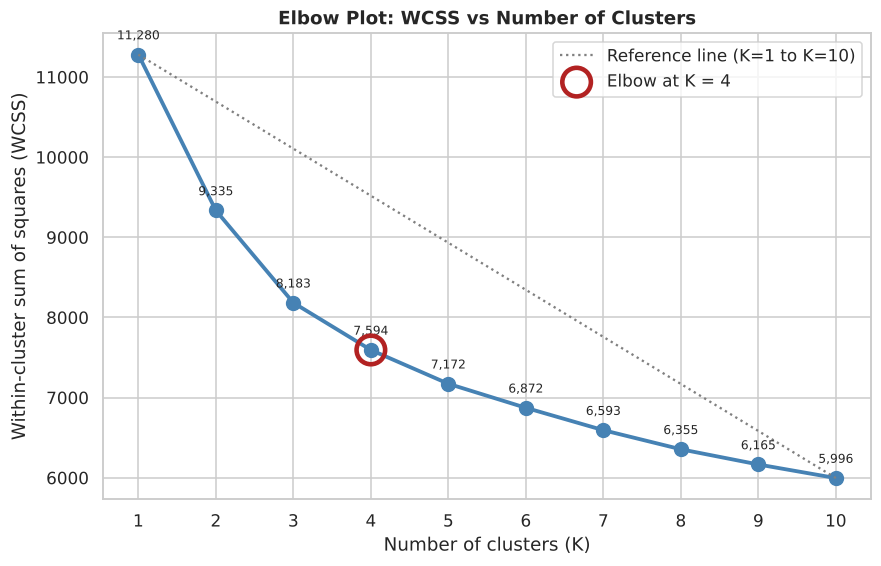

Recommended K from the elbow: 4


In [134]:
pts = np.column_stack([wcss_table["K"], wcss_table["WCSS"]])
norm_pts = (pts - pts.min(axis=0)) / (pts.max(axis=0) - pts.min(axis=0))
start, end = norm_pts[0], norm_pts[-1]
line = (end - start) / np.linalg.norm(end - start)
dist_line = np.abs((norm_pts[:, 0] - start[0]) * line[1] - (norm_pts[:, 1] - start[1]) * line[0])
best_k = int(wcss_table["K"].iloc[np.argmax(dist_line)])

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(wcss_table["K"], wcss_table["WCSS"], "o-", color="steelblue", lw=2.5, ms=9)
ax.plot([1, 10], [wcss[0], wcss[-1]], ls=":", color="gray", label="Reference line (K=1 to K=10)")
ax.scatter(best_k, wcss[best_k - 1], s=350, facecolor="none", edgecolor="firebrick", lw=3,
           label=f"Elbow at K = {best_k}", zorder=5)
for k, w in zip(wcss_table["K"], wcss):
    ax.annotate(f"{w:,.0f}", (k, w), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8)
ax.set_xticks(range(1, 11))
ax.set_title("Elbow Plot: WCSS vs Number of Clusters")
ax.set_xlabel("Number of clusters (K)")
ax.set_ylabel("Within-cluster sum of squares (WCSS)")
ax.legend()
plt.show()
print("Recommended K from the elbow:", best_k)

Because the WCSS curve of real survey data is often smooth, the elbow is cross-checked with the **average silhouette width** (how much closer each point is to its own cluster than to the next one; higher is better).

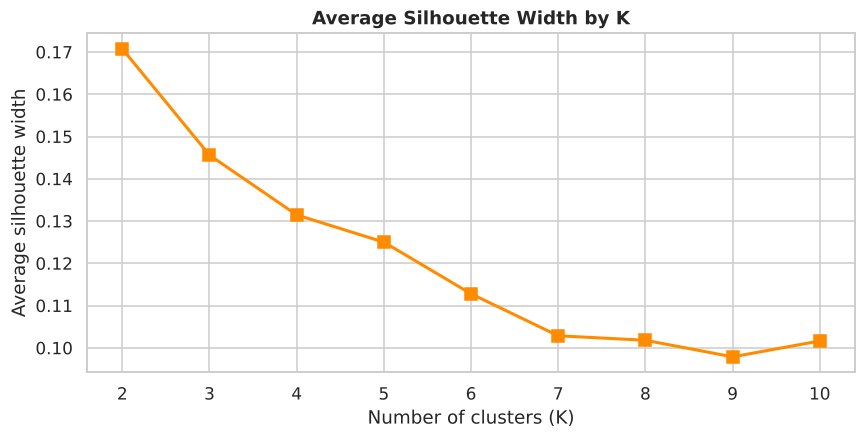

2    0.1707
3    0.1456
4    0.1315
5    0.1250
6    0.1128
7    0.1029
8    0.1018
9    0.0979
10   0.1016


In [135]:
sil = {k: silhouette_score(km_scaled, KMeans(n_clusters=k, n_init=25, random_state=173).fit_predict(km_scaled))
       for k in range(2, 11)}
sil_s = pd.Series(sil, name="Silhouette")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sil_s.index, sil_s.values, "s-", color="darkorange", lw=2, ms=8)
ax.set_xticks(range(2, 11))
ax.set_title("Average Silhouette Width by K")
ax.set_xlabel("Number of clusters (K)")
ax.set_ylabel("Average silhouette width")
plt.show()
print(sil_s.round(4).to_string())

**Interpretation.** WCSS falls by 17.2% from K = 1 to 2, by 12.3% to K = 3 and by 7.2% to K = 4; after that every extra cluster reduces WCSS by only 3–6%. The maximum-distance (knee) method therefore recommends **K = 4**. The silhouette widths are low for every K (best 0.17 at K = 2), which signals that the data do not contain sharply separated groups; the clusters are better seen as useful segments of a continuous population. Following the question, the elbow recommendation K = 4 is applied.

### 12. Apply K-means with the K recommended by the elbow

In [136]:
km_best = KMeans(n_clusters=best_k, n_init=25, random_state=173).fit(km_scaled)
km_df["Cluster"] = km_best.labels_ + 1
print(f"K-means with K = {best_k}")
print("Cluster sizes:", {int(k): int(v) for k, v in km_df["Cluster"].value_counts().sort_index().items()})
print(f"Total WCSS = {km_best.inertia_:.2f}, between_SS / total_SS = {100 * (total_ss - km_best.inertia_) / total_ss:.1f} %")

profile = km_df.groupby("Cluster")[list(features.columns) + ["inlf", "hours"]].mean()
profile["inlf"] = profile["inlf"] * 100
profile = profile.rename(columns={"inlf": "participation_%"})
print("\nCluster profiles (means in original units):")
display(profile.round(2))

K-means with K = 4
Cluster sizes: {1: 185, 2: 221, 3: 267, 4: 80}
Total WCSS = 7594.17, between_SS / total_SS = 32.7 %

Cluster profiles (means in original units):


,kidslt6,kidsge6,age,educ,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,exper,nwifeinc,participation_%,hours
Cluster,,,,,,,,,,,,,,,,,
1,0.3500,2.3400,36.8900,11.0900,"2,278.31",40.0900,10.8400,5.0000,"14,987.56",0.7500,8.1900,7.0200,8.1700,7.5200,12.9100,54.0500,699.6900
2,0.4300,1.6200,37.6000,13.7200,"2,322.02",40.2700,14.6400,8.1100,"24,667.30",0.6600,11.7200,11.3400,8.7100,8.8400,21.1700,61.5400,775.0000
3,0.0100,0.4700,49.8900,11.4900,"2,180.09",52.1600,11.1700,6.3900,"20,188.90",0.7000,7.7800,7.5700,8.6300,14.8000,17.2300,55.4300,776.0700
4,0.1900,1.2700,44.7000,13.7600,"2,381.49",46.6800,14.7800,15.1400,"47,063.49",0.5200,9.8000,10.1000,9.3900,8.8400,43.6500,55.0000,621.5600


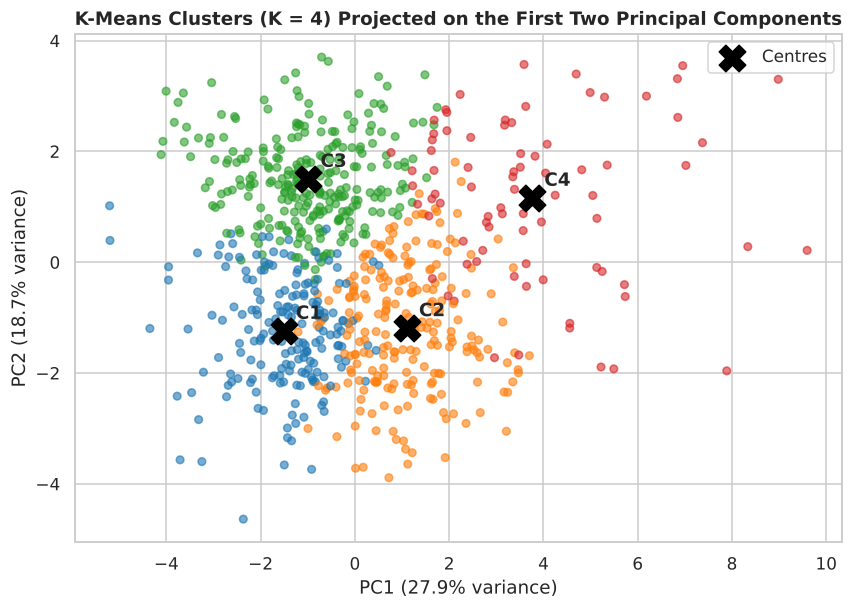

Cross-tabulation of clusters with labour-force participation:


inlf,Non-participant,Participant,All
Cluster,,,
1,85,100,185
2,85,136,221
3,119,148,267
4,36,44,80
All,325,428,753


In [137]:
pca_vis = PCA(n_components=2).fit(km_scaled)
proj = pca_vis.transform(km_scaled)
centers_2d = pca_vis.transform(km_best.cluster_centers_)
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(proj[:, 0], proj[:, 1], c=km_df["Cluster"], cmap="tab10", vmin=1, vmax=10, alpha=0.6, s=25)
ax.scatter(centers_2d[:, 0], centers_2d[:, 1], marker="X", s=300, c="black", label="Centres")
for i, (cx, cy) in enumerate(centers_2d, start=1):
    ax.annotate(f"C{i}", (cx, cy), textcoords="offset points", xytext=(8, 8), fontweight="bold")
ax.set_title(f"K-Means Clusters (K = {best_k}) Projected on the First Two Principal Components")
ax.set_xlabel(f"PC1 ({100 * pca_vis.explained_variance_ratio_[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({100 * pca_vis.explained_variance_ratio_[1]:.1f}% variance)")
ax.legend()
plt.show()
print("Cross-tabulation of clusters with labour-force participation:")
pd.crosstab(km_df["Cluster"], km_df["inlf"].map({1: "Participant", 0: "Non-participant"}), margins=True)

**Interpretation of the four clusters.**
| Cluster | Size | Profile |
|---|---|---|
| **1** | 185 | **Young, lower-income families** – age ≈ 37, most older children (2.3), lowest education (11.1 yrs) and family income (\$15.0k) |
| **2** | 221 | **Young, educated families** – age ≈ 38, educated wives (13.7) and husbands (14.6), family income \$24.7k, the most young children |
| **3** | 267 | **Older women with few children at home** – age ≈ 50, almost no young children, most experience (14.8 yrs) |
| **4** | 80 | **Affluent households** – husband's wage \$15.14, family income \$47.1k, non-wife income \$43.6k |

The participation rate is similar across clusters (54–62%; highest in Cluster 2), and the cross-tabulation shows every cluster contains both participants and non-participants. The household characteristics used for clustering therefore describe *who the families are* (life-cycle stage and economic status), but they do not by themselves separate women who work from women who do not.

## Part B – Hierarchical Clustering
**Theory.** Agglomerative hierarchical clustering starts with every observation as its own cluster and repeatedly merges the two closest clusters until one remains. The merge history is drawn as a **dendrogram**, and cutting it at a chosen height gives any number of clusters. **Ward's method** merges the pair of clusters that causes the smallest increase in total within-cluster variance, producing compact, similarly sized clusters. SciPy's `method="ward"` on Euclidean distances is identical to R's `hclust(method = "ward.D2")`.

### 1. Load the dataset

In [138]:
hc_df = pd.read_csv(URL)
print("Shape:", hc_df.shape)

Shape: (753, 23)


### 2. View the dataset

In [139]:
hc_df.head(10)

,rownames,inlf,hours,kidslt6,kidsge6,age,educ,wage,repwage,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,city,exper,nwifeinc,lwage,expersq
0,1,1,1610,1,0,32,12,3.3540,2.6500,2708,34,12,4.0288,16310,0.7215,12,7,5.0000,0,14,10.9101,1.2102,196
1,2,1,1656,0,2,30,12,1.3889,2.6500,2310,30,9,8.4416,21800,0.6615,7,7,11.0000,1,5,19.5000,0.3285,25
2,3,1,1980,1,3,35,12,4.5455,4.0400,3072,40,12,3.5807,21040,0.6915,12,7,5.0000,0,15,12.0399,1.5141,225
3,4,1,456,0,3,34,12,1.0965,3.2500,1920,53,10,3.5417,7300,0.7815,7,7,5.0000,0,6,6.8000,0.0921,36
4,5,1,1568,1,2,31,14,4.5918,3.6000,2000,32,12,10.0000,27300,0.6215,12,14,9.5000,1,7,20.1001,1.5243,49
5,6,1,2032,0,0,54,12,4.7421,4.7000,1040,57,11,6.7106,19495,0.6915,14,7,7.5000,1,33,9.8591,1.5565,1089
6,7,1,1440,0,2,37,16,8.3333,5.9500,2670,37,12,3.4277,21152,0.6915,14,7,5.0000,0,11,9.1520,2.1203,121
7,8,1,1020,0,0,54,12,7.8431,9.9800,4120,53,8,2.5485,18900,0.6915,3,3,5.0000,0,35,10.9000,2.0596,1225
8,9,1,1458,0,2,48,12,2.1262,0.0000,1995,52,4,4.2206,20405,0.7515,7,7,3.0000,0,24,17.3050,0.7543,576
9,10,1,1600,0,2,39,12,4.6875,4.1500,2100,43,12,5.7143,20425,0.6915,7,7,5.0000,0,21,12.9250,1.5449,441


### 3. Check missing values

In [140]:
print("Missing values per column (non-zero only):")
print(hc_df.isna().sum()[hc_df.isna().sum() > 0])

Missing values per column (non-zero only):
wage     325
lwage    325
dtype: int64


### 4. Select only numerical attributes
The same 15 numerical attributes as in Part A are used (identifiers, the target, leakage variables with missing values, the binary code and the redundant square term are removed).

In [141]:
hc_features = hc_df.drop(columns=drop_cols)
print(hc_features.shape)
print(list(hc_features.columns))

(753, 15)
['kidslt6', 'kidsge6', 'age', 'educ', 'hushrs', 'husage', 'huseduc', 'huswage', 'faminc', 'mtr', 'motheduc', 'fatheduc', 'unem', 'exper', 'nwifeinc']


### 5. Standardise the data (`scale`)

In [142]:
hc_scaled = (hc_features - hc_features.mean()) / hc_features.std(ddof=1)
hc_scaled.describe().loc[["mean", "std"]].round(3)

,kidslt6,kidsge6,age,educ,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,exper,nwifeinc
mean,-0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0000,-0.0000,-0.0000,-0.0000,0.0000
std,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


### 6. Euclidean distance matrix (`dist`)
$d(x_i, x_j) = \sqrt{\sum_{m}(x_{im} - x_{jm})^2}$. With 753 observations there are $753 \times 752 / 2 = 283{,}128$ pairwise distances.

In [143]:
dist_vec = pdist(hc_scaled.values, metric="euclidean")
dist_mat = squareform(dist_vec)
print("Number of pairwise distances:", len(dist_vec))
print(f"Min = {dist_vec.min():.3f}, Mean = {dist_vec.mean():.3f}, Max = {dist_vec.max():.3f}")
print("Distance matrix for the first 6 observations:")
pd.DataFrame(dist_mat[:6, :6], index=range(1, 7), columns=range(1, 7)).round(3)

Number of pairwise distances: 283128
Min = 0.930, Mean = 5.224, Max = 16.153
Distance matrix for the first 6 observations:


,1,2,3,4,5,6
1,0.0000,4.1460,2.5590,4.5830,4.0120,5.8580
2,4.1460,0.0000,4.2520,4.3870,3.5570,6.7820
3,2.5590,4.2520,0.0000,4.0650,4.0590,6.0930
4,4.5830,4.3870,4.0650,0.0000,5.5240,5.7270
5,4.0120,3.5570,4.0590,5.5240,0.0000,6.6810
6,5.8580,6.7820,6.0930,5.7270,6.6810,0.0000


### 7. Hierarchical clustering with Ward's method (`hclust`)

In [144]:
hc = linkage(dist_vec, method="ward")
print("Linkage matrix shape:", hc.shape, "(one row per merge)")
print("Heights of the last 5 merges:", np.round(hc[-5:, 2], 2).tolist())

Linkage matrix shape: (752, 4) (one row per merge)
Heights of the last 5 merges: [22.59, 28.39, 37.11, 48.32, 52.45]


### 8. Dendrogram (`plot`)
The full tree is drawn without leaf labels (753 labels would be unreadable). The dashed line shows the height at which the tree is cut into 3 clusters.

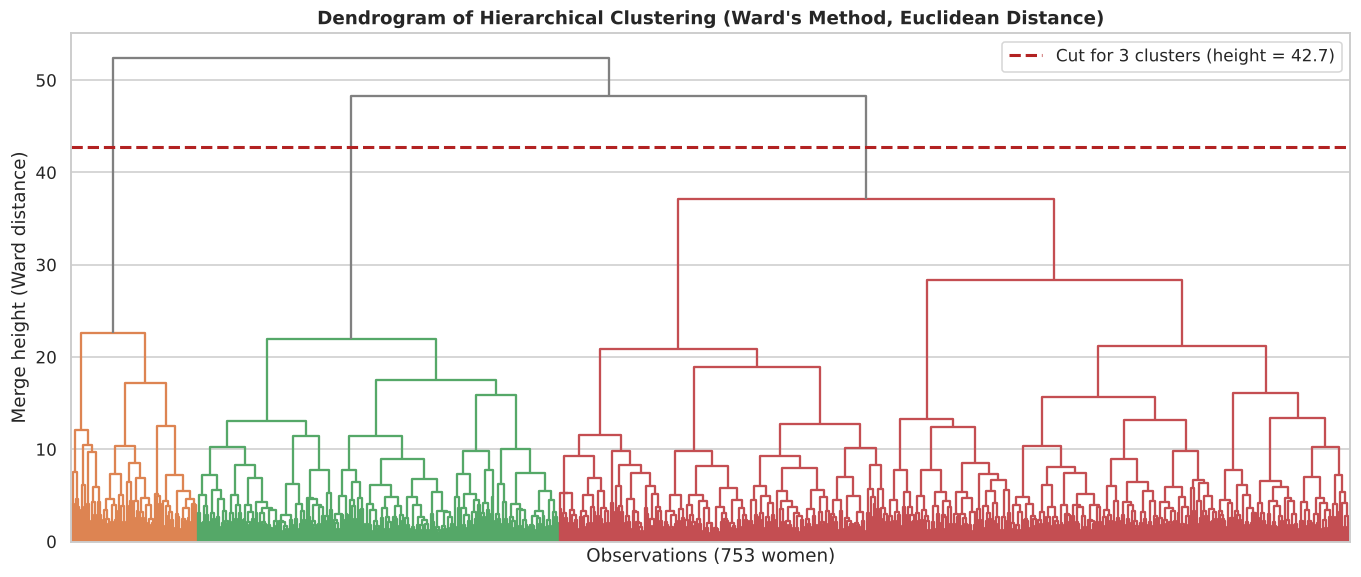

In [145]:
cut_height = (hc[-3, 2] + hc[-2, 2]) / 2
fig, ax = plt.subplots(figsize=(15, 6))
dendrogram(hc, no_labels=True, color_threshold=cut_height, above_threshold_color="gray", ax=ax)
ax.axhline(cut_height, color="firebrick", ls="--", lw=2, label=f"Cut for 3 clusters (height = {cut_height:.1f})")
ax.set_title("Dendrogram of Hierarchical Clustering (Ward's Method, Euclidean Distance)")
ax.set_xlabel("Observations (753 women)")
ax.set_ylabel("Merge height (Ward distance)")
ax.legend()
plt.show()

### 9. Divide the data into 3 clusters and display assignments (`cutree`)

In [146]:
hc_df["HC_Cluster"] = fcluster(hc, t=3, criterion="maxclust")
print("Cluster assignment of the first 20 women:", hc_df["HC_Cluster"].head(20).tolist())
hc_df[["rownames", "age", "educ", "kidslt6", "faminc", "HC_Cluster"]].head(10)

Cluster assignment of the first 20 women: [3, 3, 3, 3, 3, 2, 3, 2, 3, 3, 3, 3, 3, 3, 1, 3, 3, 3, 2, 3]


,rownames,age,educ,kidslt6,faminc,HC_Cluster
0,1,32,12,1,16310,3
1,2,30,12,0,21800,3
2,3,35,12,1,21040,3
3,4,34,12,0,7300,3
4,5,31,14,1,27300,3
5,6,54,12,0,19495,2
6,7,37,16,0,21152,3
7,8,54,12,0,18900,2
8,9,48,12,0,20405,3
9,10,39,12,0,20425,3


### 10. Number of samples in each cluster (`table`)

In [147]:
hc_counts = hc_df["HC_Cluster"].value_counts().sort_index()
display(pd.DataFrame({"Cluster": hc_counts.index, "Samples": hc_counts.values,
                      "Percent": (100 * hc_counts.values / hc_counts.sum()).round(2)}))
print("Cluster profiles (means):")
hc_prof = hc_df.groupby("HC_Cluster")[["age", "educ", "kidslt6", "kidsge6", "exper", "huseduc", "huswage", "faminc", "nwifeinc", "inlf"]].mean()
hc_prof["inlf"] = 100 * hc_prof["inlf"]
hc_prof.rename(columns={"inlf": "participation_%"}).round(2)

,Cluster,Samples,Percent
0,1,74,9.8300
1,2,213,28.2900
2,3,466,61.8900


Cluster profiles (means):


,age,educ,kidslt6,kidsge6,exper,huseduc,huswage,faminc,nwifeinc,participation_%
HC_Cluster,,,,,,,,,,
1,45.0000,13.9900,0.1900,1.2600,8.6600,15.0400,15.1600,"47,208.45",43.8500,55.4100
2,50.0300,11.0200,0.0100,0.5500,14.4300,10.7300,5.9000,"17,834.15",15.4400,51.6400
3,38.7200,12.5900,0.3500,1.7400,9.2100,12.8900,6.9900,"21,647.18",18.5000,59.4400


**Interpretation.** Cutting the Ward dendrogram at height ≈ 42.7 gives three clusters of 74, 213 and 466 women. The large jumps in merge height at the top of the tree (37.1 → 48.3 → 52.4) show that these three groups are relatively well separated. Their profiles match the K-means segments:
* **Cluster 1 (74):** affluent households – husband's wage \$15.16, family income \$47.2k (≈ K-means Cluster 4).
* **Cluster 2 (213):** older women (≈ 50) with few children and long experience (≈ K-means Cluster 3).
* **Cluster 3 (466):** younger families (≈ 39) with more children (≈ K-means Clusters 1 and 2 combined).

Two different algorithms finding the same structure makes the segmentation more trustworthy.

---
# Assessment 9 – Principal Component Analysis
**Theory.** PCA transforms correlated variables into a smaller set of **uncorrelated** variables called principal components (PCs). Each PC is a linear combination of the standardised variables,
$$PC_k = a_{1k}z_1 + a_{2k}z_2 + \dots + a_{pk}z_p,$$
where the weight vectors $a_k$ (**loadings**) are the eigenvectors of the correlation matrix, and the variance of $PC_k$ is the corresponding eigenvalue $\lambda_k$. PCs are ordered so that PC1 captures the most variance, PC2 the most of what remains, and so on. Key outputs: the **proportion of variance** $\lambda_k / \sum\lambda$, the **scree plot** (to decide how many PCs to keep), the **biplot** (scores and loadings together) and the **scores** (coordinates of each observation on the PCs).

### 1. Load the dataset and verify the packages
The R packages map to Python as: `ggplot2` → matplotlib/seaborn, `ggfortify` → custom PCA plots, `FactoMineR` → `sklearn.decomposition.PCA`, `factoextra` → the scree plot and biplot built below, plus `adjustText` (the `ggrepel` equivalent) for non-overlapping labels.

In [148]:
pca_df = pd.read_csv(URL)
import adjustText
packages = {"pandas": pd.__version__, "numpy": np.__version__, "matplotlib": plt.matplotlib.__version__,
            "seaborn": sns.__version__, "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
            "adjustText": getattr(adjustText, "__version__", "installed")}
display(pd.DataFrame({"Package": packages.keys(), "Version": packages.values(), "Status": "Loaded"}))
print("Dataset loaded:", pca_df.shape)

,Package,Version,Status
0,pandas,3.0.5,Loaded
1,numpy,2.5.3,Loaded
2,matplotlib,3.11.2,Loaded
3,seaborn,0.13.2,Loaded
4,scikit-learn,1.9.1,Loaded
5,scipy,1.18.1,Loaded
6,adjustText,1.4.0,Loaded


Dataset loaded: (753, 23)


### 2. Total number of rows and columns

In [149]:
print("Number of rows   :", pca_df.shape[0])
print("Number of columns:", pca_df.shape[1])

Number of rows   : 753
Number of columns: 23


### 3. Extract numeric columns, clean and scale into `data_scaled`
Cleaning steps:
1. Keep numeric columns only.
2. Drop `rownames` (identifier), `inlf` and `city` (binary category codes, not continuous measurements) and `expersq` (an exact function of `exper`).
3. Drop `wage` and `lwage` (43% missing; imputing them would invent wages for non-workers) and `repwage` (mostly zeros for the same reason).
4. Remove any remaining missing values and duplicate rows.
5. Standardise with the equivalent of `scale()`.

Standardisation is essential: PCA maximises variance, so without it `faminc` (variance ≈ 1.5 × 10⁸) would dominate every component.

In [150]:
numeric_pca = pca_df.select_dtypes(include="number")
clean_pca = numeric_pca.drop(columns=["rownames", "inlf", "city", "expersq", "wage", "lwage", "repwage"])
clean_pca = clean_pca.dropna().drop_duplicates()
data_scaled = (clean_pca - clean_pca.mean()) / clean_pca.std(ddof=1)
print("Variables used (", data_scaled.shape[1], "):", list(data_scaled.columns))
print("data_scaled shape:", data_scaled.shape)
data_scaled.head()

Variables used ( 16 ): ['hours', 'kidslt6', 'kidsge6', 'age', 'educ', 'hushrs', 'husage', 'huseduc', 'huswage', 'faminc', 'mtr', 'motheduc', 'fatheduc', 'unem', 'exper', 'nwifeinc']
data_scaled shape: (753, 16)


,hours,kidslt6,kidsge6,age,educ,hushrs,husage,huseduc,huswage,faminc,mtr,motheduc,fatheduc,unem,exper,nwifeinc
0,0.9978,1.4549,-1.0253,-1.3054,-0.1258,0.7400,-1.3800,-0.1627,-0.8163,-0.5554,0.5106,0.8163,-0.5063,-1.1633,0.4175,-0.7924
1,1.0506,-0.4537,0.4900,-1.5531,-0.1258,0.0717,-1.8763,-1.1558,0.2268,-0.1051,-0.2080,-0.6685,-0.5063,0.7629,-0.6978,-0.0541
2,1.4225,1.4549,1.2477,-0.9338,-0.1258,1.3512,-0.6354,-0.1627,-0.9222,-0.1674,0.1513,0.8163,-0.5063,-1.1633,0.5415,-0.6952
3,-0.3266,-0.4537,1.2477,-1.0576,-0.1258,-0.5831,0.9777,-0.8247,-0.9314,-1.2945,1.2292,-0.6685,-0.5063,-1.1633,-0.5739,-1.1456
4,0.9496,1.4549,0.4900,-1.4293,0.7513,-0.4488,-1.6281,-0.1627,0.5952,0.3461,-0.6870,0.8163,1.4532,0.2814,-0.4500,-0.0025


### 4. Perform PCA and print its summary
`sklearn.decomposition.PCA` is applied to `data_scaled`. The summary is printed in the same layout as R's `summary(prcomp(...))`: standard deviation, proportion of variance and cumulative proportion of each component.

In [151]:
pca = PCA()
pca.fit(data_scaled)
pc_names = [f"PC{i}" for i in range(1, data_scaled.shape[1] + 1)]
pca_summary = pd.DataFrame({
    "Standard deviation": np.sqrt(pca.explained_variance_),
    "Proportion of Variance": pca.explained_variance_ratio_,
    "Cumulative Proportion": np.cumsum(pca.explained_variance_ratio_)
}, index=pc_names).T
print("Importance of components:")
display(pca_summary.round(4))
print("Eigenvalues:", np.round(pca.explained_variance_, 4).tolist())
print("Components with eigenvalue > 1 (Kaiser criterion):", int((pca.explained_variance_ > 1).sum()))

Importance of components:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
Standard deviation,2.0473,1.6784,1.3202,1.1439,1.0955,0.9827,0.9273,0.8509,0.7545,0.6576,0.6487,0.5902,0.4203,0.3458,0.3251,0.1329
Proportion of Variance,0.2620,0.1761,0.1089,0.0818,0.0750,0.0604,0.0537,0.0452,0.0356,0.0270,0.0263,0.0218,0.0110,0.0075,0.0066,0.0011
Cumulative Proportion,0.2620,0.4380,0.5470,0.6288,0.7038,0.7641,0.8179,0.8631,0.8987,0.9257,0.9520,0.9738,0.9848,0.9923,0.9989,1.0000


Eigenvalues: [4.1915, 2.8172, 1.743, 1.3084, 1.2, 0.9656, 0.8599, 0.724, 0.5692, 0.4325, 0.4208, 0.3484, 0.1766, 0.1196, 0.1057, 0.0177]
Components with eigenvalue > 1 (Kaiser criterion): 5


In [152]:
loadings = pd.DataFrame(pca.components_.T, index=data_scaled.columns, columns=pc_names)
print("Loadings (rotation) of the first four components:")
loadings.iloc[:, :4].round(3)

Loadings (rotation) of the first four components:


,PC1,PC2,PC3,PC4
hours,0.0190,0.1060,0.4080,0.4950
kidslt6,0.0550,-0.3420,-0.0980,-0.1280
kidsge6,-0.0040,-0.2950,-0.2480,0.1460
age,-0.0620,0.5190,0.0150,-0.1900
educ,0.3050,-0.0810,0.3590,-0.1040
hushrs,0.0560,-0.0960,-0.0300,0.4120
husage,-0.0680,0.5070,0.0020,-0.1960
huseduc,0.3230,-0.1070,0.1880,-0.0900
huswage,0.3810,0.1230,-0.2300,-0.1400
faminc,0.4280,0.1570,-0.1580,0.2060


**Interpretation.** PC1 explains 26.2% of the variance, PC2 17.6% and PC3 10.9% (54.7% together). Five components have eigenvalue > 1 and together explain 70.4%, and eight components are needed for 86%. The loadings give each component a clear meaning:
* **PC1 – household economic status:** high positive loadings on `faminc` (0.43), `nwifeinc` (0.42), `huswage` (0.38), `huseduc` (0.32) and `educ` (0.31), and a strong negative loading on `mtr` (−0.43).
* **PC2 – life-cycle stage:** `age` (0.52), `husage` (0.51) and `exper` (0.28) against `kidslt6` (−0.34) and `kidsge6` (−0.30) – older couples versus young families with children.
* **PC3 – the wife's human capital and work attachment:** `exper` (0.41), `hours` (0.41), `motheduc` (0.37), `educ` (0.36) and `fatheduc` (0.34).

### 5. Scree plot with data labels (y-axis 0 to 60)

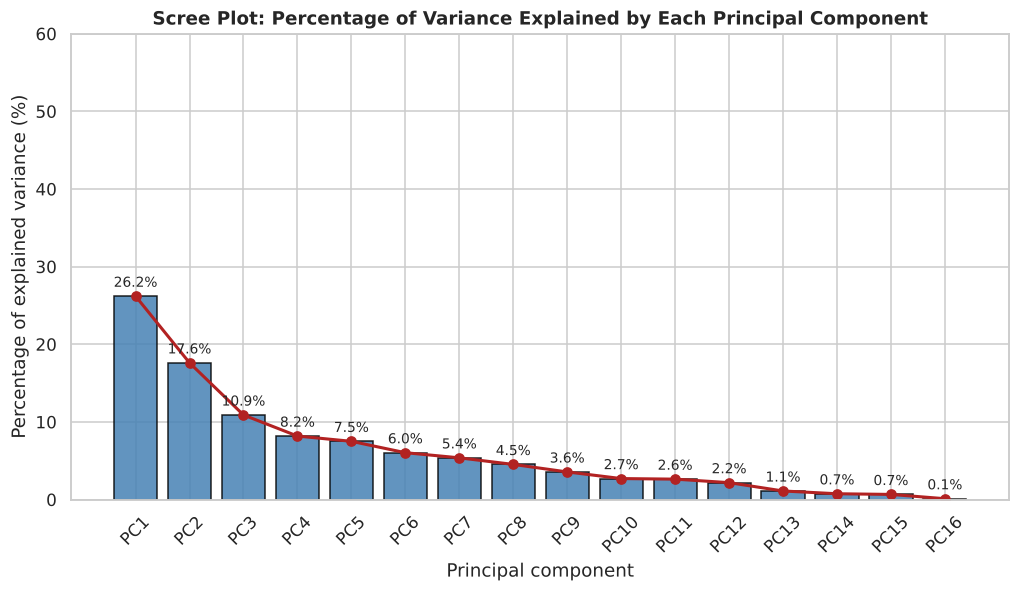

In [153]:
var_pct = 100 * pca.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(range(1, len(var_pct) + 1), var_pct, color="steelblue", edgecolor="black", alpha=0.85)
ax.plot(range(1, len(var_pct) + 1), var_pct, "o-", color="firebrick", lw=2, ms=6)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in var_pct], padding=4, fontsize=9)
ax.set_ylim(0, 60)
ax.set_xticks(range(1, len(var_pct) + 1))
ax.set_xticklabels(pc_names, rotation=45)
ax.set_title("Scree Plot: Percentage of Variance Explained by Each Principal Component")
ax.set_xlabel("Principal component")
ax.set_ylabel("Percentage of explained variance (%)")
plt.show()

### 6. PCA biplot with non-overlapping labels
Points are the observations' scores on PC1 and PC2; arrows are the variable loadings (scaled for visibility). Arrows pointing in the same direction indicate positively correlated variables, opposite arrows indicate negative correlation, and longer arrows mean the variable is better represented by these two PCs. `adjust_text` repositions the labels so none overlap.

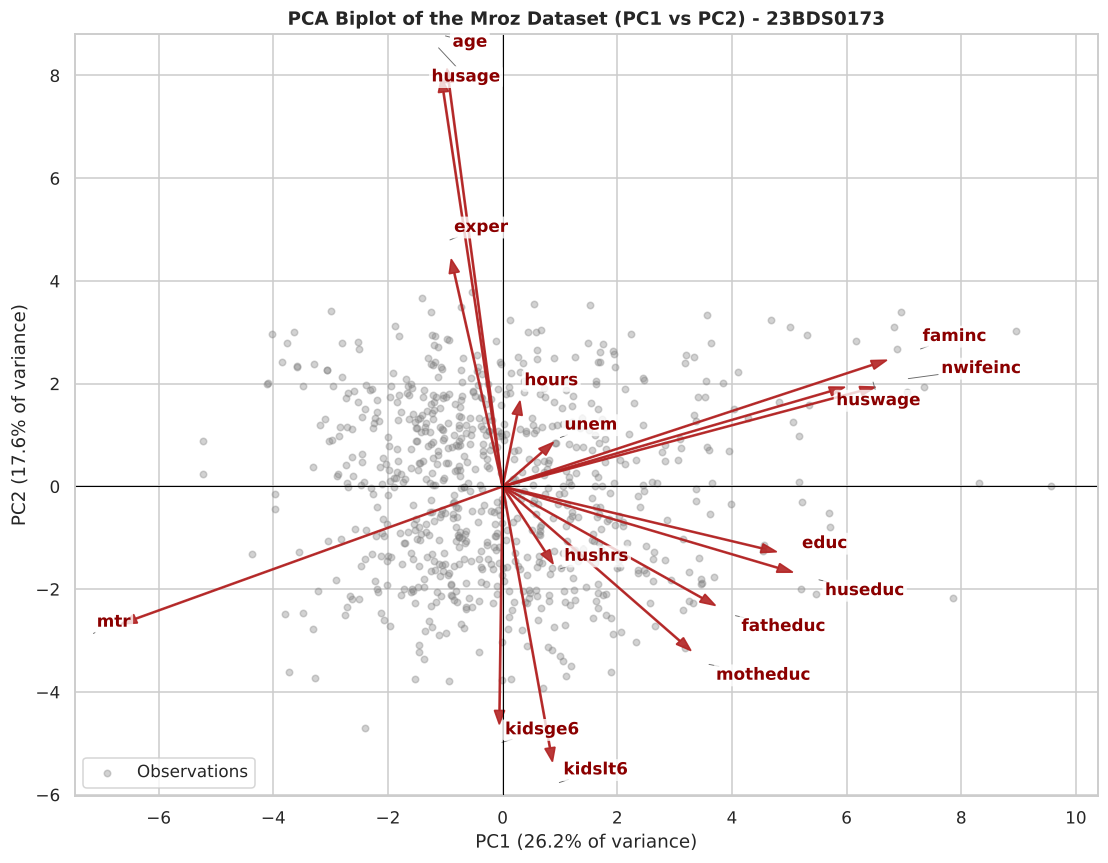

In [154]:
scores = pca.transform(data_scaled)
arrow_scale = np.abs(scores[:, :2]).max() / np.abs(loadings.iloc[:, :2].values).max() * 0.85

fig, ax = plt.subplots(figsize=(12, 9))
ax.scatter(scores[:, 0], scores[:, 1], alpha=0.35, s=18, color="gray", label="Observations")
texts = []
for var in loadings.index:
    x_, y_ = loadings.loc[var, "PC1"] * arrow_scale, loadings.loc[var, "PC2"] * arrow_scale
    ax.arrow(0, 0, x_, y_, color="firebrick", width=0.02, head_width=0.18, length_includes_head=True, alpha=0.9)
    texts.append(ax.text(x_ * 1.08, y_ * 1.08, var, fontsize=11, fontweight="bold", color="darkred",
                         bbox={"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none", "alpha": 0.8}))
adjust_text(texts, ax=ax, arrowprops={"arrowstyle": "-", "color": "dimgray", "lw": 0.6},
            expand=(1.3, 1.5), force_text=(0.6, 0.8))
ax.axhline(0, color="black", lw=0.7)
ax.axvline(0, color="black", lw=0.7)
ax.set_title(f"PCA Biplot of the Mroz Dataset (PC1 vs PC2) - {REG_NO}")
ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}% of variance)")
ax.legend(loc="lower left")
plt.show()

**Interpretation.** The income arrows (`faminc`, `nwifeinc`, `huswage`) point together to the right along PC1, and `mtr` points in the opposite direction, confirming their strong negative correlation. The education arrows (`educ`, `huseduc`, `motheduc`, `fatheduc`) also point right but downward. `age` and `husage` are almost identical arrows pointing up PC2, while `kidslt6` and `kidsge6` point down – age and children at home are opposite ends of the life-cycle axis. Short arrows such as `unem`, `hours` and `hushrs` are poorly represented by the first two components.

### 7. PCA scores in `pca_scores` – first six rows

In [155]:
pca_scores = pd.DataFrame(scores, columns=pc_names, index=data_scaled.index)
print("pca_scores shape:", pca_scores.shape)
pca_scores.head(6)

pca_scores shape: (753, 16)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
0,-0.9034,-1.9204,1.2853,1.4206,-0.1349,1.7002,-0.0321,-0.8931,-0.2025,-0.0838,-0.7353,-0.3385,0.1258,0.2682,-0.0463,0.0130
1,-0.2599,-1.4134,-0.7068,1.2358,-1.6541,-0.9187,0.2288,-0.8042,-1.1182,0.0925,0.0560,0.9014,0.3679,0.1117,0.2820,-0.2171
2,-0.6315,-1.8789,0.8482,2.1934,0.1869,0.2136,0.2522,-0.2788,1.2950,-0.7577,-0.4782,-0.6395,0.4100,-0.0889,-0.1757,0.1314
3,-2.5742,-0.8318,-0.3748,0.1491,0.2242,-0.5044,-0.9898,1.2320,0.1765,-0.5113,0.2324,0.5921,0.1632,-0.3232,-1.2699,-0.0899
4,1.6710,-2.3579,0.7291,0.0546,-1.2901,0.0746,-0.4182,-0.9917,0.2865,-0.4752,0.5811,0.3519,0.4036,-0.1669,0.2727,0.0334
5,-1.1244,2.7076,2.7149,-0.3074,-1.4844,0.4609,-1.0430,0.0233,1.3079,0.0001,-1.2384,-0.5084,-0.1357,-0.1682,-0.1200,0.0500


In [156]:
print("Correlation between PC scores is ~0 (components are uncorrelated):")
print(pca_scores.iloc[:, :4].corr().round(6))

Correlation between PC scores is ~0 (components are uncorrelated):
        PC1     PC2     PC3    PC4
PC1  1.0000  0.0000 -0.0000 0.0000
PC2  0.0000  1.0000 -0.0000 0.0000
PC3 -0.0000 -0.0000  1.0000 0.0000
PC4  0.0000  0.0000  0.0000 1.0000


### 8. Scatter plot of PC1 vs PC2 (blue circular points, registration number in title)

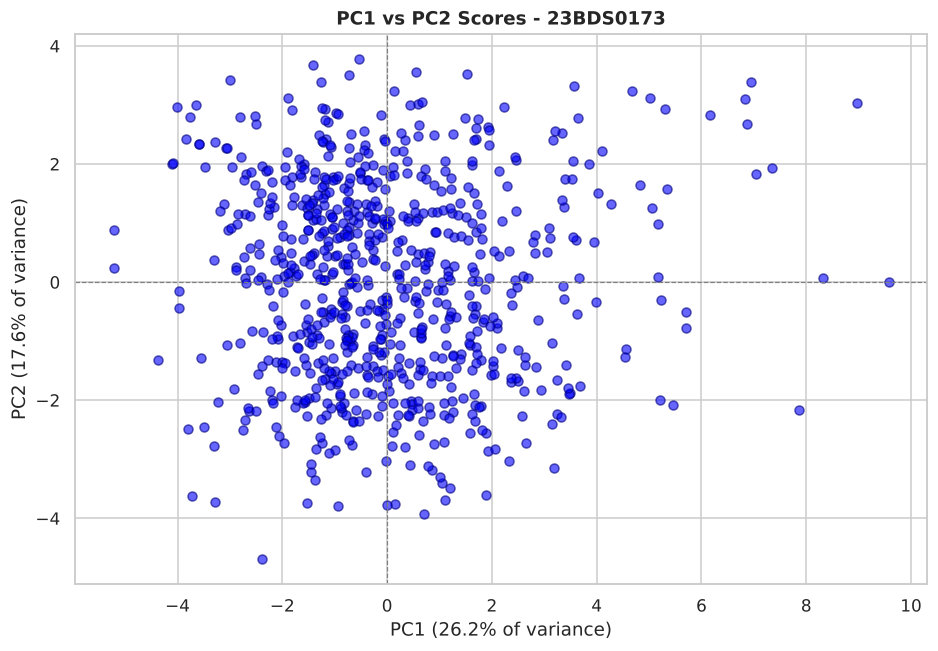

In [157]:
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(pca_scores["PC1"], pca_scores["PC2"], color="blue", marker="o", s=35, alpha=0.6, edgecolor="navy")
ax.axhline(0, color="gray", lw=0.8, ls="--")
ax.axvline(0, color="gray", lw=0.8, ls="--")
ax.set_title(f"PC1 vs PC2 Scores - {REG_NO}")
ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}% of variance)")
plt.show()

**Interpretation.** The scores form a single continuous cloud centred at (0, 0) with no clearly separated groups, consistent with the low silhouette values in Assessment 8. Spread along PC1 (household income/education) is larger than along PC2 (age/children), as expected from their variances. A handful of observations far to the right (PC1 > 6) are the high-income families identified as outliers earlier; women at the top of the plot are older with no children at home, and those at the bottom are young mothers.

---
# Conclusion
Across the nine assessments, the Mroz data were imported, merged-table concepts and scaling methods were demonstrated, genuine missing values in `wage`/`lwage` were handled with several imputation strategies, and univariate, bivariate and multivariate patterns were explored. The recurring substantive findings are consistent from every angle: having **children under six** sharply lowers a married woman's labour-force participation, **education** raises both participation and wages, and **family income** is driven mainly by the **husband's wage**. Clustering and PCA confirmed that the numerical variables are organised around a few underlying dimensions – life-cycle stage (age, children), education/socio-economic status and household income.

**Sai Siddhanth · 23BDS0173**